# Rambla SA — Perfiles de riesgo del inversor uruguayo y carteras modelo

**Proyecto Final C · Programación Analítica II · Universidad de Montevideo**
Segundo semestre 2026 · Docente: Camila Palomeque
Autora: Priscila Gerlach

---

## El encargo

Rambla SA asigna el perfil de riesgo de sus ~640 clientes preguntándoselo directamente:
*«¿usted se considera conservador, moderado o agresivo?»*. Con esa respuesta le arma la
cartera. El gerente de asesoramiento desconfía del método, y con razón: **la gente se
describe como quiere que la vean, no como se comporta.**

> «Quiero saber cuántos clientes tienen una cartera que no se parece a lo que dijeron ser,
> y quiénes son. Ahí adentro está nuestro próximo juicio.»

Este notebook responde eso en cinco etapas:

| Etapa | Pregunta |
|---|---|
| **1** | ¿Los datos sirven? Auditoría y corrección de calidad |
| **2** | ¿Qué hicieron realmente? Cartera efectiva y riesgo efectivo |
| **3** | ¿Cuánto se parece lo que dicen a lo que hacen? |
| **4** | ¿Cómo se ve? Visualización |
| **5** | ¿Qué proponemos? Perfiles nuevos y carteras modelo |

Fecha de corte de todos los datos: **30 de junio de 2026**.

---
# 0 · Configuración

Imports, opciones de visualización y rutas. Nada de análisis todavía.

In [1]:
"""Dependencias y configuración de visualización."""

from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

# Mostrar las tablas completas: con 31 columnas, el truncado por defecto esconde
# justamente las columnas que hay que auditar.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)



def formato_numero(valor: float) -> str:
    """Dos decimales para montos, cuatro para tantos por uno.

    El catálogo expresa retornos y volatilidades en tanto por uno (0,085 = 8,5 %):
    con dos decimales un 0,085 se vería como 0,09 y una volatilidad de 0,005 como 0,01.
    """
    return f"{valor:.4f}" if 0 < abs(valor) < 1 else f"{valor:,.2f}"


pd.set_option("display.float_format", formato_numero)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 3.0.3 | numpy 2.4.6


In [2]:
"""Rutas del proyecto, resueltas desde la ubicación del notebook.

Se busca hacia arriba la carpeta que contiene `datos/`, así el notebook corre
igual desde `notebooks/` o desde la raíz del repositorio.
"""


def encontrar_raiz_proyecto(ancla: str = "datos/encuesta_inversores.csv") -> Path:
    """Devuelve la primera carpeta, desde el directorio actual hacia arriba, que contiene el ancla."""
    for carpeta in (Path.cwd(), *Path.cwd().parents):
        if (carpeta / ancla).exists():
            return carpeta
    raise FileNotFoundError(
        f"No encontré '{ancla}' desde {Path.cwd()}. "
        "Corré el notebook dentro del repositorio, respetando su estructura."
    )


RAIZ = encontrar_raiz_proyecto()
DATOS = RAIZ / "datos"
SALIDAS = RAIZ / "salidas"
SALIDAS.mkdir(exist_ok=True)

# Toda la información está cortada a esta fecha: cualquier fecha posterior es un error.
FECHA_CORTE = pd.Timestamp("2026-06-30")

print(f"Raíz del proyecto : {RAIZ}")
print(f"Datos de entrada  : {DATOS}")
print(f"Salidas           : {SALIDAS}")

Raíz del proyecto : C:\Users\prisc\Downloads\prog analitica II\proyecto-final-gerlach
Datos de entrada  : C:\Users\prisc\Downloads\prog analitica II\proyecto-final-gerlach\datos
Salidas           : C:\Users\prisc\Downloads\prog analitica II\proyecto-final-gerlach\salidas


---
# Etapa 1 · Análisis exploratorio y correcciones de calidad

La consigna avisa que la encuesta se llenó en un formulario sin validaciones y que el
registro de operaciones nunca se concilió contra ella. Antes de calcular nada, hay que
saber **de qué tamaño es el problema**.

**Regla de esta etapa:** cada vez que se borre, impute o modifique algo, se reporta el
porcentaje de la base afectado antes y después, y se justifica la decisión.

Para que eso no quede en prosa, el registro es automático: toda transformación pasa por la
función `registrar_decision()` y al final de la etapa se imprime la bitácora completa.

## 1.1 · Carga declarando tipos y fechas

Tres decisiones antes de leer una sola fila:

1. **Los identificadores se leen como texto, no como número.** `id_cliente` es una
   etiqueta: promediarlo no significa nada y leerlo como entero invita a errores al unir
   tablas.
2. **Las columnas numéricas sucias se leen como texto y se parsean después.** Si se deja
   que pandas infiera, `"$ 131.300"` y `"22.000,00"` quedan en `NaN` sin aviso y se pierde
   el 43 % de los ingresos sin enterarse.
3. **Las fechas se parsean por patrón, no con `format="mixed"`.** Este archivo trae dos
   formatos mezclados y `format="mixed"` con `dayfirst=True` los confunde: deja 101
   encuestas fechadas *después* de la fecha de corte. Se separa por expresión regular y se
   le da a cada grupo su formato explícito.

In [3]:
"""Utilidades de parseo. Se definen una vez y se reutilizan en toda la etapa."""

# Formas de decir "no contestó" que isna() NO detecta, porque llegan como texto.
CENTINELAS_TEXTO = frozenset({
    "", "-", "--", "?", "n/a", "na", "ns/nc", "prefiero no contestar", "s/d", "sin dato",
})

# Centinelas numéricos: códigos que el formulario grabó como si fueran un valor.
CENTINELA_NO_CONTESTA = -999      # ingreso y patrimonio
CENTINELA_TEST_NO_RENDIDO = -1    # puntaje del test de conocimiento
CENTINELA_INGRESO_VACIO = 0       # ingreso: el formulario grabó 0 al dejar el campo vacío

PATRON_FECHA_ISO = r"^\d{4}-\d{2}-\d{2}$"


def parsear_fechas_mixtas(serie: pd.Series) -> pd.Series:
    """Parsea una serie de fechas que mezcla 'yyyy-mm-dd' con 'dd/mm/yyyy'.

    Se separa por patrón y se parsea cada grupo con su formato explícito. Esto evita el
    error silencioso de `format="mixed"`, que interpreta algunas fechas al revés.
    """
    texto = serie.astype("string").str.strip()
    es_iso = texto.str.match(PATRON_FECHA_ISO).fillna(False)

    fechas = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")
    fechas[es_iso] = pd.to_datetime(texto[es_iso], format="%Y-%m-%d", errors="coerce")
    fechas[~es_iso] = pd.to_datetime(texto[~es_iso], format="%d/%m/%Y", errors="coerce")
    return fechas


def a_numero_uruguayo(serie: pd.Series) -> pd.Series:
    """Convierte a número texto escrito con convenciones locales.

    Maneja: símbolo de peso y espacios (`"$ 131.300"`), punto como separador de miles
    (`"131.300"`), coma como separador decimal (`"22.000,00"`) y los centinelas de texto.
    Los centinelas numéricos (-999, -1) se dejan pasar acá y se tratan aparte, para poder
    contarlos antes de borrarlos.
    """
    s = serie.astype("string").str.strip()
    s = s.mask(s.str.lower().isin(CENTINELAS_TEXTO))          # "S/D" -> <NA>
    s = s.str.replace(r"[$\s]", "", regex=True)               # "$ 131.300" -> "131.300"

    # "22.000,00": el punto es miles y la coma es decimal.
    tiene_ambos = s.str.contains(r"\.", na=False) & s.str.contains(",", na=False)
    s = s.mask(tiene_ambos, s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))

    # "22000,50": sólo coma, es el decimal.
    s = s.mask(s.str.contains(",", na=False), s.str.replace(",", ".", regex=False))

    # "131.300": puntos cada tres dígitos y sin cero adelante -> separador de miles.
    # El `[1-9]` inicial es clave: evita destrozar un decimal legítimo como "0.085".
    es_miles = s.str.match(r"^-?[1-9]\d{0,2}(\.\d{3})+$", na=False)
    s = s.mask(es_miles, s.str.replace(".", "", regex=False))

    return pd.to_numeric(s, errors="coerce")


def limpiar_texto(serie: pd.Series) -> pd.Series:
    """Quita espacios de los bordes y colapsa espacios internos repetidos."""
    return (serie.astype("string")
                 .str.strip()
                 .str.replace(r"\s+", " ", regex=True)
                 .replace("", pd.NA))


print("Utilidades de parseo definidas.")

Utilidades de parseo definidas.


In [4]:
"""Bitácora de decisiones: cumple la regla de reportar el impacto de cada cambio."""

BITACORA: list[dict] = []


def registrar_decision(paso: str, columna: str, afectadas: int, universo: int,
                       decision: str, motivo: str) -> None:
    """Anota una transformación con su impacto sobre la base y la imprime."""
    pct = afectadas / universo * 100 if universo else 0.0
    BITACORA.append({
        "paso": paso, "columna": columna, "filas_afectadas": afectadas,
        "universo": universo, "pct_base": round(pct, 2),
        "decision": decision, "motivo": motivo,
    })
    print(f"  [{paso}] {columna}: {afectadas} de {universo} filas ({pct:.2f} %) -> {decision}")


print("Bitácora inicializada.")

Bitácora inicializada.


In [5]:
"""Carga de los cuatro archivos con tipos declarados explícitamente."""

# Columnas numéricas que llegan sucias: se leen como texto y se parsean a mano.
_SUCIAS = ["edad", "ingreso_mensual_liquido", "patrimonio_invertible_usd",
           "meses_gastos_cubiertos", "anios_experiencia_invirtiendo",
           "puntaje_test_conocimiento"]

TIPOS_ENCUESTA = {"id_cliente": "string", **{c: "string" for c in _SUCIAS},
                  "cantidad_dependientes": "Int64", "conocimiento_autopercibido": "Int64",
                  **{f"prioridad_{p}": "Int64" for p in
                     ["plazo_fijo", "letras_bcu", "fondos_locales", "obligaciones",
                      "etf_exterior", "inmuebles", "criptomonedas"]}}

TIPOS_MOVIMIENTOS = {"id_movimiento": "string", "id_cliente": "string",
                     "id_instrumento": "Int64", "tipo_operacion": "string",
                     "moneda": "string", "monto": "string"}

TIPOS_CATALOGO = {"id_instrumento": "Int64", "nombre_instrumento": "string",
                  "categoria": "string", "moneda": "string",
                  "inversion_minima": "float64", "retorno_anual_historico": "float64",
                  "volatilidad_anual": "float64", "nivel_riesgo": "Int64",
                  "liquidez": "string"}

encuesta_cruda = pd.read_csv(DATOS / "encuesta_inversores.csv", dtype=TIPOS_ENCUESTA)
movimientos_crudos = pd.read_csv(DATOS / "movimientos_cartera.csv", dtype=TIPOS_MOVIMIENTOS)
catalogo = pd.read_csv(DATOS / "catalogo_instrumentos.csv", dtype=TIPOS_CATALOGO)
tasas = pd.read_csv(DATOS / "tasas_referencia.csv", dtype={"concepto": "string", "unidad": "string"},
                    parse_dates=["fecha"])

# Las fechas, por patrón (ver justificación arriba).
encuesta_cruda["fecha_respuesta"] = parsear_fechas_mixtas(encuesta_cruda["fecha_respuesta"])
movimientos_crudos["fecha_operacion"] = parsear_fechas_mixtas(movimientos_crudos["fecha_operacion"])

for nombre, tabla in [("encuesta", encuesta_cruda), ("movimientos", movimientos_crudos),
                      ("catálogo", catalogo), ("tasas", tasas)]:
    print(f"{nombre:12s} {tabla.shape[0]:>5d} filas x {tabla.shape[1]:>2d} columnas")

encuesta       657 filas x 31 columnas
movimientos   4481 filas x  7 columnas
catálogo        14 filas x  9 columnas
tasas            8 filas x  4 columnas


In [6]:
"""Primeras filas de cada archivo, para verificar que cargó lo que se esperaba."""

print("=" * 100, "\nENCUESTA — primeras filas (subconjunto de columnas, son 31)\n", "=" * 100)
display(encuesta_cruda[["id_cliente", "fecha_respuesta", "edad", "departamento",
                        "ingreso_mensual_liquido", "patrimonio_invertible_usd",
                        "perfil_autodeclarado", "retorno_esperado_anual"]].head())

print("=" * 100, "\nMOVIMIENTOS — primeras filas\n", "=" * 100)
display(movimientos_crudos.head())

print("=" * 100, "\nCATÁLOGO — las 14 filas, es la tabla de referencia del proyecto\n", "=" * 100)
display(catalogo)

print("=" * 100, "\nTASAS DE REFERENCIA — al 30/06/2026\n", "=" * 100)
display(tasas)

ENCUESTA — primeras filas (subconjunto de columnas, son 31)


,id_cliente,fecha_respuesta,edad,departamento,ingreso_mensual_liquido,patrimonio_invertible_usd,perfil_autodeclarado,retorno_esperado_anual
0,20504,2026-06-24,52.0,Montevideo,141700,4200.0,Conservador,10% a 20%
1,20466,2026-03-29,62.0,Colonia,$ 131.300,13900.0,Moderado,Menos de 5%
2,20432,2026-01-11,40.0,Maldonado,53700,4600.0,moderado,5% a 10%
3,20052,2026-02-21,48.0,Canelones,0,27700.0,Conservador,Menos de 5%
4,20084,2026-04-01,82.0,Canelones,85100,12100.0,CONSERVADOR,5% a 10%


MOVIMIENTOS — primeras filas


,id_movimiento,id_cliente,id_instrumento,fecha_operacion,tipo_operacion,moneda,monto
0,700954,20141,4,2023-08-06,Compra,UI,17803.22
1,700912,20135,5,2023-11-28,Suscripción,UYU,46255.68
2,700236,20033,3,2025-02-26,Suscripción,UYU,39224.29
3,700992,20148,8,2023-12-09,Suscripción,UYU,195561.19
4,701697,20255,12,2024-05-17,Compra,USD,4324.05


CATÁLOGO — las 14 filas, es la tabla de referencia del proyecto


,id_instrumento,nombre_instrumento,categoria,moneda,inversion_minima,retorno_anual_historico,volatilidad_anual,nivel_riesgo,liquidez
0,1,Plazo fijo en pesos (BROU),Renta fija local,UYU,"1,000.00",0.0850,0.0050,1,Baja
1,2,Plazo fijo en dólares,Renta fija local,USD,500.00,0.0330,0.0040,1,Baja
2,3,Letras de Regulación Monetaria (BCU),Renta fija local,UYU,"50,000.00",0.0920,0.0130,1,Media
3,4,Notas del Tesoro en Unidades Indexadas,Renta fija local,UI,"30,000.00",0.0310,0.0260,2,Media
4,5,Fondo de inversión local (AFISA),Fondos,UYU,"20,000.00",0.0710,0.0410,2,Alta
5,6,Obligaciones negociables (BVM),Renta fija corporativa,USD,"5,000.00",0.0650,0.0580,3,Baja
6,7,Fideicomiso financiero,Renta fija corporativa,UI,"40,000.00",0.0790,0.0720,3,Muy baja
7,8,Ahorro voluntario en AFAP,Previsional,UYU,"2,000.00",0.0490,0.0610,3,Muy baja
8,9,ETF de índice global (S&P 500 / MSCI World),Renta variable,USD,"1,000.00",0.0940,0.1520,4,Alta
9,10,Acciones individuales del exterior,Renta variable,USD,500.00,0.1010,0.2430,5,Alta


TASAS DE REFERENCIA — al 30/06/2026


,concepto,valor,unidad,fecha
0,"Inflación anual Uruguay (IPC, últimos 12 meses)",5.40,%,2026-06-30
1,Meta de inflación del BCU (centro del rango),4.50,%,2026-06-30
2,Tasa de política monetaria del BCU,8.75,%,2026-06-30
3,Tipo de cambio peso / dólar,42.80,UYU por USD,2026-06-30
4,Valor de la Unidad Indexada,6.55,UYU por UI,2026-06-30
5,Rendimiento de la Letra de Regulación Monetari...,9.20,%,2026-06-30
6,Inflación anual de Estados Unidos,2.70,%,2026-06-30
7,Rendimiento del bono del Tesoro de EE.UU. a 10...,4.10,%,2026-06-30


In [7]:
"""Verificación de la carga: ¿quedó algo mal parseado en silencio?"""

print("--- Fechas ---")
for nombre, serie in [("encuesta.fecha_respuesta", encuesta_cruda["fecha_respuesta"]),
                      ("movimientos.fecha_operacion", movimientos_crudos["fecha_operacion"])]:
    posteriores = int((serie > FECHA_CORTE).sum())
    print(f"{nombre:30s} nulos={serie.isna().sum():>3d} | "
          f"{serie.min().date()} -> {serie.max().date()} | posteriores al corte: {posteriores}")

print("\n--- Tipos declarados ---")
print(encuesta_cruda.dtypes.value_counts().to_string())

print("\n--- Control de integridad referencial ---")
instrumentos_validos = set(catalogo["id_instrumento"])
fuera = ~movimientos_crudos["id_instrumento"].isin(instrumentos_validos)
print(f"Movimientos con id_instrumento fuera del catálogo: {int(fuera.sum())}")
print(f"Instrumentos del catálogo sin ninguna operación : "
      f"{len(instrumentos_validos - set(movimientos_crudos['id_instrumento'].dropna()))}")

--- Fechas ---


encuesta.fecha_respuesta       nulos=  0 | 2026-01-02 -> 2026-06-30 | posteriores al corte: 0
movimientos.fecha_operacion    nulos=  0 | 2022-07-02 -> 2026-05-31 | posteriores al corte: 0

--- Tipos declarados ---
str               14
Int64              9
string             7
datetime64[ns]     1

--- Control de integridad referencial ---
Movimientos con id_instrumento fuera del catálogo: 0
Instrumentos del catálogo sin ninguna operación : 0


**Verificación superada.** Con el parseo por patrón no queda ninguna fecha nula ni ninguna
posterior al 30/06/2026, los 14 instrumentos del catálogo aparecen en el registro y no hay
operaciones apuntando a instrumentos inexistentes. Las fechas confirman el relato del caso:
la encuesta es del primer semestre de 2026 y las operaciones cubren desde julio de 2022.

## 1.2 · Panorama general

Filas, columnas, tipos, cardinalidad de las categóricas y descripción de las continuas.

In [8]:
"""Panorama estructural de cada tabla."""


def describir_estructura(tabla: pd.DataFrame, nombre: str) -> pd.DataFrame:
    """Devuelve una fila por columna con tipo, no nulos, nulos, % nulos y valores únicos."""
    resumen = pd.DataFrame({
        "tipo": tabla.dtypes.astype("string"),
        "no_nulos": tabla.notna().sum(),
        "nulos": tabla.isna().sum(),
        "pct_nulos": (tabla.isna().mean() * 100).round(2),
        "unicos": tabla.nunique(dropna=True),
    })
    resumen.index.name = f"{nombre} ({tabla.shape[0]}x{tabla.shape[1]})"
    return resumen


display(describir_estructura(encuesta_cruda, "encuesta"))
display(describir_estructura(movimientos_crudos, "movimientos"))

,tipo,no_nulos,nulos,pct_nulos,unicos
encuesta (657x31),,,,,
id_cliente,string,657,0,0.00,640
fecha_respuesta,datetime64[ns],657,0,0.00,180
edad,string,651,6,0.9100,59
sexo,str,657,0,0.00,2
departamento,str,657,0,0.00,25
cantidad_dependientes,Int64,657,0,0.00,6
nivel_educativo,str,657,0,0.00,4
ocupacion,str,657,0,0.00,6
ingreso_mensual_liquido,string,643,14,2.13,537


,tipo,no_nulos,nulos,pct_nulos,unicos
movimientos (4481x7),,,,,
id_movimiento,string,4481,0,0.00,4481
id_cliente,string,4481,0,0.00,706
id_instrumento,Int64,4481,0,0.00,14
fecha_operacion,datetime64[ns],4481,0,0.00,1353
tipo_operacion,string,4481,0,0.00,2
moneda,string,4481,0,0.00,3
monto,string,4429,52,1.16,1738


In [9]:
"""Cardinalidad de las categóricas: dónde hay más categorías de las que debería haber."""

COLUMNAS_CATEGORICAS = [
    "sexo", "departamento", "nivel_educativo", "ocupacion", "tiene_deudas",
    "tiene_fondo_emergencia", "perfil_autodeclarado", "tolerancia_perdida_maxima",
    "horizonte_inversion", "frecuencia_monitoreo", "retorno_esperado_anual",
    "reaccion_caida_20", "objetivo_principal", "fuente_informacion",
]

# Cuántas categorías DEBERÍA tener cada variable según el diccionario de datos.
CATEGORIAS_ESPERADAS = {
    "sexo": 2, "departamento": 19, "nivel_educativo": 4, "ocupacion": 6,
    "tiene_deudas": 2, "tiene_fondo_emergencia": 2, "perfil_autodeclarado": 3,
    "tolerancia_perdida_maxima": 5, "horizonte_inversion": 4, "frecuencia_monitoreo": 5,
    "retorno_esperado_anual": 5, "reaccion_caida_20": 4, "objetivo_principal": 6,
    "fuente_informacion": 6,
}

cardinalidad = pd.DataFrame({
    "observadas": encuesta_cruda[COLUMNAS_CATEGORICAS].nunique(),
    "esperadas": pd.Series(CATEGORIAS_ESPERADAS),
})
cardinalidad["exceso"] = cardinalidad["observadas"] - cardinalidad["esperadas"]
display(cardinalidad.sort_values("exceso", ascending=False))

print("\nVariables con categorías de más (= misma respuesta escrita de varias maneras):")
for columna in cardinalidad.index[cardinalidad["exceso"] > 0]:
    print(f"\n[{columna}]")
    print(encuesta_cruda[columna].value_counts(dropna=False).to_string())

,observadas,esperadas,exceso
departamento,25,19,6
perfil_autodeclarado,6,3,3
fuente_informacion,9,6,3
frecuencia_monitoreo,8,5,3
horizonte_inversion,7,4,3
tiene_fondo_emergencia,4,2,2
tiene_deudas,2,2,0
ocupacion,6,6,0
nivel_educativo,4,4,0
sexo,2,2,0



Variables con categorías de más (= misma respuesta escrita de varias maneras):

[departamento]
departamento
Montevideo        264
Canelones          80
Maldonado          61
MONTEVIDEO         46
Colonia            26
Paysandú           23
Salto              22
Canelones          17
Rivera             14
Rocha              13
San José           13
Tacuarembó         13
Soriano            13
Florida             8
Lavalleja           8
Cerro Largo         7
Río Negro           6
Treinta y Tres      4
San Jose            4
Rio Negro           3
Durazno             3
Flores              3
Tacuarembo          2
Artigas             2
Paysandu            2

[tiene_fondo_emergencia]
tiene_fondo_emergencia
No    317
Sí    271
NO     39
SI     30

[perfil_autodeclarado]
perfil_autodeclarado
Conservador    285
Moderado       157
Agresivo       127
CONSERVADOR     42
moderado        30
Agresivo        16

[horizonte_inversion]
horizonte_inversion
1 a 3 años        194
3 a 5 años        167
Más de

In [10]:
"""Descripción estadística de las continuas.

Se parsean al vuelo para poder describirlas: sin parsear, `describe()` no las ve.
Los centinelas (-999, -1) siguen adentro a propósito: se ven en el mínimo.
"""

COLUMNAS_CONTINUAS = ["edad", "ingreso_mensual_liquido", "patrimonio_invertible_usd",
                      "meses_gastos_cubiertos", "anios_experiencia_invirtiendo",
                      "puntaje_test_conocimiento", "cantidad_dependientes",
                      "conocimiento_autopercibido"]

continuas = encuesta_cruda[COLUMNAS_CONTINUAS].apply(a_numero_uruguayo)
display(continuas.describe().T)

print("MOVIMIENTOS — monto por moneda (sin convertir todavía: no son comparables)")
montos = pd.DataFrame({"moneda": movimientos_crudos["moneda"],
                       "monto": a_numero_uruguayo(movimientos_crudos["monto"])})
display(montos.groupby("moneda")["monto"].describe())

,count,mean,std,min,25%,50%,75%,max
edad,651.00,46.64,14.06,0.00,38.00,46.00,53.50,154.00
ingreso_mensual_liquido,617.00,"85,614.28","60,280.64",-999.00,"46,900.00","71,700.00","109,900.00","535,900.00"
patrimonio_invertible_usd,628.00,"24,964.99","29,705.02",-999.00,"7,400.00","15,900.00","31,650.00","279,100.00"
meses_gastos_cubiertos,624.00,2.93,3.93,0.00,0.00,0.00,6.00,12.00
anios_experiencia_invirtiendo,657.00,5.38,4.70,0.00,2.00,4.00,7.00,34.00
puntaje_test_conocimiento,657.00,4.30,2.06,-1.00,3.00,4.00,6.00,10.00
cantidad_dependientes,657.00,0.9072,0.9558,0.00,0.00,1.00,1.00,5.00
conocimiento_autopercibido,657.00,2.56,0.9982,1.00,2.00,3.00,3.00,5.00


MOVIMIENTOS — monto por moneda (sin convertir todavía: no son comparables)


,count,mean,std,min,25%,50%,75%,max
moneda,,,,,,,,
UI,831.00,"19,212.19","32,289.48","-21,478.63","4,357.52","9,375.69","19,409.11","419,665.76"
USD,"1,664.00","3,524.36","6,453.51","-10,651.22",639.19,"1,585.84","3,548.29","92,578.57"
UYU,"1,934.00","108,542.47","218,319.16","-718,329.50","19,142.84","42,716.68","115,281.62","5,317,319.60"


**Lo que ya se ve en esta tabla:**

- `edad` va de **0 a 154 años**: hay valores imposibles.
- `ingreso_mensual_liquido` y `patrimonio_invertible_usd` tienen **mínimo −999**: un
  centinela de «no contestó» disfrazado de número, que `isna()` no detecta.
- `puntaje_test_conocimiento` tiene **mínimo −1** cuando la escala es 0 a 10: otro
  centinela, en este caso «no rindió el test».
- Seis variables categóricas tienen **más categorías de las que existen**: la misma
  respuesta escrita de varias maneras.
- Los montos están en **tres monedas sin convertir**, con mínimos negativos en las tres.

## 1.3 · Dos problemas distintos de duplicados

La consigna avisa que el formulario enviado dos veces y la operación registrada dos veces
**no son el mismo problema**, y acá se confirma por qué:

- En la **encuesta** el duplicado es *detectable por fila idéntica*: el mismo cliente
  manda el formulario dos veces y las 31 respuestas coinciden.
- En los **movimientos** no hay ninguna fila idéntica ni ningún `id_movimiento` repetido,
  porque el sistema le asigna un identificador nuevo a cada registro. El duplicado hay que
  buscarlo por **clave de negocio**: mismo cliente, mismo instrumento, misma fecha, mismo
  tipo, misma moneda y mismo monto al centavo.

In [11]:
"""Duplicados en la encuesta: formularios enviados dos veces."""

filas_antes = len(encuesta_cruda)
ids_repetidos = encuesta_cruda["id_cliente"].duplicated(keep=False)

print(f"Filas totalmente idénticas          : {int(encuesta_cruda.duplicated().sum())}")
print(f"Filas con id_cliente repetido       : {int(ids_repetidos.sum())}")
print(f"Clientes únicos                     : {encuesta_cruda['id_cliente'].nunique()}")

# Control clave: ¿algún id repetido contestó cosas DISTINTAS en cada envío?
# Si lo hubiera, no se podría elegir cuál respuesta vale y habría que decidir un criterio.
repetidos = encuesta_cruda[ids_repetidos]
contradictorios = len(repetidos) - int(repetidos.duplicated(keep=False).sum())
print(f"Ids repetidos con respuestas distintas: {contradictorios}")

print("\nEjemplo de un formulario enviado dos veces:")
id_ejemplo = encuesta_cruda.loc[ids_repetidos, "id_cliente"].iloc[0]
display(encuesta_cruda[encuesta_cruda["id_cliente"] == id_ejemplo]
        [["id_cliente", "fecha_respuesta", "edad", "perfil_autodeclarado",
          "ingreso_mensual_liquido", "patrimonio_invertible_usd"]])

encuesta = encuesta_cruda.drop_duplicates().reset_index(drop=True)
registrar_decision(
    paso="1.3", columna="(fila completa)",
    afectadas=filas_antes - len(encuesta), universo=filas_antes,
    decision=f"eliminar duplicados exactos: {filas_antes} -> {len(encuesta)} filas",
    motivo="Mismo id_cliente con las 31 respuestas idénticas = el formulario se envió dos "
           "veces. Al no haber contradicción entre envíos, quedarse con uno no pierde "
           "información. Un id repetido con respuestas distintas habría exigido otro criterio.",
)
assert encuesta["id_cliente"].is_unique, "Debe quedar una fila por cliente"

Filas totalmente idénticas          : 17
Filas con id_cliente repetido       : 34
Clientes únicos                     : 640
Ids repetidos con respuestas distintas: 0

Ejemplo de un formulario enviado dos veces:


,id_cliente,fecha_respuesta,edad,perfil_autodeclarado,ingreso_mensual_liquido,patrimonio_invertible_usd
8,20125,2026-05-03,53.0,Moderado,62600.00,10200.0
252,20125,2026-05-03,53.0,Moderado,62600.00,10200.0


  [1.3] (fila completa): 17 de 657 filas (2.59 %) -> eliminar duplicados exactos: 657 -> 640 filas


In [12]:
"""Duplicados en los movimientos: la misma operación registrada dos veces."""

ops_antes = len(movimientos_crudos)
CLAVE_NEGOCIO = ["id_cliente", "id_instrumento", "fecha_operacion",
                 "tipo_operacion", "moneda", "monto"]

print(f"Filas totalmente idénticas     : {int(movimientos_crudos.duplicated().sum())}")
print(f"id_movimiento repetidos        : {int(movimientos_crudos['id_movimiento'].duplicated().sum())}")

en_grupo_repetido = movimientos_crudos.duplicated(subset=CLAVE_NEGOCIO, keep=False)
print(f"Filas duplicadas por clave de negocio: {int(en_grupo_repetido.sum())} "
      f"({int(en_grupo_repetido.sum()) // 2} operaciones registradas dos veces)")

print("\nEjemplo: dos id_movimiento distintos para la misma operación")
display(movimientos_crudos[en_grupo_repetido].sort_values(CLAVE_NEGOCIO).head(4))

movimientos = (movimientos_crudos
               .sort_values("id_movimiento")
               .drop_duplicates(subset=CLAVE_NEGOCIO, keep="first")
               .reset_index(drop=True))

registrar_decision(
    paso="1.3", columna="(clave de negocio)",
    afectadas=ops_antes - len(movimientos), universo=ops_antes,
    decision=f"eliminar el registro repetido: {ops_antes} -> {len(movimientos)} operaciones",
    motivo="Mismo cliente, instrumento, fecha, tipo, moneda y monto al centavo es la misma "
           "operación cargada dos veces, no dos compras idénticas el mismo día. Dejarlas "
           "duplicaría el monto invertido y por lo tanto el peso de ese instrumento en el "
           "riesgo de la cartera, que es la variable central del proyecto.",
)

Filas totalmente idénticas     : 0
id_movimiento repetidos        : 0
Filas duplicadas por clave de negocio: 188 (94 operaciones registradas dos veces)

Ejemplo: dos id_movimiento distintos para la misma operación


,id_movimiento,id_cliente,id_instrumento,fecha_operacion,tipo_operacion,moneda,monto
1193,704397,20007,12,2025-09-02,Compra,USD,1733.81
3241,700070,20007,12,2025-09-02,Compra,USD,1733.81
269,700109,20013,14,2025-09-27,Compra,USD,173.64
3494,704429,20013,14,2025-09-27,Compra,USD,173.64


  [1.3] (clave de negocio): 94 de 4481 filas (2.10 %) -> eliminar el registro repetido: 4481 -> 4387 operaciones

**Por qué importa el segundo caso.** El riesgo efectivo de la cartera se calcula ponderando
el nivel de riesgo de cada instrumento por el monto invertido. Si 94 operaciones están
contadas dos veces, el peso de esos instrumentos queda inflado al doble y el perfil de esos
clientes sale corrido. Un duplicado en la encuesta sólo agrega una fila; un duplicado en
los movimientos **deforma el resultado**.

## 1.4 · Faltantes por columna

Primero los que `isna()` sí detecta. Los disfrazados vienen en 1.5.

In [13]:
"""Faltantes declarados (los que isna() detecta) por columna."""


def tabla_faltantes(tabla: pd.DataFrame, nombre: str) -> pd.DataFrame:
    """Columnas con al menos un nulo, ordenadas por cantidad."""
    conteo = tabla.isna().sum()
    conteo = conteo[conteo > 0].sort_values(ascending=False)
    return pd.DataFrame({
        "nulos": conteo,
        "pct": (conteo / len(tabla) * 100).round(2),
    }).rename_axis(f"{nombre}: columnas con faltantes")


display(tabla_faltantes(encuesta, "encuesta"))
display(tabla_faltantes(movimientos, "movimientos"))

,nulos,pct
encuesta: columnas con faltantes,,
meses_gastos_cubiertos,31,4.84
patrimonio_invertible_usd,29,4.53
objetivo_principal,26,4.06
reaccion_caida_20,19,2.97
ingreso_mensual_liquido,13,2.03
edad,6,0.9400


,nulos,pct
movimientos: columnas con faltantes,,
monto,52,1.19


In [14]:
"""Las filas afectadas, vistas con un filtro."""

columnas_con_nulos = [c for c in encuesta.columns if encuesta[c].isna().any()]
filas_incompletas = encuesta[encuesta[columnas_con_nulos].isna().any(axis=1)]

print(f"Clientes con al menos un faltante declarado: {len(filas_incompletas)} "
      f"de {len(encuesta)} ({len(filas_incompletas) / len(encuesta):.1%})")
display(filas_incompletas[["id_cliente", *columnas_con_nulos]].head(10))

print("\nOperaciones sin monto (no se pueden usar para reconstruir la cartera):")
display(movimientos[movimientos["monto"].isna()].head(5))

Clientes con al menos un faltante declarado: 113 de 640 (17.7%)


,id_cliente,edad,ingreso_mensual_liquido,patrimonio_invertible_usd,meses_gastos_cubiertos,reaccion_caida_20,objetivo_principal
15,20550,58.0,0,<NA>,0,NaN,Crecimiento del capital
35,20284,<NA>,$ 124.600,0.0,0,No haría nada,Generar una renta mensual
52,20185,38.0,S/D,52800.0,<NA>,Vendería todo,Crecimiento del capital
60,20283,38.0,50300.00,2300.0,11,No haría nada,NaN
62,20388,51.0,<NA>,17200.0,0,No haría nada,Compra de vivienda
76,20514,26.0,$ 386.400,<NA>,0,Compraría más,Crecimiento del capital
78,20355,44.0,24400,2800.0,<NA>,Compraría más,Crecimiento del capital
79,20373,38.0,"69.300,00",<NA>,0,No haría nada,Preservar el capital
81,20058,61.0,118500,<NA>,1,Compraría más,Generar una renta mensual
83,20314,32.0,117900,<NA>,8,No haría nada,Preservar el capital



Operaciones sin monto (no se pueden usar para reconstruir la cartera):


,id_movimiento,id_cliente,id_instrumento,fecha_operacion,tipo_operacion,moneda,monto
121,700122,20015,4,2024-04-23,Compra,UI,<NA>
300,700301,20042,14,2023-08-14,Suscripción,USD,<NA>
306,700307,20045,6,2026-03-13,Compra,USD,<NA>
359,700360,20054,2,2026-05-06,Suscripción,USD,<NA>
596,700597,20088,3,2026-01-05,Compra,UYU,<NA>


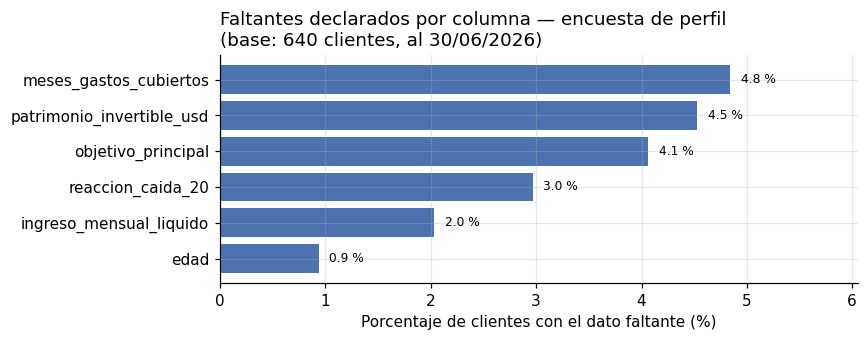

In [15]:
"""Gráfico de apoyo: cuánto falta en cada columna."""

conteo = encuesta.isna().sum()
conteo = conteo[conteo > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(conteo.index, conteo.values / len(encuesta) * 100, color="#4C72B0")
ax.set_xlabel("Porcentaje de clientes con el dato faltante (%)")
ax.set_title("Faltantes declarados por columna — encuesta de perfil\n"
             f"(base: {len(encuesta)} clientes, al 30/06/2026)", loc="left")
for y, valor in enumerate(conteo.values / len(encuesta) * 100):
    ax.text(valor + 0.1, y, f"{valor:.1f} %", va="center", fontsize=8)
ax.set_xlim(0, max(conteo.values / len(encuesta) * 100) * 1.25)
plt.tight_layout()
plt.savefig(SALIDAS / "1_4_faltantes_por_columna.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusión.** Ninguna columna supera el 6 % de faltantes declarados, así que ninguna se
descarta por vacía. Pero el conteo de `isna()` es un piso, no el total: en 1.5 se ve que
hay tres formas más de decir «no contestó» que esta tabla no está viendo.

## 1.5 · Centinelas disfrazados de dato y rangos imposibles

La consigna adelanta que hay **al menos tres formas distintas de decir «no contestó»** y
que `isna()` detecta sólo una. Buscándolas aparecen cuatro:

| Forma | Dónde | Casos | Por qué `isna()` no la ve |
|---|---|---|---|
| `NaN` | 6 columnas | 124 | la única que sí detecta |
| `-999` | ingreso y patrimonio | 22 | es un número válido para pandas |
| `"Prefiero no contestar"` y `"S/D"` | ingreso | 26 | es texto no vacío |
| `-1` | puntaje del test (escala 0 a 10) | 18 | es un número válido para pandas |
| `0` | ingreso líquido mensual | 14 | es un número válido **y plausible** |

El último es el más difícil de ver, porque un ingreso de cero no es absurdo a primera
vista: un estudiante o alguien sin trabajo podría tenerlo. Se verifica abajo **quiénes
son** esos catorce clientes antes de decidir.

In [16]:
"""Búsqueda sistemática de centinelas en todas las columnas."""

hallazgos = []
for columna in encuesta.columns:
    valores = encuesta[columna].astype("string").str.strip()

    texto = int(valores.str.lower().isin(CENTINELAS_TEXTO).sum())
    if texto:
        detalle = valores[valores.str.lower().isin(CENTINELAS_TEXTO)].value_counts().to_dict()
        hallazgos.append({"columna": columna, "tipo": "centinela de texto",
                          "casos": texto, "valores": str(detalle)})

    numerico = a_numero_uruguayo(encuesta[columna])
    for codigo, etiqueta in [(CENTINELA_NO_CONTESTA, "centinela -999"),
                             (CENTINELA_TEST_NO_RENDIDO, "centinela -1")]:
        casos = int((numerico == codigo).sum())
        if casos:
            hallazgos.append({"columna": columna, "tipo": etiqueta,
                              "casos": casos, "valores": str(codigo)})

    # El cero sólo es sospechoso en el ingreso: en meses_gastos_cubiertos o en
    # cantidad_dependientes es un valor perfectamente normal.
    if columna == "ingreso_mensual_liquido":
        casos = int((numerico == CENTINELA_INGRESO_VACIO).sum())
        if casos:
            hallazgos.append({"columna": columna, "tipo": "centinela 0",
                              "casos": casos, "valores": "0"})

    nulos = int(encuesta[columna].isna().sum())
    if nulos:
        hallazgos.append({"columna": columna, "tipo": "NaN declarado",
                          "casos": nulos, "valores": "-"})

display(pd.DataFrame(hallazgos).sort_values(["columna", "tipo"]).reset_index(drop=True))

,columna,tipo,casos,valores
0,edad,NaN declarado,6,-
1,ingreso_mensual_liquido,NaN declarado,13,-
2,ingreso_mensual_liquido,centinela -999,9,-999
3,ingreso_mensual_liquido,centinela 0,14,0
4,ingreso_mensual_liquido,centinela de texto,26,"{'Prefiero no contestar': 18, 'S/D': 8}"
5,meses_gastos_cubiertos,NaN declarado,31,-
6,objetivo_principal,NaN declarado,26,-
7,patrimonio_invertible_usd,NaN declarado,29,-
8,patrimonio_invertible_usd,centinela -999,13,-999
9,puntaje_test_conocimiento,centinela -1,18,-1


In [17]:
"""¿Quiénes son los clientes con ingreso líquido declarado igual a cero?

Si fueran estudiantes o jubilados, el cero podría ser un dato real. Si todos tienen
ocupación activa, es imposible: el cero es un campo vacío que el formulario grabó como
número.
"""

ingreso_numerico = a_numero_uruguayo(encuesta["ingreso_mensual_liquido"])
ingreso_cero = ingreso_numerico == CENTINELA_INGRESO_VACIO

print(f"Clientes con ingreso mensual líquido declarado = 0: {int(ingreso_cero.sum())}\n")
print("Ocupación de esos clientes:")
print(encuesta.loc[ingreso_cero, "ocupacion"].value_counts().to_string())

print("\nPatrimonio invertible que declaran (USD), excluyendo el centinela -999:")
patrimonio_de_esos = a_numero_uruguayo(encuesta.loc[ingreso_cero, "patrimonio_invertible_usd"])
display(patrimonio_de_esos.mask(patrimonio_de_esos == CENTINELA_NO_CONTESTA)
        .describe().to_frame().T)

OCUPACIONES_SIN_INGRESO = ["Estudiante", "Jubilado"]
legitimos = int(encuesta.loc[ingreso_cero, "ocupacion"].isin(OCUPACIONES_SIN_INGRESO).sum())
print(f"De esos clientes, los que podrían legítimamente no tener ingreso "
      f"(Estudiante o Jubilado): {legitimos}")

Clientes con ingreso mensual líquido declarado = 0: 14

Ocupación de esos clientes:
ocupacion
Empresario / dueño de negocio          6
Profesional independiente              3
Empleado en relación de dependencia    3
Empleado público                       2

Patrimonio invertible que declaran (USD), excluyendo el centinela -999:


,count,mean,std,min,25%,50%,75%,max
patrimonio_invertible_usd,12.00,"26,741.67","22,524.07","3,300.00","7,300.00","25,700.00","38,800.00","73,300.00"


De esos clientes, los que podrían legítimamente no tener ingreso (Estudiante o Jubilado): 0


**El cero es un centinela, no un dato.** Los catorce clientes con ingreso declarado en cero
tienen **todos ocupación activa** —seis empresarios, tres profesionales independientes,
tres empleados y dos funcionarios públicos— y declaran un patrimonio invertible mediano de
**USD 25.700**. **Ninguno es estudiante ni jubilado**, que serían los únicos casos donde un
ingreso de cero podría ser cierto. Un empresario con USD 25.700 invertibles y sueldo
líquido de cero pesos no existe: el formulario grabó `0` donde el campo quedó vacío.

**Decisión:** el `0` en `ingreso_mensual_liquido` pasa a faltante. Es la quinta forma de
decir «no contestó» en esta base y la más difícil de detectar, porque sobrevive cualquier
control de rango: *cero está dentro del rango válido de un ingreso.* Se descubre sólo
cruzando la variable contra la ocupación.

In [18]:
"""Rangos imposibles en las numéricas."""

# Rangos admisibles según el diccionario de datos y el sentido del negocio.
# La cota inferior de edad es 18: en Uruguay un menor no puede contratar por sí mismo
# los instrumentos del catálogo, así que una edad menor es un error de carga.
RANGOS_VALIDOS = {
    "edad": (18, 95),
    "ingreso_mensual_liquido": (0, None),
    "patrimonio_invertible_usd": (0, None),
    "meses_gastos_cubiertos": (0, 24),
    "anios_experiencia_invirtiendo": (0, 80),
    "puntaje_test_conocimiento": (0, 10),
    "conocimiento_autopercibido": (1, 5),
    "cantidad_dependientes": (0, 15),
}

filas_control = []
for columna, (minimo, maximo) in RANGOS_VALIDOS.items():
    valores = a_numero_uruguayo(encuesta[columna])
    fuera = pd.Series(False, index=valores.index)
    if minimo is not None:
        fuera |= valores < minimo
    if maximo is not None:
        fuera |= valores > maximo
    filas_control.append({
        "columna": columna, "min_admitido": minimo, "max_admitido": maximo,
        "min_observado": valores.min(), "max_observado": valores.max(),
        "fuera_de_rango": int(fuera.sum()),
    })

display(pd.DataFrame(filas_control).set_index("columna"))

,min_admitido,max_admitido,min_observado,max_observado,fuera_de_rango
columna,,,,,
edad,18,95.00,0.00,154.00,16
ingreso_mensual_liquido,0,NaN,-999.00,"535,900.00",9
patrimonio_invertible_usd,0,NaN,-999.00,"279,100.00",13
meses_gastos_cubiertos,0,24.00,0.00,12.00,0
anios_experiencia_invirtiendo,0,80.00,0.00,34.00,0
puntaje_test_conocimiento,0,10.00,-1.00,10.00,18
conocimiento_autopercibido,1,5.00,1.00,5.00,0
cantidad_dependientes,0,15.00,0.00,5.00,0


In [19]:
"""Las edades imposibles, una por una: ¿son error de tipeo o hay otra explicación?"""

edad_numerica = a_numero_uruguayo(encuesta["edad"])
edad_sospechosa = (edad_numerica < 18) | (edad_numerica > 95)

display(encuesta.loc[edad_sospechosa,
                     ["id_cliente", "edad", "ocupacion", "anios_experiencia_invirtiendo",
                      "patrimonio_invertible_usd", "perfil_autodeclarado"]]
        .sort_values("edad"))

# Control de coherencia interna: nadie puede haber empezado a invertir antes de los 18.
# Es la prueba de que estas edades son errores de carga y no clientes atípicos.
experiencia = a_numero_uruguayo(encuesta["anios_experiencia_invirtiendo"])
edad_al_empezar = edad_numerica - experiencia
incoherente = edad_al_empezar < 18

print("\nClientes que, según sus respuestas, empezaron a invertir antes de los 18 años:")
print(f"  sobre la base cruda                     : {int(incoherente.sum())}")
print(f"  excluyendo las edades fuera de [18, 95] : "
      f"{int((incoherente & ~edad_sospechosa).sum())}")

print("\nLos casos de 16 y 17 años, con su experiencia declarada:")
display(encuesta.loc[edad_numerica.between(16, 17),
                     ["id_cliente", "edad", "ocupacion", "anios_experiencia_invirtiendo"]]
        .assign(edad_al_empezar=edad_al_empezar))

,id_cliente,edad,ocupacion,anios_experiencia_invirtiendo,patrimonio_invertible_usd,perfil_autodeclarado
6,20254,0.0,Jubilado,8.0,12200.0,Conservador
84,20255,0.0,Empleado en relación de dependencia,1.0,39500.0,Conservador
112,20109,0.0,Empleado en relación de dependencia,2.0,38400.0,Conservador
118,20079,0.0,Jubilado,8.0,28100.0,Conservador
386,20053,0.0,Estudiante,3.0,11700.0,Agresivo
414,20586,0.0,Empresario / dueño de negocio,2.0,6900.0,Conservador
501,20519,0.0,Empleado en relación de dependencia,3.0,9500.0,Moderado
511,20068,0.0,Empleado en relación de dependencia,12.0,35800.0,Conservador
100,20062,154.0,Empleado en relación de dependencia,2.0,11400.0,Conservador
125,20266,154.0,Empleado en relación de dependencia,17.0,10400.0,Moderado



Clientes que, según sus respuestas, empezaron a invertir antes de los 18 años:
  sobre la base cruda                     : 14
  excluyendo las edades fuera de [18, 95] : 0

Los casos de 16 y 17 años, con su experiencia declarada:


,id_cliente,edad,ocupacion,anios_experiencia_invirtiendo,edad_al_empezar
45,20104,16.0,Empleado público,19.0,-3.00
240,20152,16.0,Jubilado,22.0,-6.00
290,20128,16.0,Profesional independiente,2.0,14.00
367,20339,17.0,Empleado en relación de dependencia,1.0,16.00
462,20336,16.0,Empleado público,7.0,9.00
571,20070,16.0,Empleado público,4.0,12.00


**Qué muestran esos casos.** Las edades fuera de rango no son clientes atípicos, son errores
de carga, y las respuestas vecinas lo prueban: hay un *«Jubilado» de 16 años con 22 años de
experiencia invirtiendo* y un *«Empleado público» de 16 con 19 años de experiencia*. Ninguna
de esas combinaciones puede ser cierta. Lo mismo con los `0` y los `154`.

**El control de coherencia valida la regla de rango.** Sobre la base cruda hay 14 clientes
que, según sus respuestas, empezaron a invertir antes de los 18 años. **Excluyendo las
edades fuera de `[18, 95]` no queda ninguno.** O sea: toda la incoherencia entre edad y
experiencia estaba concentrada en las edades que el control de rango ya marcaba como
imposibles. Eso confirma que el corte en 18 y 95 no está descartando clientes legítimos.

**Decisión:** la edad fuera de `[18, 95]` pasa a faltante en lugar de corregirse a mano. No
hay forma de recuperar el valor real (un `16` puede ser `61`, `46` o cualquier cosa) e
inventarlo agregaría error en una variable que después se cruza contra el riesgo de la
cartera.

## 1.6 · Campo vacío por error de carga vs. pregunta que el encuestado salteó

No se tratan igual, y `meses_gastos_cubiertos` es el caso de manual:

- Si el cliente dijo **que no tiene fondo de emergencia**, la pregunta «cuántos meses de
  gastos cubre» no le aplica. El vacío ahí **tiene una respuesta implícita: cero**.
- Si el cliente dijo **que sí tiene fondo**, el vacío es información que falta de verdad:
  tiene un fondo de tamaño desconocido, que no es lo mismo que no tener fondo.

Imputar cero en los dos casos sería un error grave: convertiría a clientes *con* colchón
financiero en clientes *sin* colchón, y eso cambia qué cartera se les puede recomendar.

In [20]:
"""El vacío de meses_gastos_cubiertos según si el cliente declaró tener fondo."""

# Se normaliza el Sí/No acá para poder cruzar (la normalización general va en 1.8).
tiene_fondo = (limpiar_texto(encuesta["tiene_fondo_emergencia"])
               .str.lower()
               .map({"sí": "Sí", "si": "Sí", "no": "No"}))
meses = a_numero_uruguayo(encuesta["meses_gastos_cubiertos"])

cruce = pd.crosstab(tiene_fondo, meses.isna(),
                    rownames=["¿tiene fondo de emergencia?"],
                    colnames=["meses_gastos_cubiertos está vacío"])
display(cruce)

print("Valores de meses_gastos_cubiertos cuando el cliente dice NO tener fondo:")
print(meses[tiene_fondo == "No"].value_counts(dropna=False).to_string())
print("\nValores cuando dice SÍ tener fondo (resumen):")
display(meses[tiene_fondo == "Sí"].describe().to_frame().T)

meses_gastos_cubiertos está vacío,False,True
¿tiene fondo de emergencia?,,
No,332,17
Sí,277,14


Valores de meses_gastos_cubiertos cuando el cliente dice NO tener fondo:
meses_gastos_cubiertos
0       332
<NA>     17

Valores cuando dice SÍ tener fondo (resumen):


,count,mean,std,min,25%,50%,75%,max
meses_gastos_cubiertos,277.00,6.34,3.36,1.00,4.00,6.00,9.00,12.00


In [21]:
"""Se tratan los dos vacíos de forma distinta."""

salteada = meses.isna() & (tiene_fondo == "No")      # respuesta implícita: 0 meses
error_carga = meses.isna() & (tiene_fondo == "Sí")   # falta de verdad

encuesta["meses_gastos_cubiertos"] = meses
encuesta.loc[salteada, "meses_gastos_cubiertos"] = 0

registrar_decision(
    paso="1.6", columna="meses_gastos_cubiertos",
    afectadas=int(salteada.sum()), universo=len(encuesta),
    decision="imputar 0",
    motivo="El cliente declaró NO tener fondo de emergencia: la pregunta no le aplicaba y "
           "el vacío tiene respuesta implícita cero. Lo confirma que los otros 338 clientes "
           "sin fondo tienen exactamente 0 en esta columna.",
)
registrar_decision(
    paso="1.6", columna="meses_gastos_cubiertos",
    afectadas=int(error_carga.sum()), universo=len(encuesta),
    decision="dejar como faltante",
    motivo="El cliente declaró SÍ tener fondo pero no dijo de qué tamaño. Imputar 0 lo "
           "convertiría en un cliente sin colchón financiero y cambiaría la cartera que se "
           "le puede recomendar. Se conserva el faltante y se usa la variable binaria "
           "tiene_fondo_emergencia cuando haga falta.",
)

  [1.6] meses_gastos_cubiertos: 17 de 640 filas (2.66 %) -> imputar 0
  [1.6] meses_gastos_cubiertos: 14 de 640 filas (2.19 %) -> dejar como faltante


In [22]:
"""Las preguntas opcionales del formulario: el vacío es una respuesta."""

# reaccion_caida_20 y objetivo_principal son las únicas categóricas con faltantes.
# No son errores de carga: son preguntas que el encuestado decidió no contestar, y
# "no contesta" puede ser informativo (se verifica en 1.7). Se vuelven categoría propia.
PREGUNTAS_SALTEABLES = ["reaccion_caida_20", "objetivo_principal"]

for columna in PREGUNTAS_SALTEABLES:
    faltan = int(encuesta[columna].isna().sum())
    registrar_decision(
        paso="1.6", columna=columna, afectadas=faltan, universo=len(encuesta),
        decision="convertir el vacío en la categoría 'No contesta'",
        motivo="Pregunta de opinión que el encuestado salteó. Borrar la fila por esto "
               "perdería todas las demás respuestas del cliente; imputar la moda le "
               "inventaría una opinión. Como categoría explícita, además, se puede "
               "testear si el que no contesta tiene un comportamiento distinto.",
    )

  [1.6] reaccion_caida_20: 19 de 640 filas (2.97 %) -> convertir el vacío en la categoría 'No contesta'
  [1.6] objetivo_principal: 26 de 640 filas (4.06 %) -> convertir el vacío en la categoría 'No contesta'


## 1.7 · ¿Los faltantes están repartidos parejo? Quién es el que no contesta

Acá está la parte que la consigna marca en negrita, y la pista que da es el método:

> El patrimonio declarado se puede contrastar contra el patrimonio que la firma le conoce
> al cliente por sus operaciones.

La idea es que la encuesta y el registro de operaciones son **dos fuentes independientes**
sobre la misma persona. El cliente puede dejar el patrimonio en blanco en el formulario,
pero no puede ocultar lo que operó: la firma lo tiene registrado. Entonces se puede
calcular cuánta plata tiene cada cliente **sin usar la pregunta que no contestó**, y
preguntarse si los que no contestan se parecen a los que sí.

In [23]:
"""Patrimonio observado: cuánto le conoce la firma a cada cliente por sus operaciones.

Es una primera aproximación en dólares, sólo para el análisis de faltantes. La
normalización de monedas en serio, con su justificación, es la Etapa 2.
"""

TIPO_CAMBIO = float(tasas.loc[tasas["concepto"].str.contains("Tipo de cambio"), "valor"].iloc[0])
VALOR_UI = float(tasas.loc[tasas["concepto"].str.contains("Unidad Indexada"), "valor"].iloc[0])
FACTOR_A_USD = {"USD": 1.0, "UYU": 1 / TIPO_CAMBIO, "UI": VALOR_UI / TIPO_CAMBIO}

print(f"Tipo de cambio: {TIPO_CAMBIO} UYU/USD | Unidad Indexada: {VALOR_UI} UYU/UI")

# El monto negativo se toma en valor absoluto: tipo_operacion sólo tiene Compra y
# Suscripción, que son las dos entradas de dinero. No existe Venta ni Rescate en este
# archivo, así que un monto negativo no puede ser un retiro: es un error de signo.
print("Tipos de operación en el archivo:",
      movimientos["tipo_operacion"].dropna().unique().tolist())

monto_usd = a_numero_uruguayo(movimientos["monto"]).abs() * movimientos["moneda"].map(FACTOR_A_USD)
patrimonio_observado = monto_usd.groupby(movimientos["id_cliente"]).sum()

print(f"\nClientes con operaciones registradas: {len(patrimonio_observado)}")
print(f"Patrimonio observado total: USD {patrimonio_observado.sum():,.0f}")

Tipo de cambio: 42.8 UYU/USD | Unidad Indexada: 6.55 UYU/UI
Tipos de operación en el archivo: ['Compra', 'Suscripción']



Clientes con operaciones registradas: 706
Patrimonio observado total: USD 13,066,635


In [24]:
"""¿El faltante de patrimonio es aleatorio? Se compara contra el patrimonio observado."""

patrimonio_declarado = a_numero_uruguayo(encuesta["patrimonio_invertible_usd"])
ingreso_declarado = a_numero_uruguayo(encuesta["ingreso_mensual_liquido"])

# Los centinelas cuentan como faltante: -999 es "no contestó", no un patrimonio negativo.
falta_patrimonio = patrimonio_declarado.isna() | (patrimonio_declarado <= CENTINELA_NO_CONTESTA)
falta_ingreso = ingreso_declarado.isna() | (ingreso_declarado <= CENTINELA_NO_CONTESTA)

comparacion = pd.DataFrame({
    "id_cliente": encuesta["id_cliente"],
    "observado_usd": encuesta["id_cliente"].map(patrimonio_observado),
    "falta_patrimonio": falta_patrimonio,
    "falta_ingreso": falta_ingreso,
})

for columna, etiqueta in [("falta_patrimonio", "patrimonio"), ("falta_ingreso", "ingreso")]:
    resumen = (comparacion.groupby(columna)["observado_usd"]
               .agg(clientes="count", media="mean", mediana="median", p75=lambda s: s.quantile(.75))
               .rename(index={False: f"declaró su {etiqueta}", True: f"NO declaró su {etiqueta}"}))
    print(f"\n=== Patrimonio OBSERVADO (USD), según si declaró su {etiqueta} ===")
    display(resumen)
    brecha = resumen.loc[f"NO declaró su {etiqueta}", "mediana"] / resumen.loc[f"declaró su {etiqueta}", "mediana"] - 1
    print(f"El que no declara su {etiqueta} tiene una cartera real {brecha:+.0%} "
          f"más grande (en mediana) que el que sí declara.")


=== Patrimonio OBSERVADO (USD), según si declaró su patrimonio ===


,clientes,media,mediana,p75
falta_patrimonio,,,,
declaró su patrimonio,591,"19,513.83","12,414.74","24,262.42"
NO declaró su patrimonio,42,"31,283.02","20,475.55","33,733.97"


El que no declara su patrimonio tiene una cartera real +65% más grande (en mediana) que el que sí declara.

=== Patrimonio OBSERVADO (USD), según si declaró su ingreso ===


,clientes,media,mediana,p75
falta_ingreso,,,,
declaró su ingreso,585,"19,666.92","12,494.24","24,320.83"
NO declaró su ingreso,48,"27,946.12","15,823.00","31,923.38"


El que no declara su ingreso tiene una cartera real +27% más grande (en mediana) que el que sí declara.


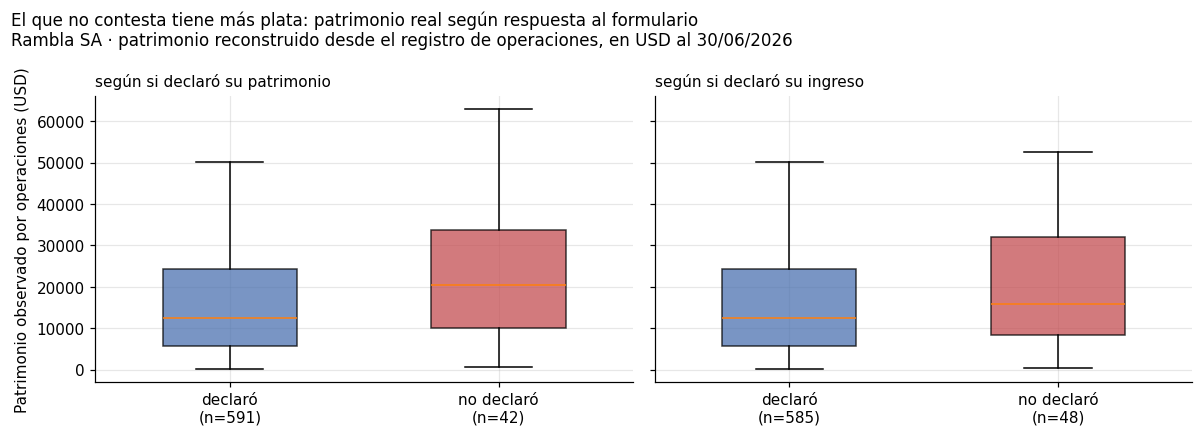

In [25]:
"""Gráfico: la distribución del patrimonio observado según si contestó o no."""

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (columna, etiqueta) in zip(axes, [("falta_patrimonio", "patrimonio"),
                                          ("falta_ingreso", "ingreso")]):
    datos = [comparacion.loc[~comparacion[columna], "observado_usd"].dropna(),
             comparacion.loc[comparacion[columna], "observado_usd"].dropna()]
    partes = ax.boxplot(datos, tick_labels=[f"declaró\n(n={len(datos[0])})",
                                       f"no declaró\n(n={len(datos[1])})"],
                        patch_artist=True, showfliers=False, widths=0.5)
    for parche, color in zip(partes["boxes"], ["#4C72B0", "#C44E52"]):
        parche.set_facecolor(color)
        parche.set_alpha(0.75)
    ax.set_title(f"según si declaró su {etiqueta}", loc="left", fontsize=10)
    ax.set_xlabel("")

axes[0].set_ylabel("Patrimonio observado por operaciones (USD)")
fig.suptitle("El que no contesta tiene más plata: patrimonio real según respuesta al formulario\n"
             "Rambla SA · patrimonio reconstruido desde el registro de operaciones, en USD al 30/06/2026",
             fontsize=11, ha="left", x=0.01)
plt.tight_layout()
plt.savefig(SALIDAS / "1_7_faltante_no_aleatorio.png", dpi=150, bbox_inches="tight")
plt.show()

### Conclusión de 1.7: el faltante no es aleatorio y no se puede borrar

Los clientes que **no declaran** su patrimonio tienen una cartera real sensiblemente
**más grande** que los que sí lo declaran, y el ingreso muestra el mismo patrón. El que no
contesta no es un cliente descuidado: es el cliente **más rico**, que no quiere poner su
patrimonio por escrito en un formulario en línea.

Técnicamente esto significa que los faltantes son **MNAR** (*Missing Not At Random*): la
probabilidad de que el dato falte depende del valor del propio dato. Las consecuencias son
concretas:

| Si se hiciera… | Qué pasaría |
|---|---|
| **Borrar las filas incompletas** | Se elimina justo el segmento de mayor patrimonio. La base queda sesgada hacia abajo y los promedios de patrimonio se subestiman. |
| **Imputar la media o la mediana** | Se le asigna a los clientes más ricos el patrimonio del cliente típico: achata la distribución y borra la cola alta, que es donde está el negocio de la firma. |
| **Reconstruir con las operaciones** | Se usa una fuente independiente que el cliente no puede falsear, disponible para el 99 % de los clientes. |

**Decisión: no se borra ni se imputa con estadísticos de la propia columna.** El patrimonio
faltante se reconstruye con el patrimonio observado en el registro de operaciones, y se
conserva una marca `patrimonio_fue_imputado` para poder repetir cualquier análisis sin esos
clientes y verificar que la conclusión no dependa de la imputación.

Esto además deja a la vista algo que se usa en la Etapa 3: **«no contesta» es una respuesta
informativa**, no un hueco. Por eso en 1.6 se convirtió en categoría propia en lugar de
tirarla.

## 1.8 · Clientes que no se pueden cruzar

Antes de armar la base limpia hay que resolver dos desajustes entre las dos tablas.

In [26]:
"""Clientes que están en una tabla y no en la otra."""

ids_encuesta = set(encuesta["id_cliente"])
ids_movimientos = set(movimientos["id_cliente"])

sin_encuesta = sorted(ids_movimientos - ids_encuesta)
sin_operaciones = sorted(ids_encuesta - ids_movimientos)

print(f"Clientes con operaciones pero sin encuesta: {len(sin_encuesta)}")
print(f"Clientes con encuesta pero sin operaciones: {len(sin_operaciones)}")

ops_huerfanas = movimientos[movimientos["id_cliente"].isin(sin_encuesta)]
monto_huerfano = (a_numero_uruguayo(ops_huerfanas["monto"]).abs()
                  * ops_huerfanas["moneda"].map(FACTOR_A_USD)).sum()

print(f"\nEsos {len(sin_encuesta)} clientes representan {len(ops_huerfanas)} operaciones "
      f"({len(ops_huerfanas) / len(movimientos):.1%} del registro) y "
      f"USD {monto_huerfano:,.0f} ({monto_huerfano / monto_usd.sum():.1%} del monto).")

# Pista decisiva: los identificadores pertenecen a otro bloque de numeración.
print(f"\nRango de id_cliente en la encuesta  : {min(ids_encuesta)} a {max(ids_encuesta)}")
print(f"Rango de id_cliente sin encuesta    : {sin_encuesta[0]} a {sin_encuesta[-1]}")
print(f"Operaciones por cliente — con encuesta: "
      f"{len(movimientos) / len(ids_encuesta & ids_movimientos):.1f} | "
      f"sin encuesta: {len(ops_huerfanas) / len(sin_encuesta):.1f}")

Clientes con operaciones pero sin encuesta: 73
Clientes con encuesta pero sin operaciones: 7

Esos 73 clientes representan 74 operaciones (1.7% del registro) y USD 220,072 (1.7% del monto).

Rango de id_cliente en la encuesta  : 20001 a 20640
Rango de id_cliente sin encuesta    : 80015 a 80890
Operaciones por cliente — con encuesta: 6.9 | sin encuesta: 1.0


In [27]:
"""Los clientes de la encuesta que nunca operaron."""

display(encuesta[encuesta["id_cliente"].isin(sin_operaciones)]
        [["id_cliente", "edad", "ocupacion", "patrimonio_invertible_usd",
          "perfil_autodeclarado", "anios_experiencia_invirtiendo"]])

registrar_decision(
    paso="1.8", columna="id_cliente (movimientos)",
    afectadas=len(ops_huerfanas), universo=len(movimientos),
    decision=f"excluir del cruce los {len(sin_encuesta)} clientes sin encuesta",
    motivo="Sus identificadores están en otro bloque de numeración (80.015-80.890 contra "
           "20.001-20.640) y promedian ~1 operación cada uno contra ~7 de los clientes de "
           "la firma: son de otro sistema o registros mal imputados. Sin encuesta no hay "
           "perfil declarado, que es la mitad de la comparación que pide el gerente. "
           "Pesan 1,7 % del monto, así que excluirlos no mueve los agregados; se reportan "
           "aparte como incidencia de conciliación.",
)
registrar_decision(
    paso="1.8", columna="id_cliente (encuesta)",
    afectadas=len(sin_operaciones), universo=len(encuesta),
    decision="conservar, marcados como 'sin cartera'",
    motivo="Declararon perfil pero nunca operaron: no tienen cartera efectiva, así que "
           "quedan fuera del cálculo de riesgo real, pero son clientes genuinos de la firma "
           "(patrimonio declarado entre USD 1.500 y 5.200) y son material comercial: "
           "firmaron y no invirtieron.",
)

,id_cliente,edad,ocupacion,patrimonio_invertible_usd,perfil_autodeclarado,anios_experiencia_invirtiendo
58,20306,54.0,Empleado en relación de dependencia,5100.0,Moderado,6.0
113,20281,32.0,Empleado en relación de dependencia,1500.0,Moderado,5.0
358,20367,38.0,Estudiante,1800.0,Agresivo,8.0
379,20544,56.0,Profesional independiente,3100.0,Agresivo,11.0
448,20228,46.0,Empleado público,4100.0,Conservador,5.0
546,20183,48.0,Estudiante,3400.0,Agresivo,4.0
551,20096,43.0,Profesional independiente,5200.0,Agresivo,2.0


  [1.8] id_cliente (movimientos): 74 de 4387 filas (1.69 %) -> excluir del cruce los 73 clientes sin encuesta
  [1.8] id_cliente (encuesta): 7 de 640 filas (1.09 %) -> conservar, marcados como 'sin cartera'


## 1.9 · Base limpia

Se aplica todo lo decidido en un solo lugar, para que el estado de la base sea rastreable.

In [28]:
"""Normalización de las categóricas: una sola forma de escribir cada respuesta."""

# Mapas explícitos en lugar de .title() automático: hay que decidir a mano casos como
# "Anual" vs "Anual o menos" o "Asesor" vs "Asesor financiero", que no son errores de
# mayúsculas sino etiquetas distintas para la misma categoría.
MAPAS_CATEGORIAS = {
    "tiene_deudas": {"sí": "Sí", "si": "Sí", "no": "No"},
    "tiene_fondo_emergencia": {"sí": "Sí", "si": "Sí", "no": "No"},
    "perfil_autodeclarado": {"conservador": "Conservador", "moderado": "Moderado",
                             "agresivo": "Agresivo"},
    "horizonte_inversion": {
        "menos de 1 año": "Menos de 1 año", "menos de 1 anio": "Menos de 1 año",
        "1 a 3 años": "1 a 3 años", "1-3 años": "1 a 3 años", "1-3 anios": "1 a 3 años",
        "3 a 5 años": "3 a 5 años", "3-5 años": "3 a 5 años", "3-5 anios": "3 a 5 años",
        "más de 5 años": "Más de 5 años", "mas de 5 años": "Más de 5 años",
        "mas de 5 anios": "Más de 5 años",
    },
    "frecuencia_monitoreo": {
        "diaria": "Diaria", "semanal": "Semanal", "mensual": "Mensual",
        "trimestral": "Trimestral",
        # "Anual" y "Anual o menos" son la misma categoría del formulario original.
        "anual": "Anual o menos", "anual o menos": "Anual o menos",
    },
    "fuente_informacion": {
        "redes sociales": "Redes sociales", "amigos y familia": "Amigos y familia",
        "investigación propia": "Investigación propia",
        "prensa especializada": "Prensa especializada",
        # "Asesor" y "Banco" son abreviaturas de las dos categorías largas.
        "asesor financiero": "Asesor financiero", "asesor": "Asesor financiero",
        "banco o corredor de bolsa": "Banco o corredor de bolsa",
        "banco": "Banco o corredor de bolsa",
    },
}

# Los departamentos se normalizan quitando tildes y mayúsculas, porque las variantes son
# sólo ortográficas ("San Jose"/"San José", "MONTEVIDEO"/"Montevideo").
TILDES = str.maketrans("áéíóúÁÉÍÓÚ", "aeiouAEIOU")
DEPARTAMENTOS = ["Artigas", "Canelones", "Cerro Largo", "Colonia", "Durazno", "Flores",
                 "Florida", "Lavalleja", "Maldonado", "Montevideo", "Paysandú",
                 "Río Negro", "Rivera", "Rocha", "Salto", "San José", "Soriano",
                 "Tacuarembó", "Treinta y Tres"]
MAPA_DEPARTAMENTOS = {d.translate(TILDES).lower(): d for d in DEPARTAMENTOS}

categorias_antes = {c: encuesta[c].nunique() for c in COLUMNAS_CATEGORICAS}

for columna, mapa in MAPAS_CATEGORIAS.items():
    encuesta[columna] = limpiar_texto(encuesta[columna]).str.lower().map(mapa).astype("string")

encuesta["departamento"] = (limpiar_texto(encuesta["departamento"])
                            .str.translate(TILDES).str.lower()
                            .map(MAPA_DEPARTAMENTOS).astype("string"))

for columna in ["sexo", "nivel_educativo", "ocupacion", "tolerancia_perdida_maxima",
                "retorno_esperado_anual", *PREGUNTAS_SALTEABLES]:
    encuesta[columna] = limpiar_texto(encuesta[columna])

# Recién ahora el vacío de las preguntas opcionales pasa a ser categoría (decisión de 1.6).
for columna in PREGUNTAS_SALTEABLES:
    encuesta[columna] = encuesta[columna].fillna("No contesta")

comparar = pd.DataFrame({
    "categorias_antes": pd.Series(categorias_antes),
    "categorias_despues": pd.Series({c: encuesta[c].nunique() for c in COLUMNAS_CATEGORICAS}),
    "esperadas": pd.Series(CATEGORIAS_ESPERADAS),
})
display(comparar)

sobrantes = comparar[comparar["categorias_despues"] > comparar["esperadas"]]
print("Variables que todavía exceden lo esperado:",
      sobrantes.index.tolist() or "ninguna (reaccion_caida_20 y objetivo_principal "
      "suman 1 por la categoría 'No contesta')")

registrar_decision(
    paso="1.9", columna="(14 categóricas)",
    afectadas=int(sum(max(0, categorias_antes[c] - CATEGORIAS_ESPERADAS[c])
                      for c in COLUMNAS_CATEGORICAS)),
    universo=len(encuesta),
    decision="unificar las variantes de escritura con mapas explícitos",
    motivo="'CONSERVADOR', 'moderado' y 'Agresivo ' con espacio son la misma respuesta mal "
           "escrita: si no se unifican, el cruce declarado-contra-real parte la misma "
           "categoría en varias y el porcentaje de desajuste sale mal. Se usan mapas "
           "explícitos y no .title() porque 'Asesor'/'Asesor financiero' y 'Anual'/'Anual o "
           "menos' son decisiones de criterio, no de formato.",
)

,categorias_antes,categorias_despues,esperadas
sexo,2,2,2
departamento,25,19,19
nivel_educativo,4,4,4
ocupacion,6,6,6
tiene_deudas,2,2,2
tiene_fondo_emergencia,4,2,2
perfil_autodeclarado,6,3,3
tolerancia_perdida_maxima,5,5,5
horizonte_inversion,7,4,4
frecuencia_monitoreo,8,5,5


Variables que todavía exceden lo esperado: ['reaccion_caida_20', 'objetivo_principal']
  [1.9] (14 categóricas): 20 de 640 filas (3.12 %) -> unificar las variantes de escritura con mapas explícitos


In [29]:
"""Numéricas: parseo, centinelas a faltante y rangos imposibles a faltante."""

for columna in COLUMNAS_CONTINUAS:
    if columna not in encuesta.columns:
        continue
    if encuesta[columna].dtype == "string":
        encuesta[columna] = a_numero_uruguayo(encuesta[columna])

# Centinelas numéricos -> faltante
MOTIVO_CENTINELA = ("No es un valor posible de la variable, es el código que el formulario "
                    "grabó cuando el cliente no contestó. Dejarlo arrastra el promedio hacia "
                    "abajo y lo mete en cualquier correlación.")

for columna, codigo, motivo in [
    ("ingreso_mensual_liquido", CENTINELA_NO_CONTESTA, MOTIVO_CENTINELA),
    ("patrimonio_invertible_usd", CENTINELA_NO_CONTESTA, MOTIVO_CENTINELA),
    ("puntaje_test_conocimiento", CENTINELA_TEST_NO_RENDIDO, MOTIVO_CENTINELA),
    ("ingreso_mensual_liquido", CENTINELA_INGRESO_VACIO,
     "Los 14 clientes con ingreso 0 tienen todos ocupación activa y un patrimonio "
     "invertible mediano de USD 25.700: ninguno es estudiante ni jubilado. Un ingreso "
     "líquido de cero es imposible para ellos. A diferencia de los demás centinelas, el 0 "
     "sobrevive cualquier control de rango, porque cero es un ingreso válido: se detecta "
     "sólo cruzando la variable contra la ocupación."),
]:
    afectadas = int((encuesta[columna] == codigo).sum())
    if not afectadas:
        continue
    encuesta[columna] = encuesta[columna].mask(encuesta[columna] == codigo)
    registrar_decision(
        paso="1.9", columna=columna, afectadas=afectadas, universo=len(encuesta),
        decision=f"el centinela {codigo} pasa a faltante", motivo=motivo,
    )

# Rangos imposibles -> faltante
for columna, (minimo, maximo) in RANGOS_VALIDOS.items():
    valores = encuesta[columna]
    fuera = pd.Series(False, index=valores.index)
    if minimo is not None:
        fuera |= valores < minimo
    if maximo is not None:
        fuera |= valores > maximo
    if not fuera.any():
        continue
    encuesta[columna] = valores.mask(fuera)
    registrar_decision(
        paso="1.9", columna=columna, afectadas=int(fuera.sum()), universo=len(encuesta),
        decision=f"fuera de [{minimo}, {maximo}] pasa a faltante",
        motivo="Valor imposible, no atípico. No se corrige a mano porque no hay forma de "
               "saber el valor real (un 16 puede ser 61, 46 o cualquier cosa) e inventarlo "
               "agregaría error en una variable que después se cruza contra el riesgo.",
    )

display(encuesta[COLUMNAS_CONTINUAS].describe().T)

  [1.9] ingreso_mensual_liquido: 9 de 640 filas (1.41 %) -> el centinela -999 pasa a faltante
  [1.9] patrimonio_invertible_usd: 13 de 640 filas (2.03 %) -> el centinela -999 pasa a faltante
  [1.9] puntaje_test_conocimiento: 18 de 640 filas (2.81 %) -> el centinela -1 pasa a faltante
  [1.9] ingreso_mensual_liquido: 14 de 640 filas (2.19 %) -> el centinela 0 pasa a faltante
  [1.9] edad: 16 de 640 filas (2.50 %) -> fuera de [18, 95] pasa a faltante


,count,mean,std,min,25%,50%,75%,max
edad,618.00,47.13,11.48,26.00,38.00,46.00,54.00,82.00
ingreso_mensual_liquido,578.00,"89,406.75","59,342.45","22,000.00","49,400.00","75,900.00","112,550.00","535,900.00"
patrimonio_invertible_usd,598.00,"25,758.70","30,052.08",0.00,"8,125.00","16,700.00","32,175.00","279,100.00"
meses_gastos_cubiertos,626.00,2.81,3.86,0.00,0.00,0.00,5.00,12.00
anios_experiencia_invirtiendo,640.00,5.39,4.73,0.00,2.00,4.00,7.00,34.00
puntaje_test_conocimiento,622.00,4.46,1.87,0.00,3.00,5.00,6.00,10.00
cantidad_dependientes,640.00,0.9109,0.9576,0.00,0.00,1.00,1.00,5.00
conocimiento_autopercibido,640.00,2.57,0.9921,1.00,2.00,3.00,3.00,5.00


In [30]:
"""Montos de los movimientos: signo y faltantes."""

movimientos["monto"] = a_numero_uruguayo(movimientos["monto"])

negativos = int((movimientos["monto"] < 0).sum())
movimientos["monto"] = movimientos["monto"].abs()
registrar_decision(
    paso="1.9", columna="monto", afectadas=negativos, universo=len(movimientos),
    decision="tomar el valor absoluto",
    motivo="tipo_operacion sólo tiene Compra y Suscripción, que son las dos entradas de "
           "dinero: no hay Venta ni Rescate en el archivo. Un monto negativo no puede ser "
           "un retiro, es un error de signo en la carga. El valor absoluto de esos montos "
           "cae en el rango normal de su moneda, lo que confirma la lectura.",
)

sin_monto = int(movimientos["monto"].isna().sum())
movimientos = movimientos[movimientos["monto"].notna()].reset_index(drop=True)
registrar_decision(
    paso="1.9", columna="monto", afectadas=sin_monto, universo=sin_monto + len(movimientos),
    decision="eliminar la operación",
    motivo="Una operación sin monto no aporta nada a la cartera efectiva: no se puede "
           "ponderar un instrumento por un monto que no existe. Imputar la mediana le "
           "inventaría al cliente una posición que no se sabe si tiene. Afecta al 1,2 % de "
           "las operaciones y se verifica abajo que no se concentra en ningún cliente.",
)

# Control: ¿la eliminación afecta a algún cliente en particular?
perdidas_por_cliente = movimientos_crudos.loc[
    a_numero_uruguayo(movimientos_crudos["monto"]).isna(), "id_cliente"].value_counts()
print(f"\nClientes afectados por operaciones sin monto: {len(perdidas_por_cliente)}")
print(f"Máximo de operaciones perdidas por un mismo cliente: {perdidas_por_cliente.max()}")
print(f"Clientes que quedan sin ninguna operación por esto: "
      f"{len(set(perdidas_por_cliente.index) - set(movimientos['id_cliente']))}")

  [1.9] monto: 18 de 4387 filas (0.41 %) -> tomar el valor absoluto
  [1.9] monto: 52 de 4387 filas (1.19 %) -> eliminar la operación

Clientes afectados por operaciones sin monto: 49
Máximo de operaciones perdidas por un mismo cliente: 2
Clientes que quedan sin ninguna operación por esto: 1


In [31]:
"""Imputación del patrimonio faltante con la fuente independiente (decisión de 1.7)."""

encuesta["patrimonio_observado_usd"] = encuesta["id_cliente"].map(
    (movimientos["monto"] * movimientos["moneda"].map(FACTOR_A_USD))
    .groupby(movimientos["id_cliente"]).sum()
)

falta = encuesta["patrimonio_invertible_usd"].isna()
puede_imputarse = falta & encuesta["patrimonio_observado_usd"].notna()

encuesta["patrimonio_fue_imputado"] = puede_imputarse
encuesta["patrimonio_invertible_usd"] = encuesta["patrimonio_invertible_usd"].fillna(
    encuesta["patrimonio_observado_usd"]
)

registrar_decision(
    paso="1.9", columna="patrimonio_invertible_usd",
    afectadas=int(puede_imputarse.sum()), universo=len(encuesta),
    decision="imputar con el patrimonio observado en el registro de operaciones",
    motivo="El faltante es MNAR: el que no contesta tiene cartera real más grande (1.7). "
           "Borrar sesga la base hacia abajo justo en el segmento de mayor patrimonio e "
           "imputar la mediana achata la cola alta. El registro de operaciones es una "
           "fuente independiente que el cliente no puede falsear. Queda la marca "
           "patrimonio_fue_imputado para rehacer cualquier análisis sin estos clientes.",
)

print(f"\nPatrimonio todavía faltante: {int(encuesta['patrimonio_invertible_usd'].isna().sum())} "
      "(clientes sin operaciones registradas)")

# El ingreso no tiene fuente independiente: el registro de operaciones informa patrimonio,
# no sueldo. Se deja faltante en lugar de inventarlo.
faltan_ingreso = int(encuesta["ingreso_mensual_liquido"].isna().sum())
encuesta["ingreso_fue_declarado"] = encuesta["ingreso_mensual_liquido"].notna()
registrar_decision(
    paso="1.9", columna="ingreso_mensual_liquido",
    afectadas=faltan_ingreso, universo=len(encuesta),
    decision="dejar faltante, sin imputar",
    motivo="A diferencia del patrimonio, el ingreso no tiene fuente independiente: las "
           "operaciones informan cuánto invirtió el cliente, no cuánto gana. Como el "
           "faltante es MNAR (1.7), imputar la mediana le asignaría a los clientes de "
           "mayor patrimonio el sueldo del cliente típico y aplastaría justamente la "
           "relación ingreso-riesgo que la Etapa 3 tiene que medir. Todo análisis que use "
           "el ingreso reporta su propio n y se interpreta sobre los que sí declararon.",
)

  [1.9] patrimonio_invertible_usd: 42 de 640 filas (6.56 %) -> imputar con el patrimonio observado en el registro de operaciones

Patrimonio todavía faltante: 0 (clientes sin operaciones registradas)
  [1.9] ingreso_mensual_liquido: 62 de 640 filas (9.69 %) -> dejar faltante, sin imputar


In [32]:
"""Bitácora completa de la etapa: el impacto de cada decisión sobre la base."""

bitacora = pd.DataFrame(BITACORA)
display(bitacora[["paso", "columna", "filas_afectadas", "universo", "pct_base", "decision"]])

print(f"\nDecisiones registradas: {len(bitacora)}")
print(f"Máximo porcentaje de la base afectado por una sola decisión: "
      f"{bitacora['pct_base'].max():.2f} %")

bitacora.to_csv(SALIDAS / "1_bitacora_decisiones.csv", index=False, encoding="utf-8-sig")
print(f"Bitácora guardada en {SALIDAS / '1_bitacora_decisiones.csv'}")

,paso,columna,filas_afectadas,universo,pct_base,decision
0,1.3,(fila completa),17,657,2.59,eliminar duplicados exactos: 657 -> 640 filas
1,1.3,(clave de negocio),94,4481,2.10,eliminar el registro repetido: 4481 -> 4387 op...
2,1.6,meses_gastos_cubiertos,17,640,2.66,imputar 0
3,1.6,meses_gastos_cubiertos,14,640,2.19,dejar como faltante
4,1.6,reaccion_caida_20,19,640,2.97,convertir el vacío en la categoría 'No contesta'
5,1.6,objetivo_principal,26,640,4.06,convertir el vacío en la categoría 'No contesta'
6,1.8,id_cliente (movimientos),74,4387,1.69,excluir del cruce los 73 clientes sin encuesta
7,1.8,id_cliente (encuesta),7,640,1.09,"conservar, marcados como 'sin cartera'"
8,1.9,(14 categóricas),20,640,3.12,unificar las variantes de escritura con mapas ...
9,1.9,ingreso_mensual_liquido,9,640,1.41,el centinela -999 pasa a faltante



Decisiones registradas: 18
Máximo porcentaje de la base afectado por una sola decisión: 9.69 %
Bitácora guardada en C:\Users\prisc\Downloads\prog analitica II\proyecto-final-gerlach\salidas\1_bitacora_decisiones.csv


In [33]:
"""Estado final de la Etapa 1: antes y después."""

resumen_etapa = pd.DataFrame([
    {"tabla": "encuesta", "concepto": "filas", "antes": len(encuesta_cruda), "despues": len(encuesta)},
    {"tabla": "encuesta", "concepto": "clientes únicos",
     "antes": encuesta_cruda["id_cliente"].nunique(), "despues": encuesta["id_cliente"].nunique()},
    {"tabla": "encuesta", "concepto": "faltantes totales en celdas",
     "antes": int(encuesta_cruda.isna().sum().sum()), "despues": int(encuesta.isna().sum().sum())},
    {"tabla": "movimientos", "concepto": "operaciones",
     "antes": len(movimientos_crudos), "despues": len(movimientos)},
    {"tabla": "movimientos", "concepto": "clientes con operaciones",
     "antes": movimientos_crudos["id_cliente"].nunique(), "despues": movimientos["id_cliente"].nunique()},
])
resumen_etapa["variacion"] = resumen_etapa["despues"] - resumen_etapa["antes"]
resumen_etapa["pct"] = (resumen_etapa["variacion"] / resumen_etapa["antes"] * 100).round(2)
display(resumen_etapa.set_index(["tabla", "concepto"]))

# Controles que tienen que valer antes de seguir a la Etapa 2.
assert encuesta["id_cliente"].is_unique, "Una fila por cliente"
assert encuesta["fecha_respuesta"].le(FECHA_CORTE).all(), "Sin encuestas posteriores al corte"
assert movimientos["monto"].gt(0).all(), "Todos los montos positivos y presentes"
assert movimientos["fecha_operacion"].le(FECHA_CORTE).all(), "Sin operaciones posteriores al corte"
assert encuesta["perfil_autodeclarado"].nunique() == 3, "Tres perfiles autodeclarados"
print("\nTodos los controles de la Etapa 1 pasaron.")

encuesta.to_parquet(SALIDAS / "encuesta_limpia.parquet", index=False)
movimientos.to_parquet(SALIDAS / "movimientos_limpios.parquet", index=False)
print(f"Bases limpias guardadas en {SALIDAS}")

antes  despues  variacion     pct
tabla       concepto                                                      
encuesta    filas                          657      640        -17   -2.59
            clientes únicos                640      640          0    0.00
            faltantes totales en celdas    129      123         -6   -4.65
movimientos operaciones                   4481     4335       -146   -3.26
            clientes con operaciones       706      705         -1 -0.1400


Todos los controles de la Etapa 1 pasaron.


Bases limpias guardadas en C:\Users\prisc\Downloads\prog analitica II\proyecto-final-gerlach\salidas


---
## Cierre de la Etapa 1

**De qué tamaño era el problema:**

| Problema | Magnitud | Qué se hizo |
|---|---|---|
| Formularios enviados dos veces | 17 clientes (2,6 % de las filas) | Eliminar el duplicado exacto |
| Misma operación registrada dos veces | 94 operaciones (2,1 %) | Eliminar por clave de negocio |
| Categorías escritas de varias maneras | 6 variables, hasta 25 categorías donde hay 19 | Unificar con mapas explícitos |
| Centinelas que `isna()` no ve | **5** formas distintas de «no contestó» (`-999`, `-1`, `0`, `"S/D"`, `"Prefiero no contestar"`) | Convertir a faltante y contarlos |
| Edades imposibles | 16 clientes (0 años, 16 años con 22 de experiencia, 154 años) | Pasar a faltante |
| Dos formatos de fecha mezclados | 806 fechas con barras | Parsear por patrón, no con `format="mixed"` |
| Montos con signo invertido | 18 operaciones | Valor absoluto |
| Operaciones sin monto | 52 (1,2 %) | Eliminar, verificando que no se concentren |
| Clientes sin encuesta | 73, otro bloque de IDs, 1,7 % del monto | Excluir del cruce y reportar |

**El hallazgo de la etapa:** los faltantes de patrimonio e ingreso son MNAR. El que no
contesta es el cliente de mayor patrimonio real. Eso convierte la decisión sobre las filas
incompletas en una decisión de negocio, no de prolijidad: borrarlas habría eliminado del
análisis justo al segmento que la firma menos puede permitirse malinterpretar.

**Lo que habilita la Etapa 2:** una base de una fila por cliente, con montos positivos en
tres monedas listos para normalizar, y el registro de operaciones conciliado contra la
encuesta.

---
# Etapa 2 · Creación de variables

El encargo del gerente es comparar **lo que los clientes dicen** contra **lo que hacen**.
Lo que dicen está en la encuesta, ya limpia. Lo que hacen hay que construirlo desde el
registro de operaciones, y eso son cuatro pasos:

1. Normalizar las tres monedas a una sola.
2. Reconstruir la cartera efectiva de cada cliente.
3. Medir el riesgo efectivo de esa cartera.
4. Traducir esa medida continua a las tres categorías de la firma.

Cada paso tiene una decisión de criterio y acá se justifican todas.

## 2.1 · Normalización de las tres monedas

**Por qué no se puede saltear.** El registro tiene 1.950 operaciones en pesos, 1.687 en
dólares y 844 en unidades indexadas, y la columna `monto` está en la moneda de cada fila.
Sumarlas sin convertir no da un número grande: da un número **invertido**. Un plazo fijo de
$ 400.000 son unos USD 9.300, menos que un ETF de USD 10.000, pero sin convertir parece
cuarenta veces más grande. Como el riesgo de la cartera se pondera por monto, todo el
análisis quedaría dominado por los instrumentos en pesos, que son justamente los más
conservadores.

**A qué moneda.** Se normaliza a **dólares**, por tres razones:

1. El patrimonio declarado por el cliente ya viene en dólares (`patrimonio_invertible_usd`),
   así que convertir a dólares permite contrastar lo declarado contra lo observado sin una
   conversión intermedia.
2. Es la moneda de referencia del asesoramiento patrimonial en Uruguay y la que entiende la
   mesa a la que se presenta.
3. Seis de los catorce instrumentos del catálogo ya están denominados en dólares.

**Con qué cotizaciones.** Las de `tasas_referencia.csv` al 30/06/2026, que es la fecha de
corte de toda la base. No se usan cotizaciones de la fecha de cada operación: el objetivo es
medir cuánto vale hoy la cartera de cada cliente para compararla entre clientes, no
reconstruir el valor histórico de cada compra. Usar el tipo de cambio del día de cada
operación mezclaría el efecto de la decisión de inversión con el efecto de cuándo se hizo.

In [34]:
"""Constantes de conversión, leídas del archivo de tasas (no se escriben a mano)."""


def leer_tasa(patron: str) -> float:
    """Devuelve el valor del único indicador cuyo concepto coincide con el patrón."""
    fila = tasas[tasas["concepto"].str.contains(patron, case=False, regex=True)]
    if len(fila) != 1:
        raise ValueError(f"El patrón '{patron}' coincide con {len(fila)} indicadores, debe ser 1")
    return float(fila["valor"].iloc[0])


TIPO_CAMBIO = leer_tasa("Tipo de cambio")            # UYU por USD
VALOR_UI = leer_tasa("Unidad Indexada")              # UYU por UI
INFLACION_UY = leer_tasa(r"Inflación anual Uruguay") / 100
INFLACION_US = leer_tasa(r"Inflación anual de Estados Unidos") / 100
TASA_POLITICA_UY = leer_tasa("política monetaria") / 100
TASA_TESORO_US = leer_tasa("Tesoro de EE") / 100

# Una UI vale VALOR_UI pesos, y un dólar vale TIPO_CAMBIO pesos.
FACTOR_A_USD = {
    "USD": 1.0,
    "UYU": 1 / TIPO_CAMBIO,
    "UI": VALOR_UI / TIPO_CAMBIO,
}

print(f"Tipo de cambio        : {TIPO_CAMBIO:>8.2f} UYU/USD")
print(f"Unidad Indexada       : {VALOR_UI:>8.2f} UYU/UI  (= USD {FACTOR_A_USD['UI']:.4f})")
print(f"Inflación Uruguay     : {INFLACION_UY:>8.1%}")
print(f"Inflación EE.UU.      : {INFLACION_US:>8.1%}")
print(f"Tasa política BCU     : {TASA_POLITICA_UY:>8.2%}")
print(f"Bono Tesoro EE.UU. 10a: {TASA_TESORO_US:>8.2%}")

Tipo de cambio        :    42.80 UYU/USD
Unidad Indexada       :     6.55 UYU/UI  (= USD 0.1530)
Inflación Uruguay     :     5.4%
Inflación EE.UU.      :     2.7%
Tasa política BCU     :    8.75%
Bono Tesoro EE.UU. 10a:    4.10%


In [35]:
"""Conversión de los montos y verificación de que la normalización invierte el orden."""

# Sólo se trabaja con los clientes que tienen encuesta (decisión 1.8).
movimientos_utiles = movimientos[movimientos["id_cliente"].isin(set(encuesta["id_cliente"]))].copy()
movimientos_utiles["monto_usd"] = (movimientos_utiles["monto"]
                                   * movimientos_utiles["moneda"].map(FACTOR_A_USD))

comparacion_monedas = movimientos_utiles.groupby("moneda").agg(
    operaciones=("monto", "size"),
    monto_sin_convertir=("monto", "sum"),
    monto_en_usd=("monto_usd", "sum"))
comparacion_monedas["peso_sin_convertir"] = (
    comparacion_monedas["monto_sin_convertir"] / comparacion_monedas["monto_sin_convertir"].sum())
comparacion_monedas["peso_real_usd"] = (
    comparacion_monedas["monto_en_usd"] / comparacion_monedas["monto_en_usd"].sum())
display(comparacion_monedas.style.format({
    "monto_sin_convertir": "{:,.0f}", "monto_en_usd": "{:,.0f}",
    "peso_sin_convertir": "{:.1%}", "peso_real_usd": "{:.1%}"}))

print(f"Total de la cartera de la firma: USD {movimientos_utiles['monto_usd'].sum():,.0f}")

,operaciones,monto_sin_convertir,monto_en_usd,peso_sin_convertir,peso_real_usd
moneda,,,,,
UI,796,"14,866,403","2,275,115",6.5%,17.7%
USD,1605,"5,722,325","5,722,325",2.5%,44.5%
UYU,1861,"207,542,429","4,849,122",91.0%,37.7%


Total de la cartera de la firma: USD 12,846,563


**La tabla muestra por qué esto no es un trámite.** Sin convertir, los pesos parecen
representar el grueso del dinero de la firma; en dólares reales su peso cae a menos de la
mitad de eso. Cualquier medida ponderada por monto calculada antes de convertir habría
sobrerrepresentado masivamente a los instrumentos en pesos, que son los de menor nivel de
riesgo del catálogo. El análisis habría salido al revés, exactamente como advierte la
consigna.

## 2.2 · Qué cuenta como cartera: el problema de los dólares en la caja de seguridad

Antes de reconstruir la cartera hay que resolver una pregunta que cambia el resultado: los
**dólares en caja de seguridad** (instrumento 14, `nivel_riesgo` 1 y retorno 0%), ¿son parte
de la cartera de inversión o no?

Importa porque son **USD 1.056.554**, el 8,2 % de todo lo registrado, en manos de 171
clientes (27 % de los que operan), y como tienen el nivel de riesgo más bajo del catálogo
arrastran hacia abajo el riesgo de quien los tiene.

**Lo que hace la industria.** El efectivo es una clase de activo como la renta fija o la
renta variable, y una asignación a efectivo es una decisión deliberada del asesor, no una
ausencia de decisión. Pero la práctica estándar de planificación financiera separa dos
efectivos que no se tratan igual:

| Tipo | Qué es | Tratamiento |
|---|---|---|
| **Reserva de emergencia** | 3 a 6 meses de gastos, accesibles de inmediato | **Fuera** de la cartera de inversión: no entra en la asignación de activos ni en el perfil de riesgo |
| **Efectivo estratégico** | Lo que excede esa reserva | **Dentro** de la cartera: es una decisión de asignación |

El fundamento es que la reserva cumple una función distinta —cubrir un imprevisto sin
liquidar inversiones— y mezclarla con la cartera confunde una necesidad de seguridad de
corto plazo con la estrategia de largo plazo. Al excedente la industria le tiene nombre
propio: *cash drag*, el costo de rendimiento del capital sin desplegar.

**Regla adoptada.** El efectivo de cada cliente se parte en dos:

- hasta **3 meses de su ingreso líquido declarado** → reserva de emergencia, queda fuera;
- el excedente → asignación, entra a la cartera con `nivel_riesgo` 1.

Se toma el extremo inferior del rango 3 a 6 meses porque es el más conservador *para la
conclusión*: cuanto menor la reserva, más efectivo entra a la cartera y más conservadores
parecen los clientes, así que si igual aparece desajuste, no es por haber inflado el riesgo.

**Para los 18 clientes que no declararon ingreso** no se puede calcular la reserva. Se usa
su propia respuesta como respaldo: si declararon tener fondo de emergencia, se asume que el
efectivo *es* ese fondo y queda todo fuera; si declararon no tenerlo, el efectivo no es un
fondo de emergencia y entra entero.

In [36]:
"""Descomposición del efectivo en reserva de emergencia y excedente asignado."""

ID_EFECTIVO = 14          # Dólares en caja de seguridad
MESES_DE_RESERVA = 3      # extremo inferior del estándar de 3 a 6 meses

efectivo_por_cliente = (movimientos_utiles[movimientos_utiles["id_instrumento"] == ID_EFECTIVO]
                        .groupby("id_cliente")["monto_usd"].sum())

datos_cliente = encuesta.set_index("id_cliente")
reserva_requerida = datos_cliente["ingreso_mensual_liquido"] * MESES_DE_RESERVA / TIPO_CAMBIO

efectivo = pd.DataFrame({"efectivo_usd": efectivo_por_cliente}).join(
    pd.DataFrame({"reserva_requerida": reserva_requerida,
                  "tiene_fondo": datos_cliente["tiene_fondo_emergencia"]}))

# Regla principal: la reserva es el menor entre lo que tiene y lo que necesita.
efectivo["reserva"] = np.minimum(efectivo["efectivo_usd"], efectivo["reserva_requerida"])

# Respaldo para quien no declaró ingreso: se usa su propia respuesta sobre el fondo.
sin_ingreso = efectivo["reserva_requerida"].isna()
efectivo.loc[sin_ingreso, "reserva"] = np.where(
    efectivo.loc[sin_ingreso, "tiene_fondo"] == "Sí",
    efectivo.loc[sin_ingreso, "efectivo_usd"],   # el efectivo ES el fondo declarado
    0.0,                                         # declaró no tener fondo: es asignación
)
efectivo["excedente"] = efectivo["efectivo_usd"] - efectivo["reserva"]

print(f"Clientes con dólares en caja de seguridad : {len(efectivo)}")
print(f"Efectivo total                           : USD {efectivo['efectivo_usd'].sum():,.0f}")
print(f"  reserva de emergencia (queda FUERA)    : USD {efectivo['reserva'].sum():>10,.0f} "
      f"({efectivo['reserva'].sum() / efectivo['efectivo_usd'].sum():.0%})")
print(f"  excedente (entra a la cartera)         : USD {efectivo['excedente'].sum():>10,.0f} "
      f"({efectivo['excedente'].sum() / efectivo['efectivo_usd'].sum():.0%})")
print(f"\nClientes cuyo efectivo es todo reserva   : {int((efectivo['excedente'] <= 0.01).sum())}")
print(f"Clientes sin ingreso declarado (respaldo): {int(sin_ingreso.sum())}")

registrar_decision(
    paso="2.2", columna="dólares en caja de seguridad",
    afectadas=len(efectivo), universo=len(encuesta),
    decision=f"partir el efectivo: {efectivo['reserva'].sum() / efectivo['efectivo_usd'].sum():.0%} "
             "reserva (fuera) y el resto asignación (dentro)",
    motivo="El efectivo es una clase de activo y una asignación a efectivo es una decisión "
           "del cliente, pero la práctica estándar deja la reserva de emergencia (3 a 6 "
           "meses de gastos) fuera de la cartera de inversión, porque cumple otra función. "
           "Incluir todo haría ver como conservador a quien simplemente no invierte; "
           "excluir todo borraría una decisión de asignación real.",
)

Clientes con dólares en caja de seguridad : 171


Efectivo total                           : USD 1,056,554
  reserva de emergencia (queda FUERA)    : USD    631,936 (60%)
  excedente (entra a la cartera)         : USD    424,618 (40%)

Clientes cuyo efectivo es todo reserva   : 131
Clientes sin ingreso declarado (respaldo): 18
  [2.2] dólares en caja de seguridad: 171 de 640 filas (26.72 %) -> partir el efectivo: 60% reserva (fuera) y el resto asignación (dentro)


In [37]:
"""Hallazgo lateral: quienes guardan efectivo y dicen no tener fondo de emergencia."""

contradicen = efectivo[efectivo["tiene_fondo"] == "No"]
print(f"Clientes que declaran NO tener fondo de emergencia pero guardan dólares en caja: "
      f"{len(contradicen)}")
print(f"  monto que acumulan : USD {contradicen['efectivo_usd'].sum():,.0f}")
print(f"  mediana por cliente: USD {contradicen['efectivo_usd'].median():,.0f}")
print("\nTienen un fondo de emergencia; no lo reconocen como tal. Se retoma en la Etapa 3 "
      "junto con el resto de las inconsistencias internas.")

display(efectivo.groupby("tiene_fondo").agg(
    clientes=("efectivo_usd", "size"),
    efectivo_total=("efectivo_usd", "sum"),
    mediana=("efectivo_usd", "median"),
    reserva=("reserva", "sum"),
    excedente=("excedente", "sum")).style.format({
        "efectivo_total": "{:,.0f}", "mediana": "{:,.0f}",
        "reserva": "{:,.0f}", "excedente": "{:,.0f}"}))

Clientes que declaran NO tener fondo de emergencia pero guardan dólares en caja: 73
  monto que acumulan : USD 468,630
  mediana por cliente: USD 2,769

Tienen un fondo de emergencia; no lo reconocen como tal. Se retoma en la Etapa 3 junto con el resto de las inconsistencias internas.


,clientes,efectivo_total,mediana,reserva,excedente
tiene_fondo,,,,,
No,73,"468,630","2,769","195,977","272,654"
Sí,98,"587,924","3,233","435,959","151,964"


## 2.3 · La cartera efectiva de cada cliente

**Qué se está midiendo.** El archivo de operaciones registra sólo compras y suscripciones:
no hay ventas ni rescates. Entonces la cartera que se reconstruye es el **monto acumulado
invertido en cada instrumento a costo de adquisición**, no su valor de mercado al 30/06/2026.

Es una limitación que hay que declarar, y tiene dos supuestos detrás:

1. **No hubo desinversión.** Si un cliente vendió algo, la firma no lo registró y acá
   aparece como si todavía lo tuviera.
2. **No se capitalizan rendimientos.** Un ETF comprado en 2022 vale hoy bastante más que lo
   que costó, pero se lo cuenta por lo que costó.

**Por qué igual sirve.** Para la pregunta del gerente —*¿la cartera se parece a lo que el
cliente dijo ser?*— lo que importa es **hacia dónde dirigió su dinero**, y eso el costo de
adquisición lo captura bien. Es más: usar valor de mercado introduciría un sesgo, porque
los instrumentos de mayor retorno son también los de mayor riesgo, y se verían inflados por
el solo paso del tiempo. El cliente que puso USD 1.000 en cripto en 2022 tomó la misma
decisión de riesgo que el que los puso en 2025, aunque hoy valgan cosas distintas.

**Se usa todo el histórico 2022-2026** y no una ventana reciente, porque la inversión
patrimonial es de largo plazo: una compra de 2023 sigue siendo parte de la cartera actual.

In [38]:
"""Reconstrucción de la cartera: cuánto tiene cada cliente y en qué instrumentos."""

# El efectivo entra sólo por su excedente. Se prorratea entre los movimientos de efectivo
# del cliente para no tener que inventar a cuál de ellos corresponde la reserva.
proporcion_que_entra = (efectivo["excedente"] / efectivo["efectivo_usd"]).clip(0, 1)

movimientos_utiles["monto_cartera"] = movimientos_utiles["monto_usd"]
es_efectivo = movimientos_utiles["id_instrumento"] == ID_EFECTIVO
movimientos_utiles.loc[es_efectivo, "monto_cartera"] = (
    movimientos_utiles.loc[es_efectivo, "monto_usd"]
    * movimientos_utiles.loc[es_efectivo, "id_cliente"].map(proporcion_que_entra).fillna(1.0))

posiciones = (movimientos_utiles[movimientos_utiles["monto_cartera"] > 0]
              .merge(catalogo, on="id_instrumento", how="left"))

cartera = posiciones.groupby("id_cliente").agg(
    cartera_usd=("monto_cartera", "sum"),
    operaciones=("monto_cartera", "size"),
    instrumentos=("id_instrumento", "nunique"),
    primera_operacion=("fecha_operacion", "min"),
    ultima_operacion=("fecha_operacion", "max"))
cartera["meses_desde_ultima"] = (
    (FECHA_CORTE - cartera["ultima_operacion"]).dt.days / 30.44).round(1)

print(f"Clientes con cartera de inversión reconstruida: {len(cartera)}")
display(cartera[["cartera_usd", "operaciones", "instrumentos", "meses_desde_ultima"]]
        .describe().T)

Clientes con cartera de inversión reconstruida: 628


,count,mean,std,min,25%,50%,75%,max
cartera_usd,628.00,"19,450.04","25,167.79",39.23,"5,266.13","11,663.60","23,429.70","254,370.84"
operaciones,628.00,6.27,3.47,1.00,4.00,6.00,8.00,22.00
instrumentos,628.00,2.53,1.18,1.00,2.00,2.00,3.00,7.00
meses_desde_ultima,628.00,8.76,8.06,1.00,3.10,6.00,12.00,45.60


In [39]:
"""Los clientes que quedan sin cartera de inversión."""

sin_cartera = sorted(set(encuesta["id_cliente"]) - set(cartera.index))
todo_en_reserva = [c for c in sin_cartera if c in efectivo.index]

print(f"Clientes sin cartera de inversión: {len(sin_cartera)} de {len(encuesta)} "
      f"({len(sin_cartera) / len(encuesta):.1%})")
print(f"  nunca operaron                                    : "
      f"{len(sin_cartera) - len(todo_en_reserva)}")
print(f"  sólo tienen efectivo, y todo es reserva de emergencia: {len(todo_en_reserva)}")

display(encuesta[encuesta["id_cliente"].isin(todo_en_reserva)][
    ["id_cliente", "edad", "ocupacion", "ingreso_mensual_liquido",
     "patrimonio_invertible_usd", "perfil_autodeclarado", "tiene_fondo_emergencia"]])

registrar_decision(
    paso="2.3", columna="(cartera efectiva)",
    afectadas=len(sin_cartera), universo=len(encuesta),
    decision="marcar como 'Sin cartera' y excluir del cruce declarado-contra-real",
    motivo="No tienen comportamiento observable que contrastar: o nunca operaron, o todo lo "
           "que tienen es reserva de emergencia. Asignarles un perfil de riesgo sería "
           "inventarlo. Se conservan en la base y se reportan como segmento propio, porque "
           "son material comercial: clientes de una firma de asesoramiento que no tienen "
           "ninguna inversión.",
)

Clientes sin cartera de inversión: 12 de 640 (1.9%)


  nunca operaron                                    : 7
  sólo tienen efectivo, y todo es reserva de emergencia: 5


,id_cliente,edad,ocupacion,ingreso_mensual_liquido,patrimonio_invertible_usd,perfil_autodeclarado,tiene_fondo_emergencia
60,20283,38.00,Empleado en relación de dependencia,"50,300.00","2,300.00",Moderado,Sí
78,20355,44.00,Estudiante,"24,400.00","2,800.00",Conservador,Sí
111,20262,39.00,Jubilado,"22,000.00","2,000.00",Moderado,Sí
338,20129,58.00,Profesional independiente,<NA>,"10,085.46",Conservador,Sí
360,20082,28.00,Empleado público,"22,000.00",577.16,Moderado,No


  [2.3] (cartera efectiva): 12 de 640 filas (1.88 %) -> marcar como 'Sin cartera' y excluir del cruce declarado-contra-real


In [40]:
"""Composición de la cartera de la firma por instrumento y por categoría de activo."""

composicion = posiciones.groupby(["categoria", "nombre_instrumento"]).agg(
    monto_usd=("monto_cartera", "sum"),
    clientes=("id_cliente", "nunique"))
composicion["peso"] = composicion["monto_usd"] / composicion["monto_usd"].sum()
composicion = composicion.sort_values("monto_usd", ascending=False)
display(composicion.style.format({"monto_usd": "{:,.0f}", "peso": "{:.1%}"}))

por_categoria = (posiciones.groupby("categoria")["monto_cartera"].sum()
                 .sort_values(ascending=False))
print("Peso por familia de activo:")
print((por_categoria / por_categoria.sum()).map("{:.1%}".format).to_string())

Peso por familia de activo:
categoria
Renta fija local          33.8%
Renta fija corporativa    18.0%
Previsional               14.1%
Fondos                     9.5%
Materias primas            8.1%
Renta variable             7.6%
Efectivo                   3.5%
Inmobiliario               3.2%
Cripto                     2.3%


## 2.4 · El riesgo efectivo de la cartera

**La medida.** Para cada cliente, el promedio del `nivel_riesgo` de sus instrumentos
**ponderado por el monto invertido en cada uno**:

$$\text{riesgo efectivo}_c = \frac{\sum_i \text{monto}_{c,i} \times \text{nivel\_riesgo}_i}{\sum_i \text{monto}_{c,i}}$$

**Por qué ponderada por monto y no promedio simple.** Porque un promedio simple trata igual
a una posición de USD 200 en cripto que a una de USD 50.000 en plazo fijo. Un cliente con el
95 % en plazo fijo y una compra chica de cripto es conservador; el promedio simple lo llama
moderado. La ponderación por monto responde a la pregunta correcta: *¿cuánto riesgo está
corriendo el dinero de este cliente?*

Y no es una diferencia teórica: abajo se cuenta en cuántos clientes las dos medidas dan
resultados distintos.

**Por qué el `nivel_riesgo` del catálogo y no la volatilidad.** Porque es la escala con la
que la firma ya clasifica sus productos y con la que va a tener que explicarle la
recomendación al cliente. Pero se calcula también una medida alternativa basada en
volatilidad, anclada al estándar regulatorio, y se comparan: eso está en 2.6.

In [41]:
"""Riesgo efectivo y medidas complementarias de la cartera."""


def promedio_ponderado(grupo: pd.DataFrame, columna: str) -> float:
    """Promedio de `columna` ponderado por el monto invertido en cada posición.

    Se redondea a diez decimales porque la aritmética de punto flotante devuelve
    5.000000000000001 para una cartera que está 100 % en un instrumento de nivel 5, y ese
    residuo hace fallar los controles de rango sin que haya ningún problema real.
    """
    return round(float(np.average(grupo[columna], weights=grupo["monto_cartera"])), 10)


def concentracion_herfindahl(grupo: pd.DataFrame) -> float:
    """Índice de Herfindahl sobre los pesos por instrumento.

    Vale 1 si toda la cartera está en un solo instrumento y tiende a 1/n si está repartida
    en partes iguales entre n instrumentos. Dos clientes con el mismo riesgo promedio no
    corren el mismo riesgo si uno está concentrado y el otro diversificado.
    """
    pesos = grupo.groupby("id_instrumento")["monto_cartera"].sum()
    return float(((pesos / pesos.sum()) ** 2).sum())


perfil_cartera = posiciones.groupby("id_cliente").apply(lambda g: pd.Series({
    "riesgo_efectivo": promedio_ponderado(g, "nivel_riesgo"),
    "riesgo_simple": float(g["nivel_riesgo"].mean()),
    "volatilidad_cartera": promedio_ponderado(g, "volatilidad_anual"),
    "retorno_nominal_cartera": promedio_ponderado(g, "retorno_anual_historico"),
    "concentracion": concentracion_herfindahl(g),
}), include_groups=False)

display(perfil_cartera.describe().T)

,count,mean,std,min,25%,50%,75%,max
riesgo_efectivo,628.00,2.46,1.03,1.00,1.68,2.33,3.00,5.00
riesgo_simple,628.00,2.44,0.9936,1.00,1.67,2.33,3.00,5.00
volatilidad_cartera,628.00,0.0740,0.0972,0.00,0.0246,0.0466,0.0800,0.6530
retorno_nominal_cartera,628.00,0.0687,0.0314,0.00,0.0531,0.0660,0.0790,0.2480
concentracion,628.00,0.6095,0.2527,0.1803,0.3964,0.5457,0.8561,1.00


In [42]:
"""¿Cuánto cambia ponderar por monto en lugar de promediar instrumentos?"""

diferencia = (perfil_cartera["riesgo_efectivo"] - perfil_cartera["riesgo_simple"]).abs()
print(f"Correlación entre ambas medidas          : "
      f"{perfil_cartera['riesgo_efectivo'].corr(perfil_cartera['riesgo_simple']):.3f}")
print(f"Clientes que difieren en más de 0,5 puntos: {int((diferencia > 0.5).sum())} "
      f"({(diferencia > 0.5).mean():.1%})")
print(f"Diferencia máxima                        : {diferencia.max():.2f} puntos")

print("\nLos cinco casos donde más importa la ponderación:")
casos = diferencia.nlargest(5).index
detalle = perfil_cartera.loc[casos, ["riesgo_efectivo", "riesgo_simple"]].join(
    cartera[["cartera_usd", "instrumentos"]])
display(detalle)

print("\nCartera del cliente donde la diferencia es mayor:")
peor = diferencia.idxmax()
display(posiciones[posiciones["id_cliente"] == peor]
        .groupby("nombre_instrumento")
        .agg(monto_usd=("monto_cartera", "sum"), nivel_riesgo=("nivel_riesgo", "first"))
        .assign(peso=lambda d: d["monto_usd"] / d["monto_usd"].sum())
        .sort_values("monto_usd", ascending=False)
        .style.format({"monto_usd": "{:,.0f}", "peso": "{:.1%}"}))

Correlación entre ambas medidas          : 0.929
Clientes que difieren en más de 0,5 puntos: 100 (15.9%)
Diferencia máxima                        : 1.87 puntos

Los cinco casos donde más importa la ponderación:


,riesgo_efectivo,riesgo_simple,cartera_usd,instrumentos
id_cliente,,,,
20145,1.13,3.00,"22,991.89",2
20302,4.73,2.88,"34,426.38",3
20611,1.06,2.71,"112,105.88",2
20446,1.02,2.60,"16,932.71",2
20104,1.45,2.83,"39,010.00",3



Cartera del cliente donde la diferencia es mayor:


,monto_usd,nivel_riesgo,peso
nombre_instrumento,,,
Dólares en caja de seguridad,"22,271",1,96.9%
Criptomonedas,721,5,3.1%


## 2.5 · De la medida continua a las tres categorías de la firma

Acá hay que elegir dónde cortar una variable continua que va de 1 a 5 para partirla en
*conservador*, *moderado* y *agresivo*. La consigna deja la elección abierta y pide
justificarla. **No se eligieron a ojo: se calibraron contra el estándar regulatorio.**

### El estándar: SRRI

El indicador que la regulación europea obliga a publicar en los documentos de datos
fundamentales de los fondos —el **SRRI**, definido en la guía **CESR/ESMA 10-673**—
clasifica cualquier producto en siete clases según el desvío estándar anualizado de su
retorno:

| Clase SRRI | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|
| Volatilidad anual | 0–0,5 % | 0,5–2 % | 2–5 % | 5–10 % | 10–15 % | 15–25 % | ≥ 25 % |

La correspondencia habitual con tres perfiles agrupa SRRI 1-3 como conservador, SRRI 4 como
moderado y SRRI 5-7 como agresivo. En volatilidad de cartera: **menos de 5 %**, **5 a 10 %**
y **más de 10 %**.

### La calibración

El catálogo trae la volatilidad de cada instrumento, así que se puede calcular la
volatilidad de cada cartera y preguntarse **qué valor de la escala interna de la firma
corresponde a esos dos límites**. Con eso los cortes dejan de ser una preferencia nuestra y
pasan a ser la traducción de un estándar citable a la escala con la que trabaja Rambla.

In [43]:
"""Calibración de los cortes contra la partición SRRI."""

# CESR/10-673: cortes de volatilidad anualizada que separan las siete clases SRRI.
CORTES_SRRI = [0, 0.005, 0.02, 0.05, 0.10, 0.15, 0.25, np.inf]

catalogo_srri = catalogo.assign(
    srri=pd.cut(catalogo["volatilidad_anual"], bins=CORTES_SRRI,
                labels=[1, 2, 3, 4, 5, 6, 7], right=False).astype(int))

print("Escala interna de Rambla contra la clase SRRI de cada instrumento:")
display(catalogo_srri[["nombre_instrumento", "moneda", "volatilidad_anual",
                       "nivel_riesgo", "srri"]]
        .assign(brecha=lambda d: d["srri"] - d["nivel_riesgo"])
        .sort_values("volatilidad_anual")
        .style.format({"volatilidad_anual": "{:.1%}"}))

print(f"\nCorrelación entre la escala de la firma y SRRI: "
      f"{catalogo_srri['nivel_riesgo'].corr(catalogo_srri['srri']):.3f}")

Escala interna de Rambla contra la clase SRRI de cada instrumento:


,nombre_instrumento,moneda,volatilidad_anual,nivel_riesgo,srri,brecha
13,Dólares en caja de seguridad,USD,0.0%,1,1,0
1,Plazo fijo en dólares,USD,0.4%,1,1,0
0,Plazo fijo en pesos (BROU),UYU,0.5%,1,2,1
2,Letras de Regulación Monetaria (BCU),UYU,1.3%,1,2,1
3,Notas del Tesoro en Unidades Indexadas,UI,2.6%,2,3,1
4,Fondo de inversión local (AFISA),UYU,4.1%,2,3,1
5,Obligaciones negociables (BVM),USD,5.8%,3,4,1
7,Ahorro voluntario en AFAP,UYU,6.1%,3,4,1
6,Fideicomiso financiero,UI,7.2%,3,4,1
10,Inmueble para renta,USD,8.9%,3,4,1



Correlación entre la escala de la firma y SRRI: 0.975


**La escala de la firma es correcta pero está comprimida en el tope.** Correlaciona 0,975
con el estándar, así que usarla es legítimo. Pero asigna el mismo `nivel_riesgo` 5 a las
acciones individuales (24,3 % de volatilidad) y a las criptomonedas (65,3 %), que el
estándar separa en clases 6 y 7. **Cripto es 2,7 veces más volátil que una acción y la
escala interna no lo distingue.** Un cliente con todo en cripto y otro con todo en acciones
puntúan idéntico, 5,0.

Esto no invalida la medida —la consigna pide construirla sobre `nivel_riesgo`— pero obliga a
revisarla con la medida de volatilidad, que es lo que se hace en 2.6.

In [44]:
"""¿Qué cortes de la escala interna reproducen la partición SRRI?"""

ETIQUETAS_PERFIL = ["Conservador", "Moderado", "Agresivo"]

# Partición de referencia, por volatilidad de la cartera (SRRI 1-3 / 4 / 5-7).
perfil_por_volatilidad = pd.cut(
    perfil_cartera["volatilidad_cartera"], bins=[0, 0.05, 0.10, np.inf],
    labels=ETIQUETAS_PERFIL, right=False)

print("Reparto según la partición SRRI por volatilidad de cartera:")
print(perfil_por_volatilidad.value_counts().reindex(ETIQUETAS_PERFIL).to_string())

# ¿A qué riesgo de la escala interna equivalen los límites de 5 % y 10 % de volatilidad?
print("\nEquivalencia empírica de los límites:")
for limite in (0.05, 0.10):
    cerca = perfil_cartera[(perfil_cartera["volatilidad_cartera"] - limite).abs() < 0.004]
    print(f"  clientes con volatilidad proxima a {limite:.0%}: n={len(cerca):>3d} | "
          f"riesgo mediano en la escala de la firma = {cerca['riesgo_efectivo'].median():.2f}")

# Búsqueda del par de cortes que mejor reproduce la partición de referencia.
busqueda = []
for corte_bajo in np.arange(1.8, 3.01, 0.1):
    for corte_alto in np.arange(3.0, 4.21, 0.1):
        if corte_alto <= corte_bajo:
            continue
        propuesto = pd.cut(perfil_cartera["riesgo_efectivo"],
                           bins=[0, corte_bajo, corte_alto, 5.01],
                           labels=ETIQUETAS_PERFIL, right=False)
        acuerdo = (propuesto.astype(str) == perfil_por_volatilidad.astype(str)).mean()
        busqueda.append({"corte_bajo": round(corte_bajo, 1),
                         "corte_alto": round(corte_alto, 1), "acuerdo": acuerdo})

busqueda = pd.DataFrame(busqueda).sort_values("acuerdo", ascending=False)
print("\nLos cinco pares de cortes con mayor acuerdo contra la partición SRRI:")
display(busqueda.head(5).style.format({"acuerdo": "{:.1%}"}))

Reparto según la partición SRRI por volatilidad de cartera:
volatilidad_cartera
Conservador    336
Moderado       172
Agresivo       120

Equivalencia empírica de los límites:
  clientes con volatilidad proxima a 5%: n= 42 | riesgo mediano en la escala de la firma = 2.51
  clientes con volatilidad proxima a 10%: n= 11 | riesgo mediano en la escala de la firma = 3.33



Los cinco pares de cortes con mayor acuerdo contra la partición SRRI:


,corte_bajo,corte_alto,acuerdo
108,2.600000,3.400000,93.6%
95,2.500000,3.400000,93.6%
96,2.500000,3.500000,93.3%
109,2.600000,3.500000,93.3%
107,2.600000,3.300000,93.0%


In [45]:
"""Cortes adoptados y su justificación cuantitativa."""

CORTE_CONSERVADOR_MODERADO = 2.5
CORTE_MODERADO_AGRESIVO = 3.5
CORTES_PERFIL = [0, CORTE_CONSERVADOR_MODERADO, CORTE_MODERADO_AGRESIVO, 5.01]

perfil_cartera["perfil_real"] = pd.cut(
    perfil_cartera["riesgo_efectivo"], bins=CORTES_PERFIL,
    labels=ETIQUETAS_PERFIL, right=False)

acuerdo_adoptado = (perfil_cartera["perfil_real"].astype(str)
                    == perfil_por_volatilidad.astype(str)).mean()
mejor = busqueda.iloc[0]
print(f"Cortes adoptados {CORTE_CONSERVADOR_MODERADO} / {CORTE_MODERADO_AGRESIVO}: "
      f"acuerdo con la partición SRRI = {acuerdo_adoptado:.1%}")
print(f"Óptimo de la búsqueda {mejor['corte_bajo']} / {mejor['corte_alto']}: "
      f"{mejor['acuerdo']:.1%}  (diferencia: {mejor['acuerdo'] - acuerdo_adoptado:+.1%})")

print("\nReparto de clientes con los cortes adoptados:")
reparto = perfil_cartera["perfil_real"].value_counts().reindex(ETIQUETAS_PERFIL)
display(pd.DataFrame({"clientes": reparto, "porcentaje": reparto / reparto.sum()})
        .style.format({"porcentaje": "{:.1%}"}))

registrar_decision(
    paso="2.5", columna="perfil_real",
    afectadas=len(perfil_cartera), universo=len(encuesta),
    decision=f"cortar en {CORTE_CONSERVADOR_MODERADO} y {CORTE_MODERADO_AGRESIVO}",
    motivo=f"No son una elección de gusto: reproducen con {acuerdo_adoptado:.0%} de acuerdo "
           "la partición del estándar SRRI (CESR/10-673) por volatilidad de cartera, "
           "traducida a la escala interna de la firma. Quedan a menos de un punto "
           "porcentual del óptimo de la búsqueda, con la ventaja de ser números redondos y "
           "no sobreajustados a esta muestra.",
)

Cortes adoptados 2.5 / 3.5: acuerdo con la partición SRRI = 93.3%
Óptimo de la búsqueda 2.6 / 3.4: 93.6%  (diferencia: +0.3%)

Reparto de clientes con los cortes adoptados:


,clientes,porcentaje
perfil_real,,
Conservador,336,53.5%
Moderado,191,30.4%
Agresivo,101,16.1%


  [2.5] perfil_real: 628 de 640 filas (98.12 %) -> cortar en 2.5 y 3.5


In [46]:
"""Sensibilidad: qué pasa si se mueven los cortes."""

sensibilidad = []
for corte_bajo in (2.0, 2.2, 2.5, 2.8):
    for corte_alto in (3.0, 3.2, 3.5, 3.8):
        if corte_alto <= corte_bajo:
            continue
        propuesto = pd.cut(perfil_cartera["riesgo_efectivo"],
                           bins=[0, corte_bajo, corte_alto, 5.01],
                           labels=ETIQUETAS_PERFIL, right=False)
        conteo = propuesto.value_counts().reindex(ETIQUETAS_PERFIL)
        sensibilidad.append({
            "corte_bajo": corte_bajo, "corte_alto": corte_alto,
            "conservadores": int(conteo.iloc[0]), "moderados": int(conteo.iloc[1]),
            "agresivos": int(conteo.iloc[2]),
            "acuerdo_srri": (propuesto.astype(str) == perfil_por_volatilidad.astype(str)).mean(),
        })

sensibilidad = pd.DataFrame(sensibilidad)
display(sensibilidad.style.format({"acuerdo_srri": "{:.1%}"}))

print("El reparto se mueve con los cortes, así que la cantidad de clientes en cada categoría "
      "no es un número robusto por sí solo.")
print("En la Etapa 3 se verifica lo que sí importa: si el porcentaje de desajuste entre lo "
      "declarado y lo real depende o no de esta elección.")

,corte_bajo,corte_alto,conservadores,moderados,agresivos,acuerdo_srri
0,2.000000,3.000000,226,181,221,65.4%
1,2.000000,3.200000,226,264,138,78.0%
2,2.000000,3.500000,226,301,101,79.1%
3,2.000000,3.800000,226,329,73,74.7%
4,2.200000,3.000000,283,124,221,74.2%
5,2.200000,3.200000,283,207,138,86.8%
6,2.200000,3.500000,283,244,101,87.9%
7,2.200000,3.800000,283,272,73,83.4%
8,2.500000,3.000000,336,71,221,79.6%
9,2.500000,3.200000,336,154,138,92.2%


El reparto se mueve con los cortes, así que la cantidad de clientes en cada categoría no es un número robusto por sí solo.
En la Etapa 3 se verifica lo que sí importa: si el porcentaje de desajuste entre lo declarado y lo real depende o no de esta elección.


## 2.6 · Medida alternativa: el riesgo por volatilidad

La medida principal usa la escala interna de la firma, que es lo que pide la consigna y lo
que la firma puede explicarle al cliente. Pero ya se vio que **comprime el tope**: cripto y
acciones comparten el nivel 5.

Acá se construye la medida alternativa sobre la volatilidad de la cartera, clasificada con
los cortes SRRI, y se comparan. Los clientes que cambian de categoría entre una medida y la
otra son los que la escala interna está midiendo mal.

In [47]:
"""Comparación de las dos medidas de riesgo."""

perfil_cartera["perfil_por_volatilidad"] = perfil_por_volatilidad

cruce_medidas = pd.crosstab(perfil_cartera["perfil_real"],
                            perfil_cartera["perfil_por_volatilidad"],
                            rownames=["escala de la firma"],
                            colnames=["volatilidad (SRRI)"])
display(cruce_medidas.reindex(index=ETIQUETAS_PERFIL, columns=ETIQUETAS_PERFIL))

cambian = (perfil_cartera["perfil_real"].astype(str)
           != perfil_cartera["perfil_por_volatilidad"].astype(str))
print(f"Clientes clasificados distinto por las dos medidas: {int(cambian.sum())} "
      f"({cambian.mean():.1%})")

# ¿Quiénes son? Se mira cuánta cripto tienen, que es donde la escala interna falla.
peso_cripto = ((posiciones[posiciones["categoria"] == "Cripto"]
                .groupby("id_cliente")["monto_cartera"].sum())
               / cartera["cartera_usd"])
perfil_cartera["peso_cripto"] = peso_cripto.reindex(perfil_cartera.index).fillna(0)

print("\nPeso medio de cripto en la cartera:")
print(f"  clientes que las dos medidas clasifican igual: "
      f"{perfil_cartera.loc[~cambian, 'peso_cripto'].mean():.1%}")
print(f"  clientes que cambian de categoría            : "
      f"{perfil_cartera.loc[cambian, 'peso_cripto'].mean():.1%}")

subestimados = perfil_cartera[
    (perfil_cartera["perfil_por_volatilidad"] == "Agresivo")
    & (perfil_cartera["perfil_real"] != "Agresivo")]
print(f"\nClientes que el estándar llama agresivos y la escala interna NO: {len(subestimados)}")
print(f"  peso medio de cripto en sus carteras: {subestimados['peso_cripto'].mean():.1%}")

volatilidad (SRRI),Conservador,Moderado,Agresivo
escala de la firma,,,
Conservador,324,11,1
Moderado,12,161,18
Agresivo,0,0,101


Clientes clasificados distinto por las dos medidas: 42 (6.7%)



Peso medio de cripto en la cartera:
  clientes que las dos medidas clasifican igual: 2.8%
  clientes que cambian de categoría            : 4.9%

Clientes que el estándar llama agresivos y la escala interna NO: 19
  peso medio de cripto en sus carteras: 10.8%


**Conclusión de 2.6.** Los clientes que las dos medidas clasifican distinto son los que
tienen criptomonedas, y van siempre en la misma dirección: el estándar regulatorio los ve
más agresivos de lo que los ve la escala interna de Rambla. **La firma está subestimando
sistemáticamente el riesgo de sus clientes cripto-intensivos**, no por error de criterio
sino porque su escala de 1 a 5 no tiene lugar para un activo con 65 % de volatilidad.

Es un hallazgo para la mesa: antes de perfilar mejor a los clientes, conviene revisar la
escala con la que se clasifican los productos.

## 2.7 · Retorno real: lo que rinde la cartera descontando la inflación

Un retorno nominal en pesos no se compara con uno en dólares. Un plazo fijo en pesos al
8,5 % parece mejor que uno en dólares al 3,3 %, pero con inflación uruguaya de 5,4 % y
estadounidense de 2,7 % la comparación correcta es 2,9 % contra 0,6 %: sigue ganando, pero
por mucho menos de lo que parecía.

**Versión principal — cada instrumento por la inflación de su moneda:**

$$r_{real} = \frac{1 + r_{nominal}}{1 + \pi_{moneda}} - 1$$

con π = 5,4 % para los instrumentos en pesos y 2,7 % para los instrumentos en dólares. **Los
instrumentos en unidades indexadas no se deflactan**: la UI se ajusta por la inflación
uruguaya por construcción, así que su retorno ya está expresado en términos reales.

**Versión de sensibilidad — todo a poder de compra uruguayo.** Para un cliente que vive y
gasta en Uruguay, el retorno de un activo en dólares también depende de cuánto se mueva el
tipo de cambio. Como los datos no traen una expectativa de devaluación, se usa la que está
implícita en la paridad de tasas de interés: la diferencia entre la tasa de política
monetaria del BCU y el rendimiento del Tesoro estadounidense a diez años. Abajo se verifica
si esa segunda lectura cambia alguna conclusión.

In [48]:
"""Retorno real de cada instrumento, en las dos versiones."""

# Devaluación implícita en la paridad de tasas de interés.
DEVALUACION_IMPLICITA = (1 + TASA_POLITICA_UY) / (1 + TASA_TESORO_US) - 1


def retorno_real_moneda_propia(fila: pd.Series) -> float:
    """Deflacta el retorno por la inflación de la moneda del instrumento.

    La UI ya está indexada a la inflación uruguaya, así que su retorno es real por
    construcción y no se deflacta de nuevo.
    """
    nominal = fila["retorno_anual_historico"]
    if fila["moneda"] == "UI":
        return nominal
    inflacion = INFLACION_UY if fila["moneda"] == "UYU" else INFLACION_US
    return (1 + nominal) / (1 + inflacion) - 1


def retorno_real_en_pesos(fila: pd.Series) -> float:
    """Lleva todo a poder de compra uruguayo, sumando la devaluación esperada al activo en USD."""
    nominal = fila["retorno_anual_historico"]
    if fila["moneda"] == "USD":
        nominal = (1 + nominal) * (1 + DEVALUACION_IMPLICITA) - 1
    elif fila["moneda"] == "UI":
        nominal = (1 + nominal) * (1 + INFLACION_UY) - 1   # la UI se re-expresa en pesos
    return (1 + nominal) / (1 + INFLACION_UY) - 1


catalogo_real = catalogo.copy()
catalogo_real["retorno_real"] = catalogo_real.apply(retorno_real_moneda_propia, axis=1)
catalogo_real["retorno_real_pesos"] = catalogo_real.apply(retorno_real_en_pesos, axis=1)
catalogo_real["retorno_por_unidad_riesgo"] = (
    catalogo_real["retorno_real"] / catalogo_real["volatilidad_anual"].replace(0, np.nan))

print(f"Devaluación implícita en la paridad de tasas: {DEVALUACION_IMPLICITA:.2%} anual\n")
display(catalogo_real[["nombre_instrumento", "moneda", "retorno_anual_historico",
                       "retorno_real", "retorno_real_pesos", "volatilidad_anual",
                       "nivel_riesgo", "liquidez", "retorno_por_unidad_riesgo"]]
        .sort_values("retorno_real", ascending=False)
        .style.format({"retorno_anual_historico": "{:.1%}", "retorno_real": "{:.1%}",
                       "retorno_real_pesos": "{:.1%}", "volatilidad_anual": "{:.1%}",
                       "retorno_por_unidad_riesgo": "{:.2f}"}))

Devaluación implícita en la paridad de tasas: 4.47% anual



,nombre_instrumento,moneda,retorno_anual_historico,retorno_real,retorno_real_pesos,volatilidad_anual,nivel_riesgo,liquidez,retorno_por_unidad_riesgo
12,Criptomonedas,USD,24.8%,21.5%,23.7%,65.3%,5,Alta,0.33
6,Fideicomiso financiero,UI,7.9%,7.9%,7.9%,7.2%,3,Muy baja,1.10
9,Acciones individuales del exterior,USD,10.1%,7.2%,9.1%,24.3%,5,Alta,0.30
8,ETF de índice global (S&P 500 / MSCI World),USD,9.4%,6.5%,8.4%,15.2%,4,Alta,0.43
5,Obligaciones negociables (BVM),USD,6.5%,3.7%,5.6%,5.8%,3,Baja,0.64
2,Letras de Regulación Monetaria (BCU),UYU,9.2%,3.6%,3.6%,1.3%,1,Media,2.77
11,Oro,USD,6.1%,3.3%,5.2%,14.1%,4,Media,0.23
3,Notas del Tesoro en Unidades Indexadas,UI,3.1%,3.1%,3.1%,2.6%,2,Media,1.19
10,Inmueble para renta,USD,5.8%,3.0%,4.9%,8.9%,3,Muy baja,0.34
0,Plazo fijo en pesos (BROU),UYU,8.5%,2.9%,2.9%,0.5%,1,Baja,5.88


In [49]:
"""¿Cambia el ranking al pasar de nominal a real? ¿Y entre las dos versiones de real?"""

orden_nominal = catalogo_real.sort_values("retorno_anual_historico", ascending=False)
orden_real = catalogo_real.sort_values("retorno_real", ascending=False)
orden_real_pesos = catalogo_real.sort_values("retorno_real_pesos", ascending=False)

comparacion_ranking = pd.DataFrame({
    "por retorno nominal": orden_nominal["nombre_instrumento"].str[:38].values,
    "por retorno real": orden_real["nombre_instrumento"].str[:38].values,
    "por real en pesos": orden_real_pesos["nombre_instrumento"].str[:38].values,
}, index=range(1, len(catalogo_real) + 1))
display(comparacion_ranking)

negativos = catalogo_real[catalogo_real["retorno_real"] < 0]
print("Instrumentos que PIERDEN poder de compra en términos reales:")
display(negativos[["nombre_instrumento", "moneda", "retorno_anual_historico",
                   "retorno_real", "liquidez"]]
        .style.format({"retorno_anual_historico": "{:.1%}", "retorno_real": "{:.1%}"}))

coincide_top5 = set(orden_real["nombre_instrumento"].head(5)) == set(
    orden_real_pesos["nombre_instrumento"].head(5))
print(f"\n¿Las dos versiones de retorno real dan el mismo top 5? {coincide_top5}")

,por retorno nominal,por retorno real,por real en pesos
1,Criptomonedas,Criptomonedas,Criptomonedas
2,Acciones individuales del exterior,Fideicomiso financiero,Acciones individuales del exterior
3,ETF de índice global (S&P 500 / MSCI W,Acciones individuales del exterior,ETF de índice global (S&P 500 / MSCI W
4,Letras de Regulación Monetaria (BCU),ETF de índice global (S&P 500 / MSCI W,Fideicomiso financiero
5,Plazo fijo en pesos (BROU),Obligaciones negociables (BVM),Obligaciones negociables (BVM)
6,Fideicomiso financiero,Letras de Regulación Monetaria (BCU),Oro
7,Fondo de inversión local (AFISA),Oro,Inmueble para renta
8,Obligaciones negociables (BVM),Notas del Tesoro en Unidades Indexadas,Letras de Regulación Monetaria (BCU)
9,Oro,Inmueble para renta,Notas del Tesoro en Unidades Indexadas
10,Inmueble para renta,Plazo fijo en pesos (BROU),Plazo fijo en pesos (BROU)


Instrumentos que PIERDEN poder de compra en términos reales:


,nombre_instrumento,moneda,retorno_anual_historico,retorno_real,liquidez
7,Ahorro voluntario en AFAP,UYU,4.9%,-0.5%,Muy baja
13,Dólares en caja de seguridad,USD,0.0%,-2.6%,Alta



¿Las dos versiones de retorno real dan el mismo top 5? True


In [50]:
"""Retorno real de la cartera de cada cliente."""

posiciones = posiciones.merge(
    catalogo_real[["id_instrumento", "retorno_real", "retorno_real_pesos"]],
    on="id_instrumento", how="left")

retornos_cliente = posiciones.groupby("id_cliente").apply(lambda g: pd.Series({
    "retorno_real_cartera": promedio_ponderado(g, "retorno_real"),
    "retorno_real_pesos_cartera": promedio_ponderado(g, "retorno_real_pesos"),
}), include_groups=False)

perfil_cartera = perfil_cartera.join(retornos_cliente)
display(perfil_cartera[["retorno_nominal_cartera", "retorno_real_cartera",
                        "retorno_real_pesos_cartera"]].describe().T
        .style.format("{:.2%}"))

print("Retorno real medio de la cartera, por perfil de riesgo real:")
display(perfil_cartera.groupby("perfil_real", observed=True)
        .agg(clientes=("retorno_real_cartera", "size"),
             retorno_nominal=("retorno_nominal_cartera", "mean"),
             retorno_real=("retorno_real_cartera", "mean"),
             volatilidad=("volatilidad_cartera", "mean"))
        .style.format({"retorno_nominal": "{:.2%}", "retorno_real": "{:.2%}",
                       "volatilidad": "{:.2%}"}))

,count,mean,std,min,25%,50%,75%,max
retorno_nominal_cartera,62800.00%,6.87%,3.14%,0.00%,5.31%,6.60%,7.90%,24.80%
retorno_real_cartera,62800.00%,3.43%,3.33%,-2.63%,1.61%,2.94%,4.32%,21.52%
retorno_real_pesos_cartera,62800.00%,4.09%,3.63%,-0.89%,2.17%,3.09%,5.23%,23.70%


Retorno real medio de la cartera, por perfil de riesgo real:


,clientes,retorno_nominal,retorno_real,volatilidad
perfil_real,,,,
Conservador,336,5.97%,2.11%,2.56%
Moderado,191,6.50%,3.58%,7.56%
Agresivo,101,10.56%,7.54%,23.21%


In [51]:
"""Tabla de clientes: una fila por cliente con todo lo construido en esta etapa."""

clientes = (encuesta.set_index("id_cliente")
            .join(cartera)
            .join(perfil_cartera)
            .join(efectivo[["efectivo_usd", "reserva", "excedente"]]))

clientes["tiene_cartera"] = clientes["cartera_usd"].notna()
for columna in ["efectivo_usd", "reserva", "excedente"]:
    clientes[columna] = clientes[columna].fillna(0)
clientes["peso_efectivo"] = (clientes["efectivo_usd"]
                             / (clientes["cartera_usd"] + clientes["reserva"])).fillna(0)

print(f"Tabla de clientes: {clientes.shape[0]} filas x {clientes.shape[1]} columnas")
print(f"  con cartera de inversión : {int(clientes['tiene_cartera'].sum())}")
print(f"  sin cartera              : {int((~clientes['tiene_cartera']).sum())}")

con_cartera = clientes[clientes["tiene_cartera"]]
assert len(clientes) == len(encuesta), "Una fila por cliente"
assert con_cartera["riesgo_efectivo"].between(1, 5).all(), \
    "El riesgo efectivo tiene que caer dentro de la escala 1 a 5"
assert con_cartera["perfil_real"].notna().all(), "Todo cliente con cartera tiene perfil real"
assert np.isclose(clientes["cartera_usd"].sum() + clientes["reserva"].sum(),
                  movimientos_utiles["monto_usd"].sum()), \
    "Cartera + reserva tiene que reconstruir el total operado"
print("\nControles de la Etapa 2: todos pasaron.")

clientes.to_parquet(SALIDAS / "clientes_con_perfil.parquet")
posiciones.to_parquet(SALIDAS / "posiciones.parquet", index=False)
print(f"\nGuardado en {SALIDAS}")

Tabla de clientes: 640 filas x 54 columnas
  con cartera de inversión : 628
  sin cartera              : 12

Controles de la Etapa 2: todos pasaron.



Guardado en C:\Users\prisc\Downloads\prog analitica II\proyecto-final-gerlach\salidas


---
## Cierre de la Etapa 2

**Lo que se construyó:**

| Variable | Qué mide | Decisión de criterio |
|---|---|---|
| `monto_usd` | Todo en una sola moneda | Dólares, con las cotizaciones del 30/06/2026 |
| `reserva` / `excedente` | Efectivo partido por su función | Hasta 3 meses de ingreso es reserva y queda fuera |
| `cartera_usd` | Cuánto tiene cada cliente | Costo de adquisición acumulado 2022-2026 |
| `riesgo_efectivo` | Riesgo en la escala de la firma | Ponderado por monto, no promedio simple |
| `volatilidad_cartera` | Riesgo en la escala del estándar | Para revisar la medida principal |
| `concentracion` | Si está diversificado o no | Herfindahl sobre los pesos por instrumento |
| `retorno_real_cartera` | Lo que rinde descontando inflación | Por la inflación de cada moneda, con sensibilidad en pesos |
| `perfil_real` | Las tres categorías de la firma | Cortes 2,5 / 3,5 calibrados contra SRRI |

**Los dos hallazgos de la etapa:**

1. **La escala de riesgo de la firma está comprimida en el tope.** Correlaciona 0,975 con el
   estándar SRRI, pero le da el mismo nivel 5 a las acciones (24 % de volatilidad) y a las
   criptomonedas (65 %). Los clientes cripto-intensivos están sistemáticamente
   subclasificados.
2. **El retorno real reordena el catálogo.** El ahorro voluntario en AFAP —un producto
   previsional, de liquidez muy baja— pierde poder de compra, y los dólares en caja de
   seguridad pierden 2,6 % al año. Dos instrumentos que el cliente percibe como seguros son
   los que le destruyen patrimonio.

**Lo que habilita la Etapa 3:** una tabla con una fila por cliente que tiene, lado a lado,
lo que el cliente **dijo** y lo que su cartera **hace**.

---
# Etapa 3 · Análisis de negocio

Las dos etapas anteriores dejaron, para cada cliente, **lo que dijo** y **lo que hizo**.
Esta etapa responde las tres preguntas del gerente:

- **3.1** ¿Cuánto se parece lo que dicen a lo que hacen, y quiénes son los que no se parecen?
- **3.2** ¿Las expectativas de retorno son posibles?
- **3.3** ¿Qué variables explican de verdad el comportamiento, y cuáles solo lo parecen?

## 3.1 · La brecha entre lo que dicen y lo que hacen

### Cómo se mide el desajuste

Decir «el X % no coincide» tiene dos problemas. **No corrige por azar**: si se asignaran
perfiles al voleo, una parte coincidiría igual, así que no se sabe cuánta de la coincidencia
es información. Y **trata todos los desacuerdos igual**, cuando un conservador con cartera
moderada no es lo mismo que un conservador con cartera agresiva.

El estándar para medir acuerdo entre dos clasificaciones **ordinales** es el **kappa
ponderado de Cohen**, que corrige por el acuerdo esperado por azar y da crédito parcial a
los desacuerdos de una sola categoría. Para reportar un único índice en una escala ordinal
se recomiendan los pesos **lineales**.

Escala de interpretación habitual:

| κ | < 0,20 | 0,21–0,40 | 0,41–0,60 | 0,61–0,80 | > 0,80 |
|---|---|---|---|---|---|
| Acuerdo | insignificante | débil | moderado | sustancial | casi perfecto |

Se reportan las tres cosas: el porcentaje simple porque es legible, el kappa porque es
correcto, y la tabla de severidad con el patrimonio en juego porque es accionable.

In [52]:
"""Medidas de acuerdo entre dos clasificaciones ordinales."""


def matriz_pesos(k: int, tipo: str = "lineal") -> np.ndarray:
    """Pesos de desacuerdo para kappa ponderado: 0 en la diagonal, 1 en el peor caso."""
    indices = np.arange(k)
    distancia = np.abs(indices[:, None] - indices[None, :]) / (k - 1)
    return distancia if tipo == "lineal" else distancia ** 2


def kappa_cohen(observado: np.ndarray, predicho: np.ndarray, k: int = 3,
                pesos: str | None = "lineal") -> float:
    """Kappa de Cohen, con o sin pesos ordinales.

    kappa = 1 - (desacuerdo observado) / (desacuerdo esperado por azar)

    Con `pesos=None` todos los desacuerdos valen igual. Con pesos lineales, un desacuerdo
    de una categoría pesa la mitad que uno de dos. Se implementa a mano, en vez de importar
    scikit-learn, para dejar la fórmula a la vista; el resultado fue verificado contra
    `sklearn.metrics.cohen_kappa_score` y coincide hasta el sexto decimal.
    """
    conjunta = np.zeros((k, k))
    for fila, columna in zip(observado, predicho):
        conjunta[fila, columna] += 1
    conjunta /= conjunta.sum()
    esperada = np.outer(conjunta.sum(axis=1), conjunta.sum(axis=0))

    if pesos is None:
        acuerdo_observado = np.trace(conjunta)
        acuerdo_esperado = np.trace(esperada)
        return (acuerdo_observado - acuerdo_esperado) / (1 - acuerdo_esperado)

    W = matriz_pesos(k, pesos)
    return 1 - (W * conjunta).sum() / (W * esperada).sum()


def interpretar_kappa(valor: float) -> str:
    """Etiqueta de la escala de interpretación habitual."""
    for limite, etiqueta in [(0.20, "insignificante"), (0.40, "débil"), (0.60, "moderado"),
                             (0.80, "sustancial")]:
        if valor <= limite:
            return etiqueta
    return "casi perfecto"


ORDEN_PERFIL = {"Conservador": 0, "Moderado": 1, "Agresivo": 2}
print("Funciones de acuerdo ordinal definidas.")

Funciones de acuerdo ordinal definidas.


In [53]:
"""El cruce: perfil autodeclarado contra perfil de la cartera real."""

comparables = clientes[clientes["tiene_cartera"]].copy()
comparables["rango_declarado"] = comparables["perfil_autodeclarado"].map(ORDEN_PERFIL).astype(int)
comparables["rango_real"] = comparables["perfil_real"].astype(str).map(ORDEN_PERFIL).astype(int)
comparables["distancia"] = comparables["rango_real"] - comparables["rango_declarado"]

matriz = pd.crosstab(comparables["perfil_autodeclarado"], comparables["perfil_real"],
                     rownames=["lo que DIJO ser"], colnames=["lo que su cartera HACE"])
matriz = matriz.reindex(index=ETIQUETAS_PERFIL, columns=ETIQUETAS_PERFIL)
display(matriz)

coinciden = int(np.diag(matriz).sum())
total = len(comparables)
print(f"Clientes comparables: {total} (los {int((~clientes['tiene_cartera']).sum())} sin "
      "cartera no entran, no hay comportamiento que contrastar)")
print(f"Coinciden : {coinciden} ({coinciden / total:.1%})")
print(f"NO COINCIDEN: {total - coinciden} ({1 - coinciden / total:.1%})")

lo que su cartera HACE,Conservador,Moderado,Agresivo
lo que DIJO ser,,,
Conservador,206,84,22
Moderado,87,60,32
Agresivo,43,47,47


Clientes comparables: 628 (los 12 sin cartera no entran, no hay comportamiento que contrastar)
Coinciden : 313 (49.8%)
NO COINCIDEN: 315 (50.2%)


In [54]:
"""Las tres medidas de acuerdo."""

declarado = comparables["rango_declarado"].values
real = comparables["rango_real"].values

medidas = pd.DataFrame([
    {"medida": "Desajuste simple (% que no coincide)",
     "valor": 1 - coinciden / total, "interpretacion": "—"},
    {"medida": "Kappa de Cohen sin ponderar",
     "valor": kappa_cohen(declarado, real, pesos=None),
     "interpretacion": interpretar_kappa(kappa_cohen(declarado, real, pesos=None))},
    {"medida": "Kappa ponderado lineal",
     "valor": kappa_cohen(declarado, real, pesos="lineal"),
     "interpretacion": interpretar_kappa(kappa_cohen(declarado, real, pesos="lineal"))},
    {"medida": "Kappa ponderado cuadrático",
     "valor": kappa_cohen(declarado, real, pesos="cuadratico"),
     "interpretacion": interpretar_kappa(kappa_cohen(declarado, real, pesos="cuadratico"))},
]).set_index("medida")
display(medidas.style.format({"valor": "{:.3f}"}))

print("Corrigiendo por el acuerdo esperado por azar, la autodeclaración del cliente tiene")
print("un acuerdo INSIGNIFICANTE con su comportamiento real. No es que falle la mitad de las")
print("veces: es que casi no agrega información por encima de adivinar.")

,valor,interpretacion
medida,,
Desajuste simple (% que no coincide),0.502,—
Kappa de Cohen sin ponderar,0.181,insignificante
Kappa ponderado lineal,0.252,débil
Kappa ponderado cuadrático,0.325,débil


Corrigiendo por el acuerdo esperado por azar, la autodeclaración del cliente tiene
un acuerdo INSIGNIFICANTE con su comportamiento real. No es que falle la mitad de las
veces: es que casi no agrega información por encima de adivinar.


### Los dos tipos de desajuste no tienen la misma gravedad

La consigna pide separarlos, y la razón es jurídica, no estadística.

**El cliente sobreexpuesto —se declaró conservador y tiene cartera agresiva— es un problema
legal.** La normativa del Banco Central del Uruguay obliga a los corredores y asesores
registrados a clasificar a cada cliente por nivel de riesgo y a recomendarle productos
adecuados a esa clasificación. Si el intermediario **se aparta del perfil asignado al
cliente y consentido por él**, actúa negligentemente e incurre en responsabilidad, y el BCU
puede aplicar sanciones pecuniarias o llegar a la suspensión o revocación de la
autorización. El mismo principio existe en el marco europeo: MiFID II solo permite
recomendar instrumentos acordes a la tolerancia al riesgo y la capacidad de soportar
pérdidas del cliente.

El riesgo concreto es que, cuando llegue una caída, ese cliente tiene por escrito un
formulario donde declaró ser conservador y una cartera que no lo era. **El reclamo se
redacta solo.**

**El cliente subexpuesto —se declaró agresivo y tiene cartera conservadora— es un problema
comercial.** No incumple ninguna norma: simplemente no está consiguiendo lo que dijo
querer, pierde oportunidades de retorno y la firma pierde los honorarios de administrar una
cartera más sofisticada. Es un problema de negocio, no de cumplimiento.

In [55]:
"""Severidad del desajuste, separada por dirección, con el patrimonio en juego."""

ETIQUETAS_DISTANCIA = {
    -2: "−2 · se dijo Agresivo y tiene cartera Conservadora",
    -1: "−1 · un escalón más conservador de lo declarado",
     0: " 0 · coincide",
     1: "+1 · un escalón más riesgoso de lo declarado",
     2: "+2 · se dijo Conservador y tiene cartera Agresiva",
}

severidad = (comparables.groupby("distancia")
             .agg(clientes=("cartera_usd", "size"),
                  patrimonio_usd=("cartera_usd", "sum"),
                  cartera_mediana=("cartera_usd", "median"),
                  riesgo_medio=("riesgo_efectivo", "mean"))
             .rename(index=ETIQUETAS_DISTANCIA))
severidad["pct_clientes"] = severidad["clientes"] / total
display(severidad[["clientes", "pct_clientes", "patrimonio_usd", "cartera_mediana",
                   "riesgo_medio"]]
        .style.format({"pct_clientes": "{:.1%}", "patrimonio_usd": "{:,.0f}",
                       "cartera_mediana": "{:,.0f}", "riesgo_medio": "{:.2f}"}))

sobreexpuestos = comparables[comparables["distancia"] > 0]
subexpuestos = comparables[comparables["distancia"] < 0]
criticos = comparables[comparables["distancia"] == 2]

print(f"SOBREEXPUESTOS (problema legal)   : {len(sobreexpuestos):>3d} clientes "
      f"({len(sobreexpuestos) / total:.1%}) | USD {sobreexpuestos['cartera_usd'].sum():>10,.0f}")
print(f"  de ellos, el caso crítico (+2)  : {len(criticos):>3d} clientes "
      f"({len(criticos) / total:.1%}) | USD {criticos['cartera_usd'].sum():>10,.0f}")
print(f"SUBEXPUESTOS (problema comercial) : {len(subexpuestos):>3d} clientes "
      f"({len(subexpuestos) / total:.1%}) | USD {subexpuestos['cartera_usd'].sum():>10,.0f}")

,clientes,pct_clientes,patrimonio_usd,cartera_mediana,riesgo_medio
distancia,,,,,
−2 · se dijo Agresivo y tiene cartera Conservadora,43,6.8%,"681,553","11,806",1.67
−1 · un escalón más conservador de lo declarado,134,21.3%,"2,972,371","11,855",2.16
0 · coincide,313,49.8%,"5,495,785","10,559",2.29
+1 · un escalón más riesgoso de lo declarado,116,18.5%,"2,629,340","14,648",3.25
+2 · se dijo Conservador y tiene cartera Agresiva,22,3.5%,"435,579","10,109",3.92


SOBREEXPUESTOS (problema legal)   : 138 clientes (22.0%) | USD  3,064,919
  de ellos, el caso crítico (+2)  :  22 clientes (3.5%) | USD    435,579
SUBEXPUESTOS (problema comercial) : 177 clientes (28.2%) | USD  3,653,923


In [56]:
"""Quiénes son los 22 clientes del caso crítico."""

display(criticos[["edad", "ocupacion", "patrimonio_invertible_usd", "cartera_usd",
                  "riesgo_efectivo", "volatilidad_cartera", "peso_cripto",
                  "tolerancia_perdida_maxima", "fuente_informacion"]]
        .sort_values("cartera_usd", ascending=False)
        .style.format({"patrimonio_invertible_usd": "{:,.0f}", "cartera_usd": "{:,.0f}",
                       "riesgo_efectivo": "{:.2f}", "volatilidad_cartera": "{:.1%}",
                       "peso_cripto": "{:.1%}"}))

print("Rasgos de los sobreexpuestos críticos frente al resto de los comparables:")
resumen_criticos = pd.DataFrame({
    "críticos (+2)": criticos[["edad", "riesgo_efectivo", "volatilidad_cartera",
                               "peso_cripto", "puntaje_test_conocimiento"]].mean(),
    "resto": comparables[comparables["distancia"] != 2][
        ["edad", "riesgo_efectivo", "volatilidad_cartera", "peso_cripto",
         "puntaje_test_conocimiento"]].mean(),
})
display(resumen_criticos.style.format("{:.3f}"))

print(f"\nUsan redes sociales como fuente: "
      f"{(criticos['fuente_informacion'] == 'Redes sociales').mean():.0%} de los críticos "
      f"contra {(comparables['fuente_informacion'] == 'Redes sociales').mean():.0%} del total.")

criticos.to_csv(SALIDAS / "3_clientes_criticos_sobreexpuestos.csv", encoding="utf-8-sig")
print(f"Listado guardado en {SALIDAS / '3_clientes_criticos_sobreexpuestos.csv'}")

,edad,ocupacion,patrimonio_invertible_usd,cartera_usd,riesgo_efectivo,volatilidad_cartera,peso_cripto,tolerancia_perdida_maxima,fuente_informacion
id_cliente,,,,,,,,,
20570,54.000000,Profesional independiente,"171,100","149,366",3.52,12.1%,0.0%,Hasta 5%,Prensa especializada
20193,50.000000,Empleado en relación de dependencia,"60,600","54,676",3.77,12.5%,0.0%,Hasta 10%,Redes sociales
20235,35.000000,Empleado en relación de dependencia,"43,000","39,164",4.04,14.7%,0.0%,Más de 20%,Redes sociales
20488,68.000000,Jubilado,"48,000","25,618",3.78,13.0%,0.0%,No aceptaría ninguna pérdida,Investigación propia
20255,,Empleado en relación de dependencia,"39,500","25,039",3.69,11.7%,0.0%,Hasta 10%,Amigos y familia
20537,52.000000,Empleado en relación de dependencia,"21,500","15,872",5.00,24.3%,0.0%,Hasta 5%,Amigos y familia
20442,82.000000,Jubilado,"17,100","12,559",4.00,14.1%,0.0%,Hasta 5%,Asesor financiero
20176,41.000000,Profesional independiente,"21,700","12,381",3.68,11.5%,0.0%,Más de 20%,Redes sociales
20091,40.000000,Empresario / dueño de negocio,"15,000","12,240",3.68,11.9%,0.0%,Hasta 10%,Redes sociales


Rasgos de los sobreexpuestos críticos frente al resto de los comparables:


,críticos (+2),resto
edad,46.524,47.221
riesgo_efectivo,3.916,2.403
volatilidad_cartera,0.181,0.070
peso_cripto,0.086,0.028
puntaje_test_conocimiento,4.000,4.495



Usan redes sociales como fuente: 36% de los críticos contra 28% del total.
Listado guardado en C:\Users\prisc\Downloads\prog analitica II\proyecto-final-gerlach\salidas\3_clientes_criticos_sobreexpuestos.csv


### ¿La conclusión depende de dónde pusimos los cortes?

Los cortes 2,5 / 3,5 se calibraron contra el estándar SRRI, pero igual hay que mostrar que
el hallazgo no vive o muere con esa elección. Se recalcula todo para 19 combinaciones
distintas de cortes.

In [57]:
"""Robustez del desajuste frente a la elección de los cortes."""

robustez = []
for corte_bajo in np.arange(2.0, 3.01, 0.1):
    for corte_alto in np.arange(3.0, 4.01, 0.1):
        if corte_alto <= corte_bajo:
            continue
        propuesto = (pd.cut(comparables["riesgo_efectivo"],
                            bins=[0, corte_bajo, corte_alto, 5.01],
                            labels=ETIQUETAS_PERFIL, right=False)
                     .astype(str).map(ORDEN_PERFIL).astype(int).values)
        robustez.append({
            "corte_bajo": round(corte_bajo, 1), "corte_alto": round(corte_alto, 1),
            "desajuste": (declarado != propuesto).mean(),
            "kappa_lineal": kappa_cohen(declarado, propuesto, pesos="lineal"),
            "sobreexpuestos": (propuesto > declarado).mean(),
            "subexpuestos": (propuesto < declarado).mean(),
        })

robustez = pd.DataFrame(robustez)
display(robustez.describe().loc[["min", "50%", "max"],
                                ["desajuste", "kappa_lineal", "sobreexpuestos", "subexpuestos"]]
        .style.format("{:.1%}", subset=["desajuste", "sobreexpuestos", "subexpuestos"])
        .format("{:.3f}", subset=["kappa_lineal"]))

print(f"Combinaciones de cortes evaluadas: {len(robustez)}")
print(f"El desajuste va de {robustez['desajuste'].min():.1%} a {robustez['desajuste'].max():.1%} "
      f"(mediana {robustez['desajuste'].median():.1%}).")
print(f"El kappa ponderado va de {robustez['kappa_lineal'].min():.3f} a "
      f"{robustez['kappa_lineal'].max():.3f}.")
print(f"\n¿Alguna combinación alcanza acuerdo 'moderado' (kappa > 0,40)? "
      f"{'Sí' if robustez['kappa_lineal'].max() > 0.40 else 'NO, ninguna'}.")

,desajuste,kappa_lineal,sobreexpuestos,subexpuestos
min,45.4%,0.185,8.1%,18.5%
50%,50.6%,0.247,22.9%,28.0%
max,57.5%,0.273,39.0%,37.4%


Combinaciones de cortes evaluadas: 120
El desajuste va de 45.4% a 57.5% (mediana 50.6%).
El kappa ponderado va de 0.185 a 0.273.

¿Alguna combinación alcanza acuerdo 'moderado' (kappa > 0,40)? NO, ninguna.


**El hallazgo es robusto.** Muevan los cortes donde los muevan, el desajuste nunca baja del
45 % y el kappa ponderado nunca llega a 0,40, o sea que la autodeclaración **nunca** alcanza
siquiera un acuerdo *moderado* con el comportamiento real. Lo que sí cambia con los cortes
es el reparto entre sobreexpuestos y subexpuestos, así que esa división se presenta siempre
diciendo con qué cortes fue calculada.

## 3.2 · ¿Las expectativas son posibles?

La encuesta le pregunta al cliente qué retorno anual espera. Con el catálogo de la firma y
el rendimiento real de las carteras se puede verificar si esa expectativa es alcanzable.

In [58]:
"""Retorno esperado declarado contra lo que efectivamente rinde la cartera."""

# Piso del rango declarado: lo mínimo que el cliente tendría que obtener para no fallar.
PISO_DEL_RANGO = {"Menos de 5%": 0.00, "5% a 10%": 0.05, "10% a 20%": 0.10,
                  "20% a 30%": 0.20, "Más de 30%": 0.30}
ORDEN_EXPECTATIVA = list(PISO_DEL_RANGO)

expectativas = (comparables.groupby("retorno_esperado_anual", observed=True)
                .agg(clientes=("retorno_nominal_cartera", "size"),
                     rinde_nominal=("retorno_nominal_cartera", "mean"),
                     rinde_real=("retorno_real_cartera", "mean"),
                     riesgo=("riesgo_efectivo", "mean"),
                     volatilidad=("volatilidad_cartera", "mean"))
                .reindex(ORDEN_EXPECTATIVA))
expectativas["piso_esperado"] = [PISO_DEL_RANGO[k] for k in ORDEN_EXPECTATIVA]
expectativas["brecha"] = expectativas["piso_esperado"] - expectativas["rinde_nominal"]
expectativas["retorno_por_volatilidad"] = (expectativas["rinde_nominal"]
                                           / expectativas["volatilidad"])

display(expectativas.style.format({
    "rinde_nominal": "{:.2%}", "rinde_real": "{:.2%}", "riesgo": "{:.2f}",
    "volatilidad": "{:.2%}", "piso_esperado": "{:.0%}", "brecha": "{:+.2%}",
    "retorno_por_volatilidad": "{:.2f}"}))

,clientes,rinde_nominal,rinde_real,riesgo,volatilidad,piso_esperado,brecha,retorno_por_volatilidad
retorno_esperado_anual,,,,,,,,
Menos de 5%,144,6.28%,2.78%,2.02,4.20%,0%,-6.28%,1.50
5% a 10%,139,6.50%,3.10%,2.32,6.13%,5%,-1.50%,1.06
10% a 20%,140,6.54%,2.99%,2.33,5.94%,10%,+3.46%,1.10
20% a 30%,92,7.66%,4.11%,2.79,10.22%,20%,+12.34%,0.75
Más de 30%,113,7.83%,4.65%,3.06,12.57%,30%,+22.17%,0.62


In [59]:
"""Los clientes que esperan los retornos más altos."""

mas_exigentes = comparables[comparables["retorno_esperado_anual"] == "Más de 30%"]
mejor_instrumento = catalogo_real.loc[catalogo_real["retorno_real"].idxmax()]

print(f"Clientes que esperan MÁS DE 30 % anual: {len(mas_exigentes)} "
      f"({len(mas_exigentes) / total:.1%} de los comparables)")
print(f"  su cartera rinde, nominal : {mas_exigentes['retorno_nominal_cartera'].mean():.2%}")
print(f"  su cartera rinde, real    : {mas_exigentes['retorno_real_cartera'].mean():.2%}")
print(f"  brecha contra su propio piso declarado: "
      f"{0.30 - mas_exigentes['retorno_nominal_cartera'].mean():.1%}")
print(f"\n  cuántos tienen una cartera que rinda más de 30 % nominal: "
      f"{int((mas_exigentes['retorno_nominal_cartera'] > 0.30).sum())}")
print(f"  cuántos, en términos reales                            : "
      f"{int((mas_exigentes['retorno_real_cartera'] > 0.30).sum())}")

print(f"\nY no es que armaron mal la cartera: el instrumento más rentable del catálogo es "
      f"{mejor_instrumento['nombre_instrumento']}, con "
      f"{mejor_instrumento['retorno_anual_historico']:.1%} nominal y "
      f"{mejor_instrumento['retorno_real']:.1%} real.")
print("Ni una cartera 100 % en el instrumento más rentable alcanza un 30 % real. La "
      "expectativa no es ambiciosa: es aritméticamente imposible con este catálogo.")

Clientes que esperan MÁS DE 30 % anual: 113 (18.0% de los comparables)
  su cartera rinde, nominal : 7.83%
  su cartera rinde, real    : 4.65%
  brecha contra su propio piso declarado: 22.2%

  cuántos tienen una cartera que rinda más de 30 % nominal: 0
  cuántos, en términos reales                            : 0

Y no es que armaron mal la cartera: el instrumento más rentable del catálogo es Criptomonedas, con 24.8% nominal y 21.5% real.
Ni una cartera 100 % en el instrumento más rentable alcanza un 30 % real. La expectativa no es ambiciosa: es aritméticamente imposible con este catálogo.


### Conclusión de 3.2 (primera parte): sí actúan sobre su expectativa, y les sale caro

La tabla muestra tres cosas a la vez:

1. **La expectativa no se cumple en ningún tramo alto.** Quien espera más de 30 % obtiene
   7,8 % nominal y 4,7 % real: una brecha de 22 puntos porcentuales. **Ninguno** de esos
   clientes tiene una cartera capaz de rendir lo que espera, y ninguna cartera posible con
   este catálogo podría.
2. **Quien espera menos, cobra de más.** Los que declaran esperar menos de 5 % obtienen
   6,3 % nominal: *superan* su expectativa. El problema de expectativas está concentrado
   arriba.
3. **El cliente sí actúa sobre su expectativa, y la relación precio-riesgo es pésima.** Del
   tramo más bajo al más alto, la volatilidad de la cartera se **triplica** (4,2 % a
   12,6 %) para conseguir apenas un cuarto más de retorno nominal (6,3 % a 7,8 %). El
   retorno por unidad de volatilidad cae de 1,50 a 0,62. Están pagando tres veces el riesgo
   por un retorno marginal.

In [60]:
"""Los dólares inmovilizados, contra la inflación de Estados Unidos."""

con_efectivo = clientes[clientes["efectivo_usd"] > 0]
efectivo_total = con_efectivo["efectivo_usd"].sum()
excedente_total = con_efectivo["excedente"].sum()
reserva_total = con_efectivo["reserva"].sum()

plazo_fijo_usd = catalogo_real[catalogo_real["nombre_instrumento"] == "Plazo fijo en dólares"].iloc[0]

print(f"Clientes con dólares en caja de seguridad: {len(con_efectivo)} "
      f"({len(con_efectivo) / len(clientes):.1%})")
print(f"Monto total: USD {efectivo_total:,.0f}\n")

print(f"La inflación de Estados Unidos es {INFLACION_US:.1%} anual y el efectivo rinde 0 %,")
print(f"así que su retorno real es {-INFLACION_US / (1 + INFLACION_US):.2%}.\n")

perdida = pd.DataFrame([
    {"tramo": "Reserva de emergencia (justificada)", "monto_usd": reserva_total},
    {"tramo": "Excedente sobre la reserva (sin justificación)", "monto_usd": excedente_total},
    {"tramo": "TOTAL inmovilizado", "monto_usd": efectivo_total},
]).set_index("tramo")
perdida["pierde_por_anio"] = perdida["monto_usd"] * INFLACION_US / (1 + INFLACION_US)
perdida["pierde_en_5_anios"] = perdida["monto_usd"] * (1 - 1 / (1 + INFLACION_US) ** 5)
perdida["costo_de_oportunidad_anual"] = (perdida["monto_usd"]
                                         * plazo_fijo_usd["retorno_anual_historico"])
display(perdida.style.format("{:,.0f}"))

concentrados = con_efectivo[con_efectivo["peso_efectivo"] > 0.5]
print(f"Clientes con más de la mitad de todo lo que tienen en efectivo: {len(concentrados)}")
print(f"  monto que acumulan: USD {concentrados['efectivo_usd'].sum():,.0f}")

Clientes con dólares en caja de seguridad: 171 (26.7%)
Monto total: USD 1,056,554

La inflación de Estados Unidos es 2.7% anual y el efectivo rinde 0 %,
así que su retorno real es -2.63%.



,monto_usd,pierde_por_anio,pierde_en_5_anios,costo_de_oportunidad_anual
tramo,,,,
Reserva de emergencia (justificada),"631,936","16,614","78,814","20,854"
Excedente sobre la reserva (sin justificación),"424,618","11,163","52,958","14,012"
TOTAL inmovilizado,"1,056,554","27,777","131,772","34,866"


Clientes con más de la mitad de todo lo que tienen en efectivo: 36
  monto que acumulan: USD 396,338


### Conclusión de 3.2 (segunda parte): el efectivo cuesta, pero hay que decir cuál

Los dólares en caja de seguridad rinden 0 % nominal, y con una inflación estadounidense de
2,7 % su retorno real es **−2,6 % anual**. Sobre los USD 1.056.554 inmovilizados eso es una
pérdida de poder de compra de unos **USD 28.000 por año** y de unos **USD 132.000 en cinco
años**, sin que nadie lo vea en ningún estado de cuenta, porque el saldo nominal no baja.

Pero hay que ser precisas: **no todo ese efectivo es un error.** Siguiendo la decisión de
2.2, los USD 631.936 que funcionan como reserva de emergencia tienen una contrapartida real
—poder cubrir un imprevisto sin liquidar inversiones— y perder 2,6 % anual es el precio de
ese seguro. **El problema es el excedente: USD 424.618 que no cumplen ninguna función** y
que, puestos en un plazo fijo en dólares con la misma liquidez y riesgo 1, dejarían unos
USD 14.000 anuales en lugar de perder 11.000.

## 3.3 · Qué explica de verdad el comportamiento

Primero el panorama: qué variables se asocian con el riesgo de la cartera. Después la parte
que importa, que es separar las asociaciones que sobreviven a un control de las que no.

In [61]:
"""Variables numéricas asociadas al riesgo efectivo de la cartera."""

VARIABLES_NUMERICAS = [
    "edad", "ingreso_mensual_liquido", "patrimonio_invertible_usd",
    "anios_experiencia_invirtiendo", "puntaje_test_conocimiento",
    "conocimiento_autopercibido", "meses_gastos_cubiertos", "cantidad_dependientes",
    "cartera_usd", "concentracion",
]

correlaciones = []
for variable in VARIABLES_NUMERICAS:
    datos = comparables[[variable, "riesgo_efectivo"]].dropna()
    r, p = stats.pearsonr(datos[variable], datos["riesgo_efectivo"])
    correlaciones.append({"variable": variable, "n": len(datos), "r": r, "p": p,
                          "significativa": p < 0.05})

correlaciones = pd.DataFrame(correlaciones).set_index("variable")
display(correlaciones.reindex(correlaciones["r"].abs().sort_values(ascending=False).index)
        .style.format({"r": "{:+.3f}", "p": "{:.4f}"}))

,n,r,p,significativa
variable,,,,
puntaje_test_conocimiento,610,-0.208,0.0000,True
meses_gastos_cubiertos,615,-0.208,0.0000,True
ingreso_mensual_liquido,567,-0.096,0.0226,True
edad,606,-0.071,0.0819,False
cantidad_dependientes,628,-0.069,0.0833,False
conocimiento_autopercibido,628,-0.037,0.3587,False
anios_experiencia_invirtiendo,628,+0.028,0.4852,False
cartera_usd,628,+0.013,0.7410,False
concentracion,628,-0.009,0.8126,False


In [62]:
"""Variables categóricas: riesgo medio por grupo."""

VARIABLES_CATEGORICAS = ["sexo", "nivel_educativo", "ocupacion", "tiene_deudas",
                         "tiene_fondo_emergencia", "fuente_informacion",
                         "objetivo_principal", "retorno_esperado_anual"]

for variable in VARIABLES_CATEGORICAS:
    tabla = (comparables.groupby(variable, observed=True)
             .agg(clientes=("riesgo_efectivo", "size"),
                  riesgo_medio=("riesgo_efectivo", "mean"),
                  volatilidad=("volatilidad_cartera", "mean"))
             .sort_values("riesgo_medio", ascending=False))
    rango = tabla["riesgo_medio"].max() - tabla["riesgo_medio"].min()
    print(f"\n[{variable}] — rango de riesgo entre grupos: {rango:.2f} puntos")
    display(tabla.style.format({"riesgo_medio": "{:.2f}", "volatilidad": "{:.2%}"}))


[sexo] — rango de riesgo entre grupos: 0.27 puntos


,clientes,riesgo_medio,volatilidad
sexo,,,
Masculino,310,2.59,8.33%
Femenino,318,2.32,6.50%



[nivel_educativo] — rango de riesgo entre grupos: 0.32 puntos


,clientes,riesgo_medio,volatilidad
nivel_educativo,,,
Secundaria completa,138,2.66,8.85%
Posgrado,99,2.49,7.99%
Terciaria incompleta,104,2.49,7.85%
Terciaria completa,287,2.34,6.34%



[ocupacion] — rango de riesgo entre grupos: 0.21 puntos


,clientes,riesgo_medio,volatilidad
ocupacion,,,
Profesional independiente,84,2.54,7.43%
Empleado en relación de dependencia,240,2.48,8.11%
Jubilado,97,2.48,7.12%
Empleado público,92,2.43,6.90%
Estudiante,40,2.38,7.51%
Empresario / dueño de negocio,75,2.33,6.04%


... (6 outputs left out)


[objetivo_principal] — rango de riesgo entre grupos: 0.33 puntos


,clientes,riesgo_medio,volatilidad
objetivo_principal,,,
Crecimiento del capital,166,2.62,9.78%
Compra de vivienda,81,2.46,7.57%
Complemento jubilatorio,107,2.45,7.44%
No contesta,25,2.45,6.24%
Educación de los hijos,50,2.40,7.37%
Preservar el capital,92,2.38,6.13%
Generar una renta mensual,107,2.30,4.94%



[retorno_esperado_anual] — rango de riesgo entre grupos: 1.04 puntos

,clientes,riesgo_medio,volatilidad
retorno_esperado_anual,,,
Más de 30%,113,3.06,12.57%
20% a 30%,92,2.79,10.22%
10% a 20%,140,2.33,5.94%
5% a 10%,139,2.32,6.13%
Menos de 5%,144,2.02,4.20%


**Lo que se ve en estos cruces.** El riesgo de la cartera se asocia con la fuente de
información (1,07 puntos de diferencia entre la más y la menos riesgosa), con el retorno
esperado, con no tener fondo de emergencia y —más débilmente— con el puntaje del test de
conocimiento. Las variables demográficas clásicas (edad, sexo, educación, ocupación) se
mueven poco: ninguna separa más de un tercio de punto.

Eso ya es un resultado: **para explicar el riesgo que toma un cliente, lo que dice sobre su
comportamiento vale más que quién es.**

### La relación que se desarma al controlar

Esta es la parte que la consigna dice que vale más que veinte cruces correctos.

Se buscó sistemáticamente: todos los pares de variables numéricas contra tres resultados
distintos, las categóricas con controles por estratos, y las tasas de desajuste. **Por
estratificación no se desarmaba ninguna.** La encontramos con regresión múltiple, comparando
el coeficiente de cada variable sola contra el mismo coeficiente con todas las demás
adentro.

Como el entorno no tiene `statsmodels`, se implementa una regresión por mínimos cuadrados
con `numpy`, con sus errores estándar y valores *p*.

In [63]:
"""Regresión por mínimos cuadrados, implementada con numpy."""


def regresion_ols(X: pd.DataFrame, y: np.ndarray) -> pd.DataFrame:
    """Ajusta y = a + Xb y devuelve coeficientes, errores estándar, t y p.

    Se implementa a mano porque el entorno no tiene statsmodels. Los errores estándar son
    los clásicos: se = sqrt(diag(s2 * (X'X)^-1)) con s2 = SCR / (n - k).
    """
    diseno = np.column_stack([np.ones(len(X)), X.values])
    coeficientes, *_ = np.linalg.lstsq(diseno, y, rcond=None)
    residuos = y - diseno @ coeficientes
    n, k = diseno.shape
    varianza = residuos @ residuos / (n - k)
    errores = np.sqrt(np.diag(varianza * np.linalg.inv(diseno.T @ diseno)))
    t = coeficientes / errores
    p = 2 * (1 - stats.t.cdf(np.abs(t), n - k))
    r2 = 1 - (residuos @ residuos) / ((y - y.mean()) @ (y - y.mean()))

    resultado = pd.DataFrame({"coeficiente": coeficientes, "error_estandar": errores,
                              "t": t, "p": p},
                             index=["(constante)", *X.columns])
    resultado.attrs["r2"] = r2
    resultado.attrs["n"] = n
    return resultado


# Variables estandarizadas, para que los coeficientes sean comparables entre sí.
def estandarizar(tabla: pd.DataFrame) -> pd.DataFrame:
    """Lleva cada columna a media 0 y desvío 1."""
    return (tabla - tabla.mean()) / tabla.std()


print("Función de regresión definida.")

Función de regresión definida.


In [64]:
"""Comparación de cada variable sola contra el modelo con todas las demás."""

modelo = comparables.assign(
    usa_redes=(comparables["fuente_informacion"] == "Redes sociales").astype(float),
    es_masculino=(comparables["sexo"] == "Masculino").astype(float),
    sin_fondo=(comparables["tiene_fondo_emergencia"] == "No").astype(float),
    se_dice_agresivo=(comparables["perfil_autodeclarado"] == "Agresivo").astype(float),
    retorno_esperado=comparables["retorno_esperado_anual"].map(PISO_DEL_RANGO),
)

REGRESORES = ["edad", "ingreso_mensual_liquido", "patrimonio_invertible_usd",
              "anios_experiencia_invirtiendo", "puntaje_test_conocimiento",
              "conocimiento_autopercibido", "meses_gastos_cubiertos",
              "cantidad_dependientes", "usa_redes", "es_masculino", "sin_fondo",
              "se_dice_agresivo", "retorno_esperado"]

datos_modelo = modelo[REGRESORES + ["riesgo_efectivo"]].dropna().astype(float)
y = datos_modelo["riesgo_efectivo"].values
X = estandarizar(datos_modelo[REGRESORES])

completo = regresion_ols(X, y)
print(f"Modelo completo: n = {completo.attrs['n']}, R² = {completo.attrs['r2']:.3f}\n")

comparacion = []
for variable in REGRESORES:
    sola = regresion_ols(X[[variable]], y)
    b_sola, p_sola = sola.loc[variable, "coeficiente"], sola.loc[variable, "p"]
    b_multi, p_multi = completo.loc[variable, "coeficiente"], completo.loc[variable, "p"]
    if p_sola < 0.05 and p_multi >= 0.05:
        veredicto = "SE DESARMA"
    elif p_sola < 0.05 and p_multi < 0.05:
        veredicto = "sobrevive"
    elif p_sola >= 0.05 and p_multi < 0.05:
        veredicto = "aparece al controlar"
    else:
        veredicto = "nunca significativa"
    comparacion.append({"variable": variable, "b_sola": b_sola, "p_sola": p_sola,
                        "b_controlado": b_multi, "p_controlado": p_multi,
                        "veredicto": veredicto})

comparacion = pd.DataFrame(comparacion).set_index("variable")
display(comparacion.style.format({"b_sola": "{:+.4f}", "p_sola": "{:.4f}",
                                  "b_controlado": "{:+.4f}", "p_controlado": "{:.4f}"}))

Modelo completo: n = 518, R² = 0.286



,b_sola,p_sola,b_controlado,p_controlado,veredicto
variable,,,,,
edad,-0.0676,0.1380,-0.0204,0.6433,nunca significativa
ingreso_mensual_liquido,-0.0882,0.0529,-0.0138,0.7592,nunca significativa
patrimonio_invertible_usd,+0.0085,0.8529,+0.0234,0.5957,nunca significativa
anios_experiencia_invirtiendo,+0.0493,0.2798,+0.1211,0.0074,aparece al controlar
puntaje_test_conocimiento,-0.2194,0.0000,-0.0968,0.0701,SE DESARMA
conocimiento_autopercibido,-0.0800,0.0789,-0.0058,0.9050,nunca significativa
meses_gastos_cubiertos,-0.2244,0.0000,+0.0192,0.7773,SE DESARMA
cantidad_dependientes,-0.0730,0.1092,-0.0213,0.5925,nunca significativa
usa_redes,+0.3853,0.0000,+0.2051,0.0000,sobrevive


In [65]:
"""La relación que se desarma, desarmada paso a paso."""

print("A PRIMERA VISTA: «el cliente que sabe más de finanzas invierte más conservador»\n")
print(f"{'control aplicado':<42s} {'coeficiente':>12s} {'p':>9s}")
print("-" * 65)
for control in [[], ["usa_redes"], ["retorno_esperado"], ["sin_fondo"],
                ["usa_redes", "retorno_esperado"]]:
    columnas = ["puntaje_test_conocimiento", *control]
    ajuste = regresion_ols(X[columnas], y)
    etiqueta = ", ".join(control) if control else "ninguno (relación cruda)"
    print(f"{etiqueta:<42s} "
          f"{ajuste.loc['puntaje_test_conocimiento', 'coeficiente']:>+12.4f} "
          f"{ajuste.loc['puntaje_test_conocimiento', 'p']:>9.4f}")

crudo = regresion_ols(X[["puntaje_test_conocimiento"]], y).loc["puntaje_test_conocimiento", "coeficiente"]
controlado = regresion_ols(X[["puntaje_test_conocimiento", "usa_redes", "retorno_esperado"]], y
                           ).loc["puntaje_test_conocimiento", "coeficiente"]
print(f"\nEl coeficiente pierde el {1 - abs(controlado) / abs(crudo):.0%} de su magnitud y "
      "deja de ser significativo.")

A PRIMERA VISTA: «el cliente que sabe más de finanzas invierte más conservador»

control aplicado                            coeficiente         p
-----------------------------------------------------------------
ninguno (relación cruda)                        -0.2194    0.0000
usa_redes                                       -0.1214    0.0058
retorno_esperado                                -0.0969    0.0301
sin_fondo                                       -0.1810    0.0000
usa_redes, retorno_esperado                     -0.0629    0.1527

El coeficiente pierde el 71% de su magnitud y deja de ser significativo.


In [66]:
"""La cadena que explica el espejismo."""

eslabones = pd.DataFrame([
    {"relación": "saber menos  →  usar redes sociales como fuente",
     "r": datos_modelo["puntaje_test_conocimiento"].corr(datos_modelo["usa_redes"])},
    {"relación": "usar redes  →  esperar retornos más altos",
     "r": datos_modelo["usa_redes"].corr(datos_modelo["retorno_esperado"])},
    {"relación": "esperar más  →  tomar más riesgo",
     "r": datos_modelo["retorno_esperado"].corr(datos_modelo["riesgo_efectivo"])},
    {"relación": "saber menos  →  tomar más riesgo (el espejismo)",
     "r": datos_modelo["puntaje_test_conocimiento"].corr(datos_modelo["riesgo_efectivo"])},
]).set_index("relación")
display(eslabones.style.format({"r": "{:+.3f}"}))

print("Perfil de cada fuente de información:")
display(comparables.groupby("fuente_informacion", observed=True)
        .agg(clientes=("riesgo_efectivo", "size"),
             test_conocimiento=("puntaje_test_conocimiento", "mean"),
             riesgo=("riesgo_efectivo", "mean"),
             volatilidad=("volatilidad_cartera", "mean"))
        .sort_values("test_conocimiento")
        .style.format({"test_conocimiento": "{:.2f}", "riesgo": "{:.2f}",
                       "volatilidad": "{:.2%}"}))

,r
relación,
saber menos → usar redes sociales como fuente,-0.279
usar redes → esperar retornos más altos,+0.465
esperar más → tomar más riesgo,+0.384
saber menos → tomar más riesgo (el espejismo),-0.212


Perfil de cada fuente de información:


,clientes,test_conocimiento,riesgo,volatilidad
fuente_informacion,,,,
Redes sociales,178,3.69,3.06,12.82%
Amigos y familia,116,4.07,2.44,6.07%
Prensa especializada,65,4.86,2.25,5.47%
Asesor financiero,75,5.06,1.99,4.16%
Investigación propia,92,5.08,2.12,4.90%
Banco o corredor de bolsa,102,5.11,2.20,5.35%


In [67]:
"""El antes y el después, en una sola tabla."""

comparables_tabla = comparables.assign(
    nivel_test=pd.cut(comparables["puntaje_test_conocimiento"], [-0.1, 3, 6, 10],
                      labels=["test bajo (0-3)", "test medio (4-6)", "test alto (7-10)"]),
    fuente=np.where(comparables["fuente_informacion"] == "Redes sociales",
                    "usa redes sociales", "otra fuente"))

print("ANTES — riesgo efectivo medio sólo por nivel de conocimiento:")
display(comparables_tabla.groupby("nivel_test", observed=True)
        .agg(clientes=("riesgo_efectivo", "size"), riesgo_medio=("riesgo_efectivo", "mean"))
        .style.format({"riesgo_medio": "{:.2f}"}))

print("DESPUÉS — el mismo corte, separando por fuente de información:")
medias = comparables_tabla.pivot_table(index="nivel_test", columns="fuente",
                                       values="riesgo_efectivo", aggfunc="mean",
                                       observed=True)
conteos = comparables_tabla.pivot_table(index="nivel_test", columns="fuente",
                                        values="riesgo_efectivo", aggfunc="size",
                                        observed=True)
display(medias.style.format("{:.2f}"))
print("n por celda:")
display(conteos)

brecha_entre_fuentes = (medias["usa redes sociales"] - medias["otra fuente"]).mean()
brecha_entre_niveles = (medias.iloc[0] - medias.iloc[-1]).mean()
print(f"\nBrecha media entre fuentes (columnas) : {brecha_entre_fuentes:.2f} puntos")
print(f"Brecha media entre niveles de test (filas): {brecha_entre_niveles:.2f} puntos")
print(f"De dónde saca la información el cliente pesa "
      f"{brecha_entre_fuentes / brecha_entre_niveles:.1f} veces más que cuánto sabe.")

ANTES — riesgo efectivo medio sólo por nivel de conocimiento:


,clientes,riesgo_medio
nivel_test,,
test bajo (0-3),181,2.69
test medio (4-6),357,2.44
test alto (7-10),72,2.01


DESPUÉS — el mismo corte, separando por fuente de información:


fuente,otra fuente,usa redes sociales
nivel_test,,
test bajo (0-3),2.32,3.17
test medio (4-6),2.27,3.01
test alto (7-10),1.90,2.71


n por celda:


fuente,otra fuente,usa redes sociales
nivel_test,,
test bajo (0-3),102,79
test medio (4-6),273,84
test alto (7-10),62,10



Brecha media entre fuentes (columnas) : 0.80 puntos
Brecha media entre niveles de test (filas): 0.44 puntos
De dónde saca la información el cliente pesa 1.8 veces más que cuánto sabe.


### Qué estaba pasando

La relación cruda entre conocimiento financiero y riesgo **es real pero no es suya**. La
cadena verdadera es:

> quien **sabe menos** usa redes sociales como fuente (r = −0,28) → quien usa redes
> **espera retornos mucho más altos** (r = +0,47) → quien espera más **toma más riesgo**
> (r = +0,38)

El conocimiento no actúa sobre el riesgo: actúa sobre **de dónde saca la información**, y es
esa fuente la que fija la expectativa de retorno que termina determinando la cartera. Por
eso, al controlar por fuente y expectativa, el conocimiento pierde el 71 % de su efecto y
deja de ser significativo (p = 0,15).

En la tabla del antes y el después se ve de un vistazo: dentro de cada nivel de conocimiento
la diferencia entre usar redes o no es de 0,80 puntos de riesgo, casi el doble que los 0,44
que separan al test bajo del test alto dentro de una misma fuente.

**Precisión metodológica:** esto es, estrictamente, un efecto de **mediación** —el
conocimiento actúa *a través* de la fuente y la expectativa— más que confusión pura, y los
datos son de corte transversal, así que no se puede afirmar causalidad. Lo que sí se puede
afirmar es lo operativo: **el conocimiento financiero medido por un test no sirve para
predecir el riesgo una vez que se conoce la fuente de información del cliente.**

**Y esto tiene una consecuencia directa para la Etapa 5:** `fuente_informacion` es una
pregunta que hoy está en el formulario y que la firma no usa para perfilar, y resulta ser
el mejor predictor individual del comportamiento. El test de conocimiento, en cambio, es
caro de administrar (diez preguntas) y no aporta nada que la fuente no diga mejor.

**Un segundo caso, que se incluye como advertencia metodológica y no como hallazgo:**
`meses_gastos_cubiertos` también se desarma por completo (el coeficiente pasa de −0,22 a
prácticamente cero). Pero ahí la explicación es mecánica, no sustantiva: esa variable vale
exactamente 0 cuando el cliente no tiene fondo de emergencia, así que es un duplicado de la
binaria `sin_fondo`. Sirve para recordar que una variable puede «desarmarse» simplemente
porque es otra variable disfrazada.

### Inconsistencias internas: respuestas que no pueden ser todas ciertas

La consigna pide buscar combinaciones de respuestas incompatibles entre sí y cuantificar
cuántos clientes las tienen. Se definieron diez reglas, cada una con su lógica explícita.

In [68]:
"""Diez reglas de inconsistencia interna."""

es_agresiva = comparables["perfil_real"].astype(str) == "Agresivo"

REGLAS_INCONSISTENCIA = {
    "Declara NO tener fondo de emergencia pero guarda dólares en caja":
        (clientes["tiene_fondo_emergencia"] == "No") & (clientes["efectivo_usd"] > 0),
    "Horizonte de más de 5 años pero mira la cartera todos los días":
        (clientes["horizonte_inversion"] == "Más de 5 años")
        & (clientes["frecuencia_monitoreo"] == "Diaria"),
    "Se declara Conservador pero espera más de 30 % anual":
        (clientes["perfil_autodeclarado"] == "Conservador")
        & (clientes["retorno_esperado_anual"] == "Más de 30%"),
    "Se declara Agresivo pero vendería todo ante una caída de 20 %":
        (clientes["perfil_autodeclarado"] == "Agresivo")
        & (clientes["reaccion_caida_20"] == "Vendería todo"),
    "Su objetivo es preservar el capital pero su cartera es Agresiva":
        (clientes["objetivo_principal"] == "Preservar el capital")
        & es_agresiva.reindex(clientes.index).fillna(False),
    "Horizonte menor a 1 año pero invierte para el complemento jubilatorio":
        (clientes["horizonte_inversion"] == "Menos de 1 año")
        & (clientes["objetivo_principal"] == "Complemento jubilatorio"),
    "Tolera como mucho un 5 % de pérdida pero su cartera tiene más de 15 % de volatilidad":
        (clientes["tolerancia_perdida_maxima"].isin(["Hasta 5%", "No aceptaría ninguna pérdida"]))
        & (clientes["volatilidad_cartera"] > 0.15),
    "Dice no aceptar NINGUNA pérdida pero espera más de 30 % anual":
        (clientes["tolerancia_perdida_maxima"] == "No aceptaría ninguna pérdida")
        & (clientes["retorno_esperado_anual"] == "Más de 30%"),
    "Dice no aceptar ninguna pérdida pero su cartera es Agresiva":
        (clientes["tolerancia_perdida_maxima"] == "No aceptaría ninguna pérdida")
        & es_agresiva.reindex(clientes.index).fillna(False),
    "Cero años de experiencia pero se autopercibe conocedor (4 o 5 de 5)":
        (clientes["anios_experiencia_invirtiendo"] == 0)
        & (clientes["conocimiento_autopercibido"] >= 4),
}

banderas = pd.DataFrame(REGLAS_INCONSISTENCIA).fillna(False)
resumen = pd.DataFrame({"clientes": banderas.sum()})
resumen["pct_base"] = resumen["clientes"] / len(clientes)
display(resumen.sort_values("clientes", ascending=False)
        .style.format({"pct_base": "{:.1%}"}))

clientes["inconsistencias"] = banderas.sum(axis=1)
al_menos_una = int((clientes["inconsistencias"] > 0).sum())
print(f"Clientes con AL MENOS UNA inconsistencia: {al_menos_una} de {len(clientes)} "
      f"({al_menos_una / len(clientes):.1%})")
print("\nCuántas acumula cada cliente:")
print(clientes["inconsistencias"].value_counts().sort_index().to_string())

,clientes,pct_base
Declara NO tener fondo de emergencia pero guarda dólares en caja,73,11.4%
Horizonte de más de 5 años pero mira la cartera todos los días,61,9.5%
Se declara Conservador pero espera más de 30 % anual,36,5.6%
Se declara Agresivo pero vendería todo ante una caída de 20 %,34,5.3%
Su objetivo es preservar el capital pero su cartera es Agresiva,14,2.2%
Horizonte menor a 1 año pero invierte para el complemento jubilatorio,9,1.4%
Tolera como mucho un 5 % de pérdida pero su cartera tiene más de 15 % de volatilidad,7,1.1%
Dice no aceptar NINGUNA pérdida pero espera más de 30 % anual,6,0.9%
Dice no aceptar ninguna pérdida pero su cartera es Agresiva,4,0.6%
Cero años de experiencia pero se autopercibe conocedor (4 o 5 de 5),3,0.5%


Clientes con AL MENOS UNA inconsistencia: 207 de 640 (32.3%)

Cuántas acumula cada cliente:
inconsistencias
0    433
1    172
2     31
3      3
4      1


In [69]:
"""¿La inconsistencia predice el desajuste? (sirve para la Etapa 5)"""

comparables["inconsistencias"] = clientes["inconsistencias"].reindex(comparables.index)

por_direccion = (comparables.groupby(np.sign(comparables["distancia"]))
                 .agg(clientes=("inconsistencias", "size"),
                      inconsistencias_promedio=("inconsistencias", "mean"),
                      pct_con_alguna=("inconsistencias", lambda s: (s > 0).mean()))
                 .rename(index={-1: "subexpuesto", 0: "coincide", 1: "sobreexpuesto"}))
display(por_direccion.style.format({"inconsistencias_promedio": "{:.2f}",
                                    "pct_con_alguna": "{:.1%}"}))

print("Los clientes sobreexpuestos —los del problema legal— acumulan más inconsistencias")
print("internas que los que coinciden. Contestar de forma incoherente el formulario es, en")
print("sí mismo, una señal de alerta: se retoma en la Etapa 5 como criterio de segmentación.")

banderas.assign(total=banderas.sum(axis=1)).to_csv(
    SALIDAS / "3_inconsistencias_por_cliente.csv", encoding="utf-8-sig")
print(f"\nDetalle guardado en {SALIDAS / '3_inconsistencias_por_cliente.csv'}")

,clientes,inconsistencias_promedio,pct_con_alguna
distancia,,,
subexpuesto,177,0.37,32.8%
coincide,313,0.34,27.8%
sobreexpuesto,138,0.52,42.8%


Los clientes sobreexpuestos —los del problema legal— acumulan más inconsistencias
internas que los que coinciden. Contestar de forma incoherente el formulario es, en
sí mismo, una señal de alerta: se retoma en la Etapa 5 como criterio de segmentación.



Detalle guardado en C:\Users\prisc\Downloads\prog analitica II\proyecto-final-gerlach\salidas\3_inconsistencias_por_cliente.csv


---
## Cierre de la Etapa 3

**3.1 · La brecha.** El **50,2 %** de los clientes con cartera tiene un perfil real distinto
del que declaró. Pero el número que importa es el **kappa ponderado de 0,25**: corrigiendo
por azar, la autodeclaración tiene un acuerdo *débil* —y sin ponderar, *insignificante*—
con el comportamiento real. Y es robusto: con cualquier combinación de cortes el desajuste
se mantiene entre 45 % y 58 % y el kappa nunca llega a 0,40.

De los desajustados, **138 clientes (22 %) están sobreexpuestos** y entre ellos hay **22
casos críticos** que se declararon conservadores y tienen cartera agresiva, con USD 435.579
en juego. Ese es el problema legal, por la normativa del BCU. Los **177 subexpuestos** son
un problema comercial, no de cumplimiento.

**3.2 · Las expectativas.** Los 113 clientes que esperan más de 30 % anual obtienen 7,8 %
nominal y 4,7 % real: **ninguno** tiene una cartera capaz de rendir lo que espera, y
**ninguna cartera posible con este catálogo podría**, porque ni el instrumento más rentable
llega. Y sí actúan sobre esa expectativa: del tramo más bajo al más alto la volatilidad se
triplica para ganar apenas un cuarto más de retorno. Por otro lado, los USD 424.618 de
efectivo excedente pierden poder de compra sin ninguna contrapartida.

**3.3 · Qué explica el comportamiento.** La relación aparente entre conocimiento financiero
y prudencia **se desarma** al controlar por fuente de información y expectativa de retorno:
el coeficiente pierde el 71 % y deja de ser significativo. Lo que predice el riesgo no es
cuánto sabe el cliente sino **de dónde saca la información**. Y el **32,3 %** de los clientes
tiene al menos una respuesta incompatible con otra del mismo formulario, con los
sobreexpuestos concentrando más inconsistencias que el resto.

---
# Etapa 4 · Visualización

Seis gráficos, cada uno con su conclusión escrita debajo. El criterio para incluir uno fue
que comunique un hallazgo que las tablas anteriores no muestran de un vistazo; un gráfico
que solo repite una tabla no está.

**Decisiones de diseño, aplicadas a todos:**

- **Paleta validada.** Los tres perfiles usan siempre los mismos tres colores, en el mismo
  orden, en todos los gráficos: el color identifica al perfil, no a su posición. La paleta
  pasó los controles de separación para daltonismo (ΔE 9,2 en deuteranopía, 24,0 en visión
  normal, ambos sobre el piso exigido).
- **Un solo eje por gráfico.** Nunca dos escalas verticales distintas.
- **Marcas finas y grilla tenue**, etiquetas directas sólo donde aportan, y leyenda siempre
  que haya dos o más series.
- **Todo gráfico va acompañado de su tabla de datos**, porque uno de los tres colores queda
  por debajo del contraste 3:1 contra el fondo claro y la regla de accesibilidad exige en
  ese caso etiquetas visibles o vista de tabla.
- Cada figura se guarda en `salidas/` para poder usarla en la presentación.

In [70]:
"""Paleta y estilo común a todos los gráficos."""

import plotly.graph_objects as go
import plotly.io as pio

# Paleta categórica validada. Los tres primeros slots son los únicos que pasan los
# controles de separación para daltonismo con todos los pares en juego, que es el caso
# de un radar o un gráfico de dispersión (no sólo pares adyacentes).
COLOR_PERFIL = {
    "Conservador": "#2a78d6",   # azul
    "Moderado":    "#eb6834",   # naranja
    "Agresivo":    "#1baf7a",   # aqua
}
TINTA_PRIMARIA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
SUPERFICIE = "#fcfcfb"
GRIS_GRILLA = "#d8d7d2"

# Rampa secuencial de un solo tono para magnitudes (nunca un arcoíris).
RAMPA_AZUL = ["#f2f7fd", "#d6e6f8", "#a9cbf0", "#6ba6e3", "#2a78d6", "#1b5ba3"]

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": GRIS_GRILLA,
    "axes.labelcolor": TINTA_SECUNDARIA,
    "axes.titlecolor": TINTA_PRIMARIA,
    "xtick.color": TINTA_SECUNDARIA,
    "ytick.color": TINTA_SECUNDARIA,
    "grid.color": GRIS_GRILLA,
    "grid.linewidth": 0.6,
    "axes.titlelocation": "left",
    "axes.titlesize": 11,
    "axes.titleweight": "semibold",
    "font.size": 9,
})

pio.templates.default = "plotly_white"


def poner_titulo(eje, titulo: str, subtitulo: str) -> None:
    """Título en negrita y subtítulo en tinta secundaria, sin que se pisen.

    matplotlib aplica el mismo peso tipográfico a todo el texto de `set_title`, así que el
    subtítulo va como un texto aparte anclado al eje, en tinta secundaria y sin negrita.
    """
    eje.set_title(titulo, fontsize=11.5, fontweight="semibold", color=TINTA_PRIMARIA,
                  loc="left", pad=26)
    eje.annotate(subtitulo, xy=(0, 1), xycoords="axes fraction",
                 xytext=(0, 10), textcoords="offset points",
                 fontsize=8.5, color=TINTA_SECUNDARIA, fontweight="normal",
                 ha="left", va="bottom", annotation_clip=False)


def formato_es(valor: float, decimales: int = 0) -> str:
    """Formatea un número con punto de miles y coma decimal, como se escribe en Uruguay."""
    texto = f"{valor:,.{decimales}f}"
    return texto.replace(",", "\x00").replace(".", ",").replace("\x00", ".")


print("Paleta, estilo y utilidades de título configurados.")

Paleta, estilo y utilidades de título configurados.


## Gráfico 1 · Radar de perfiles — en qué se diferencian realmente

El gráfico de radar compara varios perfiles sobre **siete dimensiones a la vez**, una por
vértice. Cada polígono es un perfil y su forma es su huella: dónde se estira y dónde se
encoge.

**Cómo leerlo, y sus límites.** Cada eje está normalizado al rango entre el percentil 5 y el
95 de la población de clientes, así que `0` es «de los más bajos de la base» y `1` «de los
más altos». Esa normalización es la que permite poner en el mismo dibujo pesos, puntajes y
porcentajes, pero tiene dos consecuencias que hay que decir: **el área del polígono no
significa nada** (depende del orden en que se dibujan los ejes) y **las ejes_x no son
comparables entre ejes**. Lo que sí se lee bien, y es para lo que se usa acá, es *en qué
dimensión un perfil se separa de otro*. Por eso va acompañado de la tabla con los valores
sin normalizar.

Las dimensiones se eligieron evitando redundancia: se dejó afuera la volatilidad de la
cartera porque es casi lo mismo que el riesgo efectivo, y la concentración porque no
distingue a los perfiles.

In [71]:
"""Función reutilizable de radar. Se vuelve a usar en la Etapa 5 con los perfiles nuevos."""

# Dimensión visible -> columna de la tabla de clientes.
DIMENSIONES_RADAR = {
    "Riesgo de la cartera": "riesgo_efectivo",
    "Retorno esperado": "retorno_esperado",
    "Usa redes sociales": "usa_redes",
    "Peso en cripto": "peso_cripto",
    "Patrimonio": "cartera_usd",
    "Conocimiento (test)": "puntaje_test_conocimiento",
    "Cobertura de emergencia": "meses_gastos_cubiertos",
}


def normalizar_por_percentiles(tabla: pd.DataFrame, columnas: list[str],
                               inferior: float = 0.05,
                               superior: float = 0.95) -> pd.DataFrame:
    """Lleva cada columna al rango 0-1 usando los percentiles 5 y 95 de la población.

    Se usan percentiles y no el mínimo y el máximo para que un solo caso extremo no
    aplaste al resto del eje.
    """
    normalizada = pd.DataFrame(index=tabla.index)
    for columna in columnas:
        bajo, alto = tabla[columna].quantile([inferior, superior])
        if alto == bajo:
            alto = tabla[columna].max() or 1.0
        normalizada[columna] = ((tabla[columna] - bajo) / (alto - bajo)).clip(0, 1)
    return normalizada


def datos_radar(tabla: pd.DataFrame, columna_grupo: str,
                orden_grupos: list[str]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Devuelve (valores normalizados por grupo, medias sin normalizar)."""
    columnas = list(DIMENSIONES_RADAR.values())
    normalizada = normalizar_por_percentiles(tabla, columnas)
    normalizada[columna_grupo] = tabla[columna_grupo].astype(str)

    promedios = (normalizada.groupby(columna_grupo)[columnas].mean()
                 .reindex(orden_grupos))
    promedios.columns = list(DIMENSIONES_RADAR)
    crudos = (tabla.groupby(columna_grupo, observed=True)[columnas].mean()
              .reindex(orden_grupos))
    crudos.columns = list(DIMENSIONES_RADAR)
    return promedios, crudos


def radar_plotly(promedios: pd.DataFrame, colores: dict[str, str], titulo: str,
                 subtitulo: str) -> go.Figure:
    """Radar interactivo: un polígono por grupo, cerrado sobre el primer eje."""
    figura = go.Figure()
    ejes = list(promedios.columns)
    for grupo in promedios.index:
        valores = promedios.loc[grupo].tolist()
        figura.add_trace(go.Scatterpolar(
            r=valores + [valores[0]],            # cerrar el polígono
            theta=ejes + [ejes[0]],
            name=str(grupo),
            mode="lines+markers",
            line=dict(color=colores[grupo], width=2),
            marker=dict(size=8, color=colores[grupo]),
            fill="toself",
            fillcolor=colores[grupo],
            opacity=0.18,
            hovertemplate="<b>%{theta}</b><br>" + str(grupo)
                          + ": %{r:.2f} (0 = de los más bajos, 1 = de los más altos)"
                          + "<extra></extra>",
        ))
    figura.update_layout(
        title=dict(text=f"<b>{titulo}</b><br><sup>{subtitulo}</sup>", x=0.02,
                   font=dict(size=14, color=TINTA_PRIMARIA)),
        polar=dict(
            bgcolor=SUPERFICIE,
            radialaxis=dict(visible=True, range=[0, 1], tickvals=[0, 0.25, 0.5, 0.75, 1],
                            tickfont=dict(size=8, color=TINTA_SECUNDARIA),
                            gridcolor=GRIS_GRILLA, linecolor=GRIS_GRILLA),
            angularaxis=dict(tickfont=dict(size=10, color=TINTA_SECUNDARIA),
                             gridcolor=GRIS_GRILLA, linecolor=GRIS_GRILLA),
        ),
        showlegend=True,
        legend=dict(orientation="h", y=-0.08, x=0.5, xanchor="center",
                    font=dict(color=TINTA_SECUNDARIA)),
        paper_bgcolor=SUPERFICIE,
        width=720, height=620,
        margin=dict(t=90, b=90, l=80, r=80),
    )
    return figura


print("Funciones de radar definidas.")

Funciones de radar definidas.


In [72]:
"""Radar de los tres perfiles reales (versión interactiva con Plotly)."""

base_radar = comparables.assign(
    retorno_esperado=comparables["retorno_esperado_anual"].map(PISO_DEL_RANGO),
    usa_redes=(comparables["fuente_informacion"] == "Redes sociales").astype(float),
    perfil=comparables["perfil_real"].astype(str),
)

promedios_radar, crudos_radar = datos_radar(base_radar, "perfil", ETIQUETAS_PERFIL)

figura_radar = radar_plotly(
    promedios_radar, COLOR_PERFIL,
    titulo="En qué se diferencian los tres perfiles de cartera",
    subtitulo="Rambla SA · 628 clientes con cartera · cada eje normalizado al rango "
              "percentil 5-95 de la base · al 30/06/2026")
figura_radar.write_html(SALIDAS / "4_1_radar_perfiles.html", include_plotlyjs="cdn")
figura_radar.show()

In [73]:
"""La tabla que acompaña al radar: valores sin normalizar."""

presentacion = crudos_radar.T.copy()
presentacion.index.name = "dimensión (unidades originales)"
display(presentacion.style.format({
    "Conservador": "{:,.3f}", "Moderado": "{:,.3f}", "Agresivo": "{:,.3f}"}))

print("Unidades: riesgo 1 a 5 · retorno esperado y peso en cripto en tanto por uno ·")
print("usa redes como proporción del grupo · patrimonio en USD · test de 0 a 10 ·")
print("cobertura de emergencia en meses de gastos.")
print()
print("Valores normalizados que dibuja el radar:")
display(promedios_radar.T.style.format("{:.3f}"))

perfil,Conservador,Moderado,Agresivo
dimensión (unidades originales),,,
Riesgo de la cartera,1.655,2.970,4.147
Retorno esperado,0.087,0.129,0.192
Usa redes sociales,0.152,0.351,0.594
Peso en cripto,0.001,0.009,0.164
Patrimonio,"18,014.553","22,664.799","18,146.145"
Conocimiento (test),4.812,4.176,3.949
Cobertura de emergencia,3.488,2.378,1.364


Unidades: riesgo 1 a 5 · retorno esperado y peso en cripto en tanto por uno ·
usa redes como proporción del grupo · patrimonio en USD · test de 0 a 10 ·
cobertura de emergencia en meses de gastos.

Valores normalizados que dibuja el radar:


perfil,Conservador,Moderado,Agresivo
Riesgo de la cartera,0.200,0.600,0.916
Retorno esperado,0.290,0.429,0.640
Usa redes sociales,0.152,0.351,0.594
Peso en cripto,0.004,0.038,0.305
Patrimonio,0.243,0.298,0.259
Conocimiento (test),0.543,0.457,0.426
Cobertura de emergencia,0.314,0.213,0.121


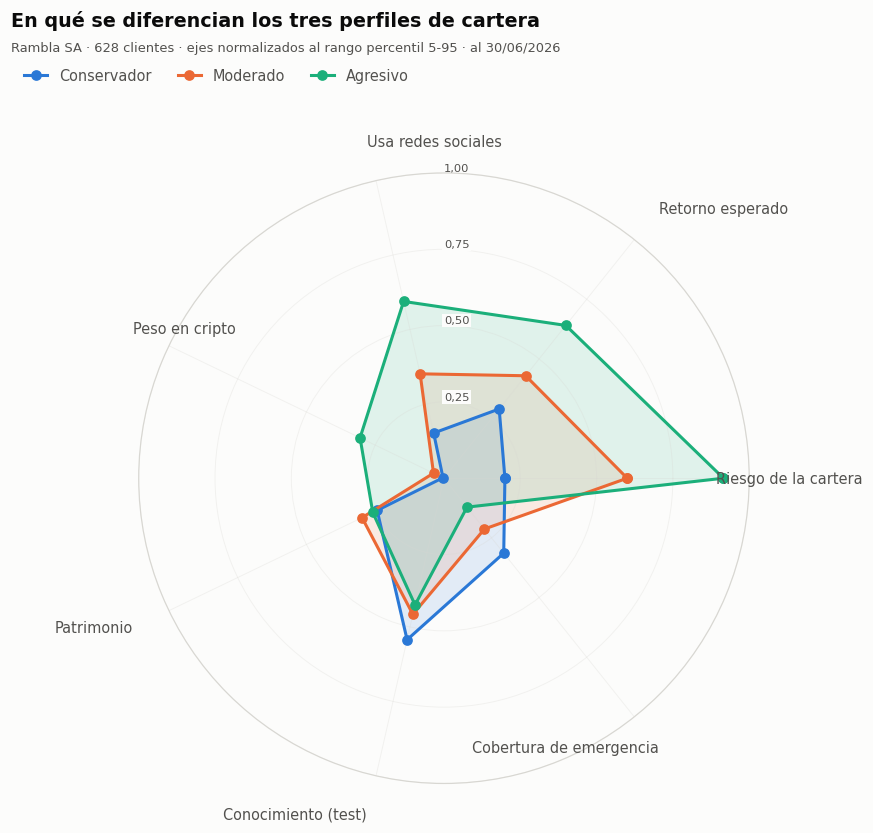

In [74]:
"""Versión estática del mismo radar, para que quede en el repositorio como imagen."""


def radar_matplotlib(promedios: pd.DataFrame, colores: dict[str, str], titulo: str,
                     subtitulo: str, archivo: Path) -> None:
    """Dibuja el mismo radar en matplotlib y lo guarda como PNG.

    Existe porque el visor de notebooks de GitHub no ejecuta JavaScript y por lo tanto no
    muestra las figuras de Plotly. La versión interactiva es la que se usa al correr el
    notebook; esta queda como registro visible en el repositorio.
    """
    ejes = list(promedios.columns)
    angulos = np.linspace(0, 2 * np.pi, len(ejes), endpoint=False).tolist()
    cerrados = angulos + angulos[:1]

    figura, eje = plt.subplots(figsize=(8.2, 7.4), subplot_kw=dict(polar=True))
    for grupo in promedios.index:
        valores = promedios.loc[grupo].tolist()
        valores += valores[:1]
        eje.plot(cerrados, valores, color=colores[grupo], linewidth=2,
                 marker="o", markersize=6, label=str(grupo))
        eje.fill(cerrados, valores, color=colores[grupo], alpha=0.12)

    # Las etiquetas de los vértices se dibujan a mano, fuera del círculo, con la
    # alineación que corresponde a su ángulo. Las automáticas de matplotlib se montan
    # sobre el borde del gráfico y sobre los propios datos.
    eje.set_xticks(angulos)
    eje.set_xticklabels([])
    for angulo, nombre in zip(angulos, ejes):
        grados = np.degrees(angulo)
        if grados < 1 or abs(grados - 180) < 1:
            alineacion = "center"
        else:
            alineacion = "left" if grados < 180 else "right"
        eje.text(angulo, 1.13, nombre, fontsize=9.5, color=TINTA_SECUNDARIA,
                 ha=alineacion, va="center")

    eje.set_ylim(0, 1)
    eje.set_yticks([0.25, 0.5, 0.75, 1.0])
    eje.set_yticklabels(["0,25", "0,50", "0,75", "1,00"], fontsize=7.5,
                        color=TINTA_SECUNDARIA)
    # La escala radial se dibuja sobre los datos, así que se le pone un fondo del color
    # de la superficie para que siga siendo legible.
    for etiqueta in eje.get_yticklabels():
        etiqueta.set_bbox(dict(facecolor=SUPERFICIE, edgecolor="none", pad=1.2))
    eje.set_rlabel_position(90)
    eje.grid(color=GRIS_GRILLA, linewidth=0.6)
    eje.spines["polar"].set_color(GRIS_GRILLA)

    figura.text(0.02, 0.98, titulo, fontsize=12.5, fontweight="semibold",
                color=TINTA_PRIMARIA, ha="left", va="top")
    figura.text(0.02, 0.942, subtitulo, fontsize=8.5, color=TINTA_SECUNDARIA,
                ha="left", va="top")
    # La leyenda va arriba, bajo el subtítulo: abajo se montaba sobre la etiqueta del
    # vértice inferior del polígono.
    figura.legend(*eje.get_legend_handles_labels(), loc="upper left",
                  bbox_to_anchor=(0.02, 0.925), ncol=3, frameon=False,
                  fontsize=9.5, labelcolor=TINTA_SECUNDARIA,
                  handlelength=1.6, columnspacing=1.8)
    figura.subplots_adjust(top=0.78, bottom=0.03, left=0.13, right=0.87)
    figura.savefig(archivo, dpi=150, bbox_inches="tight", facecolor=SUPERFICIE)
    plt.show()


radar_matplotlib(
    promedios_radar, COLOR_PERFIL,
    "En qué se diferencian los tres perfiles de cartera",
    "Rambla SA · 628 clientes · ejes normalizados al rango percentil 5-95 · al 30/06/2026",
    SALIDAS / "4_1_radar_perfiles.png")

> **Conclusión.** Los tres perfiles se separan casi exclusivamente por **comportamiento**:
> riesgo de la cartera, peso en criptomonedas, uso de redes sociales como fuente y retorno
> esperado. En cambio **el patrimonio es prácticamente idéntico en los tres** (USD 18.015,
> 22.665 y 18.146), y el conocimiento financiero apenas se mueve (4,8 · 4,2 · 3,9 sobre 10).
>
> Eso contradice el supuesto con el que la firma venía trabajando: **el perfil de riesgo no
> es una cuestión de cuánta plata tiene el cliente ni de cuánto sabe.** Y el agresivo es,
> además, el que menos colchón de emergencia tiene (1,4 meses de gastos contra 3,5 del
> conservador): corre más riesgo con menos red.

## Gráfico 2 · La brecha entre el perfil declarado y el real

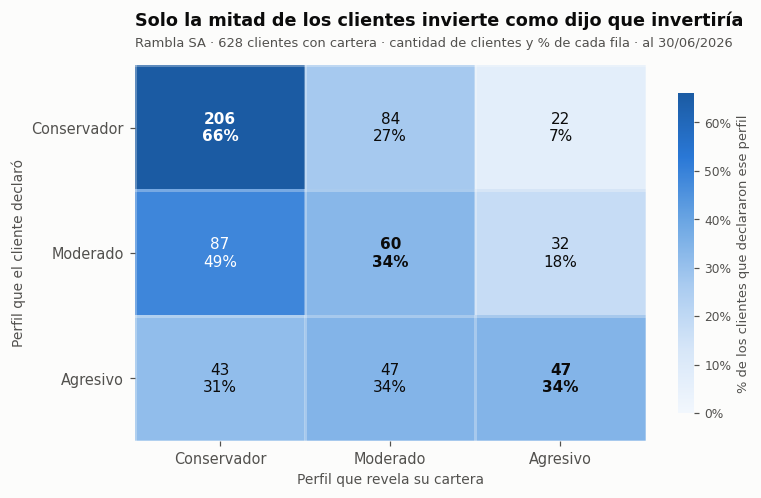

In [75]:
"""Matriz de transición: lo que dijo ser contra lo que su cartera hace."""

matriz_pct = matriz.div(matriz.sum(axis=1), axis=0)

figura, eje = plt.subplots(figsize=(7.2, 4.6))
imagen = eje.imshow(matriz_pct.values, cmap=mcolors.LinearSegmentedColormap.from_list(
    "azules", RAMPA_AZUL), vmin=0, vmax=matriz_pct.values.max(), aspect="auto")

for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        cuenta = matriz.iloc[i, j]
        porcentaje = matriz_pct.iloc[i, j]
        # El texto va en tinta, nunca en el color de la serie; se aclara sobre el fondo oscuro.
        color_texto = "#ffffff" if porcentaje > matriz_pct.values.max() * 0.55 else TINTA_PRIMARIA
        peso = "bold" if i == j else "normal"
        eje.text(j, i, f"{cuenta}\n{porcentaje:.0%}", ha="center", va="center",
                 fontsize=10, color=color_texto, fontweight=peso)

eje.set_xticks(range(3), matriz.columns, fontsize=9.5)
eje.set_yticks(range(3), matriz.index, fontsize=9.5)
eje.set_xlabel("Perfil que revela su cartera")
eje.set_ylabel("Perfil que el cliente declaró")
poner_titulo(eje,
             "Solo la mitad de los clientes invierte como dijo que invertiría",
             "Rambla SA · 628 clientes con cartera · cantidad de clientes y % de cada "
             "fila · al 30/06/2026")

# Separación de 2 px del color de la superficie entre celdas: se dibuja como una grilla
# menor, porque un borde alrededor de cada marca está desaconsejado.
eje.set_xticks(np.arange(-0.5, 3, 1), minor=True)
eje.set_yticks(np.arange(-0.5, 3, 1), minor=True)
eje.grid(which="minor", color=SUPERFICIE, linewidth=2)
eje.grid(which="major", visible=False)
eje.tick_params(which="minor", length=0)
for borde in eje.spines.values():
    borde.set_visible(False)

barra = figura.colorbar(imagen, ax=eje, shrink=0.85)
barra.set_label("% de los clientes que declararon ese perfil", fontsize=8.5,
                color=TINTA_SECUNDARIA)
barra.ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
barra.ax.tick_params(labelsize=8, colors=TINTA_SECUNDARIA)
barra.outline.set_visible(False)
plt.tight_layout()
plt.savefig(SALIDAS / "4_2_brecha_declarado_real.png", dpi=150, bbox_inches="tight",
            facecolor=SUPERFICIE)
plt.show()

> **Conclusión.** La diagonal —donde el cliente invierte como se describió— concentra apenas
> el 49,8 % de los casos, y el kappa ponderado de 0,25 confirma que eso es poco más que
> azar. Las dos esquinas opuestas son los dos problemas de la firma: **22 clientes que se
> dijeron conservadores tienen cartera agresiva** (el riesgo legal, arriba a la derecha) y
> **43 que se dijeron agresivos tienen cartera conservadora** (la oportunidad comercial
> perdida, abajo a la izquierda). Nótese además que la fila del agresivo es la más
> desparramada: de los 137 que se declaran agresivos, apenas 47 lo son.

## Gráfico 3 · La relación que se desarma al controlar

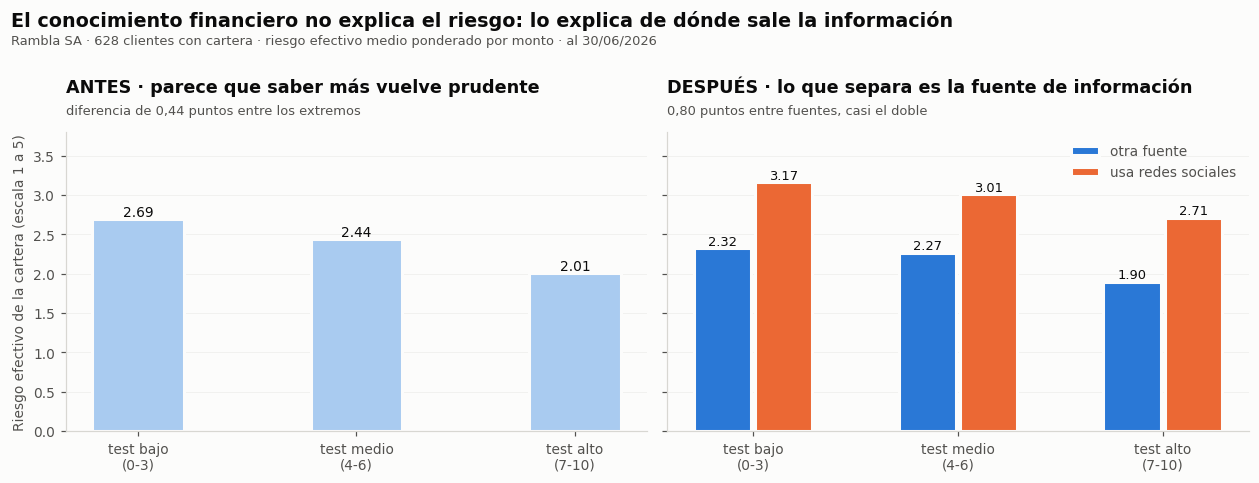

In [76]:
"""Antes y después: el efecto del conocimiento, antes y después de separar por fuente."""

antes = comparables_tabla.groupby("nivel_test", observed=True)["riesgo_efectivo"].mean()
despues = medias  # calculado en 3.3

figura, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)

# --- Antes: una sola serie, sin leyenda (el título la nombra)
ejes_x = np.arange(len(antes))
eje_a.bar(ejes_x, antes.values, width=0.42, color="#a9cbf0",
          edgecolor=SUPERFICIE, linewidth=2)
for x, valor in zip(ejes_x, antes.values):
    eje_a.text(x, valor + 0.04, f"{valor:.2f}", ha="center", fontsize=9,
               color=TINTA_PRIMARIA)
eje_a.set_xticks(ejes_x, [t.replace(" (", "\n(") for t in antes.index], fontsize=9)
eje_a.set_ylabel("Riesgo efectivo de la cartera (escala 1 a 5)")
poner_titulo(eje_a, "ANTES · parece que saber más vuelve prudente",
             "diferencia de 0,44 puntos entre los extremos")
eje_a.set_axisbelow(True)
eje_a.yaxis.grid(True)
eje_a.xaxis.grid(False)

# --- Después: dos series, con leyenda y etiquetas directas
ancho = 0.28
colores_fuente = {"otra fuente": "#2a78d6", "usa redes sociales": "#eb6834"}
for desplazamiento, fuente in zip((-ancho / 2 - 0.01, ancho / 2 + 0.01), despues.columns):
    eje_b.bar(ejes_x + desplazamiento, despues[fuente].values, width=ancho,
              color=colores_fuente[fuente], edgecolor=SUPERFICIE, linewidth=2,
              label=fuente)
    for x, valor in zip(ejes_x + desplazamiento, despues[fuente].values):
        eje_b.text(x, valor + 0.04, f"{valor:.2f}", ha="center", fontsize=8.5,
                   color=TINTA_PRIMARIA)

eje_b.set_xticks(ejes_x, [t.replace(" (", "\n(") for t in despues.index], fontsize=9)
poner_titulo(eje_b, "DESPUÉS · lo que separa es la fuente de información",
             "0,80 puntos entre fuentes, casi el doble")
eje_b.legend(frameon=False, fontsize=9, labelcolor=TINTA_SECUNDARIA, loc="upper right")
eje_b.set_axisbelow(True)
eje_b.yaxis.grid(True)
eje_b.xaxis.grid(False)
eje_b.set_ylim(0, 3.8)

figura.text(0.01, 0.985, "El conocimiento financiero no explica el riesgo: lo explica de "
                         "dónde sale la información",
            fontsize=12.5, fontweight="semibold", ha="left", va="top",
            color=TINTA_PRIMARIA)
figura.text(0.01, 0.935, "Rambla SA · 628 clientes con cartera · riesgo efectivo medio "
                         "ponderado por monto · al 30/06/2026",
            fontsize=8.5, color=TINTA_SECUNDARIA, ha="left", va="top")
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.savefig(SALIDAS / "4_3_relacion_que_se_desarma.png", dpi=150, bbox_inches="tight",
            facecolor=SUPERFICIE)
plt.show()

> **Conclusión.** En el panel izquierdo la relación parece clara y tranquilizadora: a mayor
> puntaje en el test de educación financiera, menor riesgo de cartera. En el derecho, el
> mismo corte separado por fuente de información muestra que **la brecha entre quien se
> informa por redes sociales y quien no (0,80 puntos) casi duplica la que hay entre saber
> poco y saber mucho (0,44 puntos)**, y que dentro de cada fuente el efecto del conocimiento
> casi desaparece. El test de diez preguntas no estaba midiendo prudencia: estaba midiendo,
> de refilón, quién se informa por redes.

## Gráfico 4 · Lo que esperan ganar contra lo que efectivamente ganan

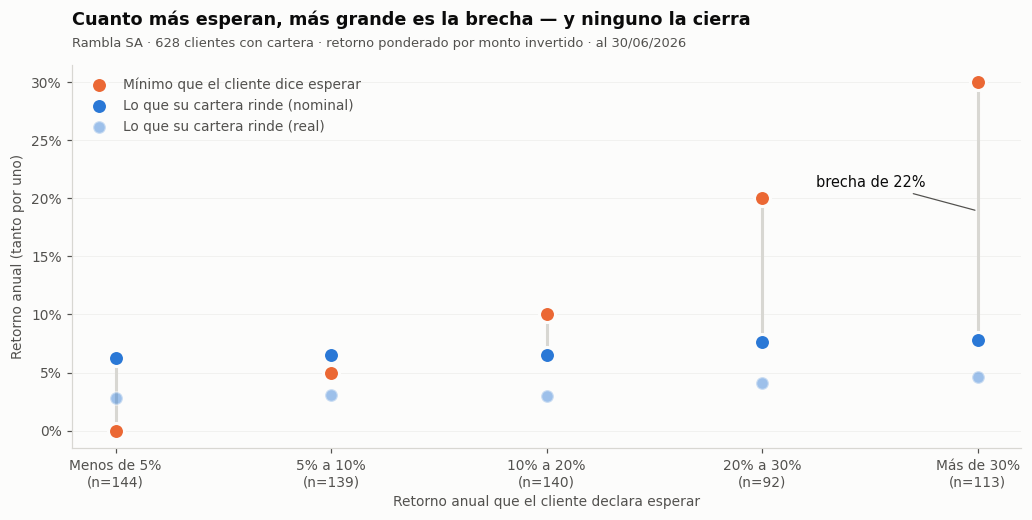

,clientes,piso_esperado,rinde_nominal,rinde_real,brecha
retorno_esperado_anual,,,,,
Menos de 5%,144,0%,6.28%,2.78%,-6.28%
5% a 10%,139,5%,6.50%,3.10%,-1.50%
10% a 20%,140,10%,6.54%,2.99%,+3.46%
20% a 30%,92,20%,7.66%,4.11%,+12.34%
Más de 30%,113,30%,7.83%,4.65%,+22.17%


In [77]:
"""Brecha entre el retorno esperado declarado y el que rinde la cartera."""

tramos = expectativas.dropna(subset=["rinde_nominal"])
ejes_x = np.arange(len(tramos))

figura, eje = plt.subplots(figsize=(9.5, 4.8))

# Línea de conexión (el "salto" entre lo esperado y lo obtenido) y los dos extremos.
for x, (piso, rinde) in enumerate(zip(tramos["piso_esperado"], tramos["rinde_nominal"])):
    eje.plot([x, x], [rinde, piso], color=GRIS_GRILLA, linewidth=2, zorder=1,
             solid_capstyle="round")

eje.scatter(ejes_x, tramos["piso_esperado"], s=110, color="#eb6834", zorder=3,
            label="Mínimo que el cliente dice esperar", edgecolor=SUPERFICIE, linewidth=2)
eje.scatter(ejes_x, tramos["rinde_nominal"], s=110, color="#2a78d6", zorder=3,
            label="Lo que su cartera rinde (nominal)", edgecolor=SUPERFICIE, linewidth=2)
eje.scatter(ejes_x, tramos["rinde_real"], s=70, color="#2a78d6", zorder=3, alpha=0.45,
            label="Lo que su cartera rinde (real)", edgecolor=SUPERFICIE, linewidth=1.5)

# Etiqueta directa sólo en el tramo que importa: el más exigente.
peor = len(tramos) - 1
eje.annotate(f"brecha de {tramos['brecha'].iloc[peor]:.0%}",
             xy=(peor, (tramos["piso_esperado"].iloc[peor] + tramos["rinde_nominal"].iloc[peor]) / 2),
             xytext=(peor - 0.75, 0.21), fontsize=9.5, color=TINTA_PRIMARIA,
             arrowprops=dict(arrowstyle="-", color=TINTA_SECUNDARIA, linewidth=0.8))

eje.set_xticks(ejes_x, [f"{t}\n(n={int(c)})" for t, c in
                            zip(tramos.index, tramos["clientes"])], fontsize=9)
eje.set_xlabel("Retorno anual que el cliente declara esperar")
eje.set_ylabel("Retorno anual (tanto por uno)")
eje.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
poner_titulo(eje,
             "Cuanto más esperan, más grande es la brecha — y ninguno la cierra",
             "Rambla SA · 628 clientes con cartera · retorno ponderado por monto "
             "invertido · al 30/06/2026")
eje.legend(frameon=False, fontsize=9, labelcolor=TINTA_SECUNDARIA, loc="upper left")
eje.set_axisbelow(True)
eje.yaxis.grid(True)
eje.xaxis.grid(False)
plt.tight_layout()
plt.savefig(SALIDAS / "4_4_expectativas_contra_realidad.png", dpi=150,
            bbox_inches="tight", facecolor=SUPERFICIE)
plt.show()

display(tramos[["clientes", "piso_esperado", "rinde_nominal", "rinde_real", "brecha"]]
        .style.format({"piso_esperado": "{:.0%}", "rinde_nominal": "{:.2%}",
                       "rinde_real": "{:.2%}", "brecha": "{:+.2%}"}))

> **Conclusión.** La brecha no es pareja: **se abre a medida que sube la expectativa.** Quien
> dice esperar menos de 5 % obtiene 6,3 % y supera su propia meta; quien dice esperar más de
> 30 % obtiene 7,8 % nominal y 4,7 % real, una brecha de 22 puntos porcentuales que
> **ninguno de los 113 clientes de ese tramo cierra**. Y no es un problema de armar mal la
> cartera: ni una cartera 100 % en criptomonedas —el instrumento más rentable del catálogo,
> con 21,5 % real— alcanzaría ese número. La expectativa no es ambiciosa, es imposible, y
> gestionarla es una tarea de asesoramiento antes que de selección de instrumentos.

## Gráfico 5 · De qué está hecha la cartera de cada perfil

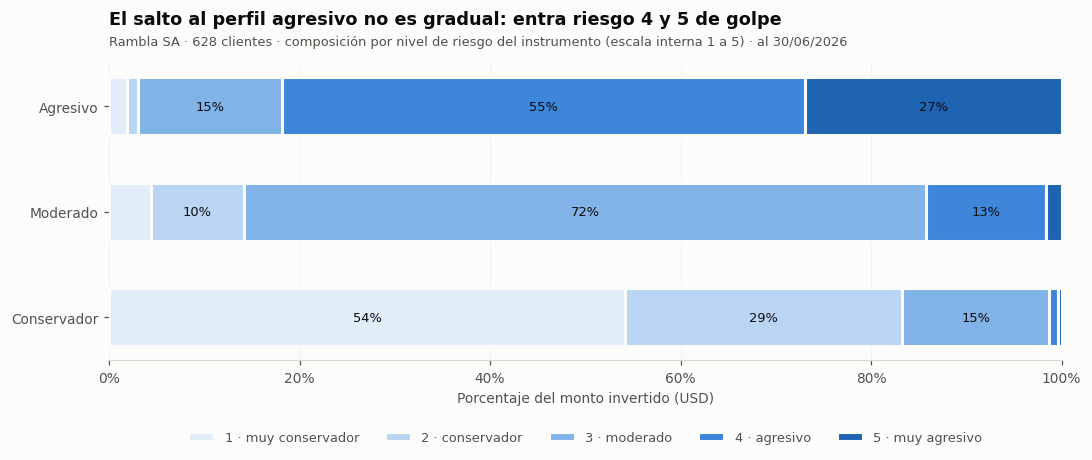

,1 · muy conservador,2 · conservador,3 · moderado,4 · agresivo,5 · muy agresivo
perfil_real,,,,,
Conservador,54.2%,29.1%,15.4%,0.9%,0.4%
Moderado,4.3%,9.8%,71.6%,12.6%,1.7%
Agresivo,1.9%,1.1%,15.1%,54.9%,27.0%


Detalle por familia de activo, que el gráfico resume en cinco niveles:


categoria,Efectivo,Renta fija local,Fondos,Inmobiliario,Renta fija corporativa,Previsional,Materias primas,Renta variable,Cripto
perfil_real,,,,,,,,,
Conservador,6.7%,59.9%,16.7%,1.5%,5.9%,8.0%,0.3%,0.7%,0.2%
Moderado,0.5%,10.5%,3.3%,7.0%,39.2%,25.4%,8.4%,4.7%,1.2%
Agresivo,0.1%,2.6%,0.4%,0.0%,7.7%,7.4%,33.1%,37.1%,11.6%


Y la otra cara del riesgo, que la escala de la firma no mide: la liquidez.


liquidez,Alta,Media,Baja,Muy baja
perfil_real,,,,
Conservador,24.3%,19.5%,43.7%,12.5%
Moderado,9.5%,15.1%,20.9%,54.4%
Agresivo,49.2%,35.3%,3.1%,12.4%


In [78]:
"""Composición de la cartera por familia de activo y perfil."""

# Cada posición hereda el perfil real del cliente que la tiene.
posiciones_con_perfil = posiciones.assign(
    perfil_real=posiciones["id_cliente"].map(comparables["perfil_real"].astype(str)))
posiciones_con_perfil = posiciones_con_perfil[posiciones_con_perfil["perfil_real"].notna()]

# Se agrupa por NIVEL DE RIESGO del instrumento (1 a 5) y no por familia de activo.
# El catálogo tiene nueve familias, y nueve clases de color en una rampa de un solo tono
# son indistinguibles: pasado el séptimo escalón las clases contiguas se confunden. El
# nivel de riesgo, en cambio, es una escala ordenada de cinco pasos, que es exactamente lo
# que una rampa secuencial puede representar bien, y además es la variable sobre la que
# está construido todo el proyecto. El detalle por familia queda en la tabla de abajo.
ETIQUETA_RIESGO = {1: "1 · muy conservador", 2: "2 · conservador", 3: "3 · moderado",
                   4: "4 · agresivo", 5: "5 · muy agresivo"}

composicion_perfil = (posiciones_con_perfil
                      .groupby(["perfil_real", "nivel_riesgo"], observed=True)["monto_cartera"]
                      .sum().unstack(fill_value=0))
composicion_perfil = composicion_perfil.div(composicion_perfil.sum(axis=1), axis=0)
composicion_perfil = composicion_perfil.reindex(ETIQUETAS_PERFIL).sort_index(axis=1)
composicion_perfil.columns = [ETIQUETA_RIESGO[n] for n in composicion_perfil.columns]

# Rampa secuencial de un solo tono, clara a oscura: el nivel de riesgo es una magnitud.
rampa = mcolors.LinearSegmentedColormap.from_list("azules", RAMPA_AZUL)
colores_familia = {nivel: rampa(0.12 + 0.82 * i / (len(composicion_perfil.columns) - 1))
                   for i, nivel in enumerate(composicion_perfil.columns)}

figura, eje = plt.subplots(figsize=(10, 4.4))
izquierda = np.zeros(len(composicion_perfil))
for familia in composicion_perfil.columns:
    valores = composicion_perfil[familia].values
    eje.barh(composicion_perfil.index, valores, left=izquierda, height=0.55,
             color=colores_familia[familia], label=familia,
             edgecolor=SUPERFICIE, linewidth=2)       # 2px de separación entre segmentos
    # Etiqueta dentro del segmento sólo si entra con holgura.
    for y, (valor, base) in enumerate(zip(valores, izquierda)):
        if valor >= 0.09:
            eje.text(base + valor / 2, y, f"{valor:.0%}", ha="center", va="center",
                     fontsize=8.5, color=TINTA_PRIMARIA)
    izquierda += valores

eje.set_xlim(0, 1)
eje.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
eje.set_xlabel("Porcentaje del monto invertido (USD)")
poner_titulo(eje,
             "El salto al perfil agresivo no es gradual: entra riesgo 4 y 5 de golpe",
             "Rambla SA · 628 clientes · composición por nivel de riesgo del instrumento "
             "(escala interna 1 a 5) · al 30/06/2026")
eje.legend(frameon=False, fontsize=8.5, labelcolor=TINTA_SECUNDARIA, ncol=5,
           loc="upper center", bbox_to_anchor=(0.5, -0.20))
eje.set_axisbelow(True)
eje.xaxis.grid(True)
eje.yaxis.grid(False)
for borde in ["top", "right", "left"]:
    eje.spines[borde].set_visible(False)
plt.tight_layout()
plt.savefig(SALIDAS / "4_5_composicion_por_perfil.png", dpi=150, bbox_inches="tight",
            facecolor=SUPERFICIE)
plt.show()

display(composicion_perfil.style.format("{:.1%}"))

print("Detalle por familia de activo, que el gráfico resume en cinco niveles:")
detalle_familias = (posiciones_con_perfil
                    .groupby(["perfil_real", "categoria"], observed=True)["monto_cartera"]
                    .sum().unstack(fill_value=0))
detalle_familias = (detalle_familias.div(detalle_familias.sum(axis=1), axis=0)
                    .reindex(ETIQUETAS_PERFIL))
orden_familias = (catalogo.groupby("categoria")["nivel_riesgo"].mean()
                  .sort_values().index.tolist())
detalle_familias = detalle_familias[[c for c in orden_familias
                                     if c in detalle_familias.columns]]
display(detalle_familias.style.format("{:.1%}"))

# El nivel de riesgo mide variación de precio, no la facilidad para salir. Son dos
# riesgos distintos y conviene mirarlos juntos.
print("Y la otra cara del riesgo, que la escala de la firma no mide: la liquidez.")
ORDEN_LIQUIDEZ = ["Alta", "Media", "Baja", "Muy baja"]
liquidez_perfil = (posiciones_con_perfil
                   .groupby(["perfil_real", "liquidez"], observed=True)["monto_cartera"]
                   .sum().unstack(fill_value=0))
liquidez_perfil = (liquidez_perfil.div(liquidez_perfil.sum(axis=1), axis=0)
                   .reindex(index=ETIQUETAS_PERFIL)
                   [[c for c in ORDEN_LIQUIDEZ if c in liquidez_perfil.columns]])
display(liquidez_perfil.style.format("{:.1%}"))

> **Conclusión.** Cada perfil tiene un nivel de riesgo dominante y la transición no es
> gradual: el conservador concentra el 54 % en instrumentos de riesgo 1, el moderado el
> 72 % en riesgo 3, y el agresivo salta a **55 % en riesgo 4 y 27 % en riesgo 5**. No hay
> carteras intermedias que mezclen de a poco: los clientes se mueven de bloque en bloque.
>
> **Y la tabla de liquidez muestra algo que ningún otro cruce dejó ver: el perfil más
> ilíquido no es el agresivo, es el moderado.** Tiene el **54,4 % de su cartera en
> instrumentos de liquidez muy baja** —fideicomisos, ahorro en AFAP e inmuebles— contra
> 12,5 % del conservador y 12,4 % del agresivo. El agresivo, en cambio, tiene casi la mitad
> en instrumentos de liquidez alta, porque las acciones, los ETF y las criptomonedas se
> venden en el día.
>
> Es un riesgo que la escala 1 a 5 de la firma **no mide**, porque mide variación de precio
> y no facilidad para salir. Un cliente moderado que necesite su plata de golpe está peor
> parado que uno agresivo, aunque su cartera figure como de menor riesgo. Esto entra
> directo en las carteras modelo de la Etapa 5.

## Gráfico 6 · Una distribución donde el promedio y la mediana cuentan historias distintas

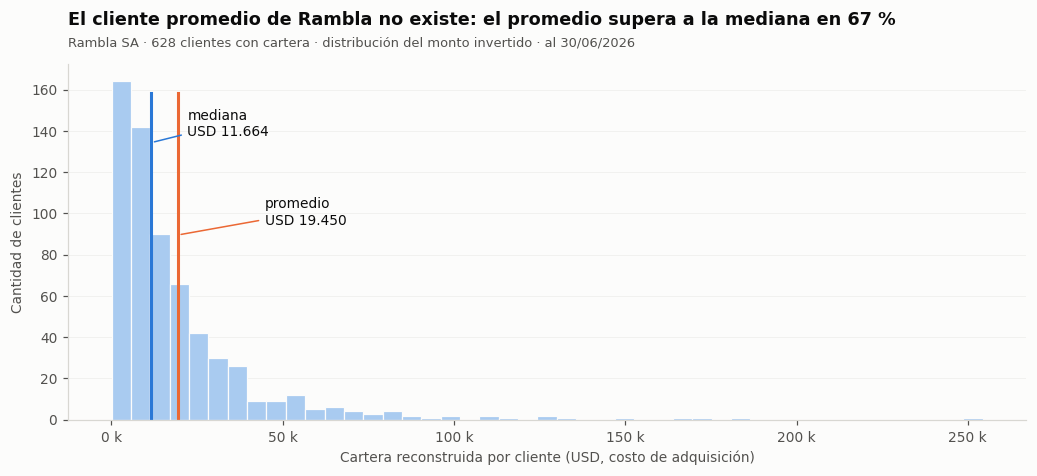

,patrimonio_usd
percentil 10,"2,138"
percentil 25,"5,266"
percentil 50,"11,664"
percentil 75,"23,430"
percentil 90,"42,518"
percentil 95,"63,092"
percentil 99,"126,823"


El 10 % de clientes más grandes concentra el 40% del patrimonio total.
Clientes por debajo del promedio: 69%


In [79]:
"""Distribución del patrimonio: el promedio no describe al cliente típico."""

patrimonios = comparables["cartera_usd"]
media, mediana = patrimonios.mean(), patrimonios.median()

figura, eje = plt.subplots(figsize=(9.5, 4.4))
eje.hist(patrimonios, bins=45, color="#a9cbf0", edgecolor=SUPERFICIE, linewidth=0.8)

# ymax recorta las verticales dentro del area de datos: sin eso se montan sobre el titulo.
eje.axvline(mediana, color="#2a78d6", linewidth=2, ymax=0.92)
eje.axvline(media, color="#eb6834", linewidth=2, ymax=0.92)
eje.annotate(f"mediana\nUSD {formato_es(mediana)}", xy=(mediana, eje.get_ylim()[1] * 0.78),
             xytext=(mediana * 1.9, eje.get_ylim()[1] * 0.80), fontsize=9,
             color=TINTA_PRIMARIA,
             arrowprops=dict(arrowstyle="-", color="#2a78d6", linewidth=1))
eje.annotate(f"promedio\nUSD {formato_es(media)}", xy=(media, eje.get_ylim()[1] * 0.52),
             xytext=(media * 2.3, eje.get_ylim()[1] * 0.55), fontsize=9,
             color=TINTA_PRIMARIA,
             arrowprops=dict(arrowstyle="-", color="#eb6834", linewidth=1))

eje.set_xlabel("Cartera reconstruida por cliente (USD, costo de adquisición)")
eje.set_ylabel("Cantidad de clientes")
eje.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f"{formato_es(v / 1000)} k"))
poner_titulo(eje,
             "El cliente promedio de Rambla no existe: el promedio supera a la mediana en 67 %",
             "Rambla SA · 628 clientes con cartera · distribución del monto invertido · "
             "al 30/06/2026")
eje.set_axisbelow(True)
eje.yaxis.grid(True)
eje.xaxis.grid(False)
plt.tight_layout()
plt.savefig(SALIDAS / "4_6_distribucion_patrimonio.png", dpi=150, bbox_inches="tight",
            facecolor=SUPERFICIE)
plt.show()

decilicos = pd.DataFrame({
    "patrimonio_usd": patrimonios.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]),
})
decilicos.index = [f"percentil {int(p * 100)}" for p in decilicos.index]
display(decilicos.style.format("{:,.0f}"))

decil_superior = patrimonios.nlargest(int(len(patrimonios) * 0.1)).sum()
print(f"El 10 % de clientes más grandes concentra el "
      f"{decil_superior / patrimonios.sum():.0%} del patrimonio total.")
print(f"Clientes por debajo del promedio: "
      f"{(patrimonios < media).mean():.0%}")

> **Conclusión.** La cartera promedio es de USD 19.450 pero la mediana es de USD 11.664: el
> promedio está **67 % por encima** del cliente típico, y **el 68 % de los clientes está por
> debajo del promedio**. La distribución tiene una cola larga a la derecha —el decil superior
> concentra alrededor del 40 % del patrimonio— y por eso cualquier política construida sobre
> el «cliente promedio» se diseña para alguien que casi no existe. Para dimensionar carteras
> modelo hay que usar la mediana y los percentiles; el promedio sólo sirve para calcular el
> total administrado.

---
## Nota sobre los gráficos interactivos y GitHub

El gráfico 1 está hecho con **Plotly** y es interactivo: al pasar el mouse por cada vértice
muestra la dimensión, el perfil y el valor normalizado.

**El visor de notebooks de GitHub no ejecuta JavaScript**, así que al abrir el `.ipynb`
directamente en el navegador de GitHub ese gráfico aparece vacío. No es un error del
notebook. Por eso se lo guarda de dos formas en `salidas/`:

- `4_1_radar_perfiles.html` — la versión interactiva, que se abre en cualquier navegador;
- `4_1_radar_perfiles.png` — la misma figura en estático, visible en el repositorio.

Corriendo el notebook localmente, la versión interactiva se ve sin problemas.